<a href="https://colab.research.google.com/github/danessia19/EMG_Pipeline/blob/main/EMG_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install neurokit2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.1/693.1 kB 7.4 MB/s  0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as signal
import neurokit2 as nk
import json

from scipy.signal import butter, sosfiltfilt, welch
from scipy.ndimage import uniform_filter1d

In [3]:
from google.colab import files

uploaded = files.upload()

Saving Trial_3.csv to Trial_3 (1).csv


In [4]:
import os

print(os.listdir('/content'))

['.config', 'Trial_3.csv', 'carlie_pilot3_pilot.csv', 'Trial_3 (1).csv', 'sample_data']


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

behavior = pd.read_csv(
    "/content/carlie_pilot3_pilot.csv"
)

display(behavior.head(10))

,thisRow.t,notes,phase,block,sd,distance,calibration_presses,calibrated_max,mapping,trial,...,presses,success,predicted_success,assessment_index,choice,correct,rt,interoceptive_index,target_mean,Unnamed: 22
0,NaN,NaN,calibration,1,6,0.35,22.0,17.6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,learning,1,6,0.35,NaN,17.6,stim2_high,1.0,...,20.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,learning,1,6,0.35,NaN,17.6,stim2_high,2.0,...,20.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,learning,1,6,0.35,NaN,17.6,stim2_high,3.0,...,19.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,learning,1,6,0.35,NaN,17.6,stim2_high,4.0,...,19.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,learning,1,6,0.35,NaN,17.6,stim2_high,5.0,...,18.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,learning,1,6,0.35,NaN,17.6,stim2_high,6.0,...,18.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,assessment,1,6,0.35,NaN,17.6,stim2_high,6.0,...,NaN,NaN,NaN,1.0,1.0,0.0,4.882941,NaN,NaN,NaN
8,NaN,NaN,learning,1,6,0.35,NaN,17.6,stim2_high,7.0,...,20.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,learning,1,6,0.35,NaN,17.6,stim2_high,8.0,...,19.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print(behavior.shape)
print(behavior.columns.tolist())
print(behavior["phase"].value_counts())

(42, 23)
['thisRow.t', 'notes', 'phase', 'block', 'sd', 'distance', 'calibration_presses', 'calibrated_max', 'mapping', 'trial', 'trial_in_block', 'stimID', 'threshold', 'presses', 'success', 'predicted_success', 'assessment_index', 'choice', 'correct', 'rt', 'interoceptive_index', 'target_mean', 'Unnamed: 22']
phase
learning         30
interoceptive     6
assessment        5
calibration       1
Name: count, dtype: int64


In [7]:
column_names = [
    "Soleus_Time", "Soleus_EMG",
    "TibAnt_Time", "TibAnt_EMG",
    "GastrocMed_Time", "GastrocMed_EMG",
    "VastusMed_Time", "VastusMed_EMG",
    "RectusFem_Time", "RectusFem_EMG"
]

emg_data = pd.read_csv(
    "/content/Trial_3.csv",
    skiprows=7,
    header=None,
    names=column_names,
    skipinitialspace=True
)

display(emg_data.head(10))

,Soleus_Time,Soleus_EMG,TibAnt_Time,TibAnt_EMG,GastrocMed_Time,GastrocMed_EMG,VastusMed_Time,VastusMed_EMG,RectusFem_Time,RectusFem_EMG
0,0.000243,0.002518,0.000243,0.026017,0.000243,-0.017288,0.000243,-0.015442,0.000243,0.001511
1,0.000709,0.001175,0.000709,0.028031,0.000709,-0.019303,0.000709,-0.014939,0.000709,-0.001007
2,0.001174,-0.000168,0.001174,0.028534,0.001174,-0.020981,0.001174,-0.015610,0.001174,-0.002182
3,0.001640,0.000839,0.001640,0.029374,0.001640,-0.018296,0.001640,-0.016953,0.001640,-0.003525
4,0.002106,0.002518,0.002106,0.031388,0.002106,-0.016281,0.002106,-0.017792,0.002106,-0.005036
5,0.002571,0.004364,0.002571,0.033066,0.002571,-0.017624,0.002571,-0.017792,0.002571,-0.005036
6,0.003037,0.006210,0.003037,0.034745,0.003037,-0.020646,0.003037,-0.017624,0.003037,-0.002853
7,0.003502,0.006882,0.003502,0.033402,0.003502,-0.020981,0.003502,-0.017288,0.003502,-0.001679
8,0.003968,0.004868,0.003968,0.029374,0.003968,-0.018967,0.003968,-0.017624,0.003968,-0.002182
9,0.004433,0.001511,0.004433,0.026352,0.004433,-0.016281,0.004433,-0.016281,0.004433,-0.001846


In [8]:
print("Data dimensions:")
print(emg_data.shape)

print("\nColumn names:")
print(emg_data.columns.tolist())

print("\nMissing values:")
print(emg_data.isnull().sum())

Data dimensions:
(2228044, 10)

Column names:
['Soleus_Time', 'Soleus_EMG', 'TibAnt_Time', 'TibAnt_EMG', 'GastrocMed_Time', 'GastrocMed_EMG', 'VastusMed_Time', 'VastusMed_EMG', 'RectusFem_Time', 'RectusFem_EMG']

Missing values:
Soleus_Time        0
Soleus_EMG         0
TibAnt_Time        0
TibAnt_EMG         0
GastrocMed_Time    0
GastrocMed_EMG     0
VastusMed_Time     0
VastusMed_EMG      0
RectusFem_Time     0
RectusFem_EMG      0
dtype: int64


In [9]:
fs = 2148.1481

# Verify using the Soleus timestamps
timestamps = emg_data["Soleus_Time"].to_numpy()

dt = np.diff(timestamps)

fs_estimated = 1 / np.median(dt)

print("Reported sampling frequency:", fs, "Hz")
print("Estimated sampling frequency:", fs_estimated, "Hz")
print("Non-increasing timestamps:", np.sum(dt <= 0))

Reported sampling frequency: 2148.1481 Hz
Estimated sampling frequency: 2148.227712052401 Hz
Non-increasing timestamps: 0


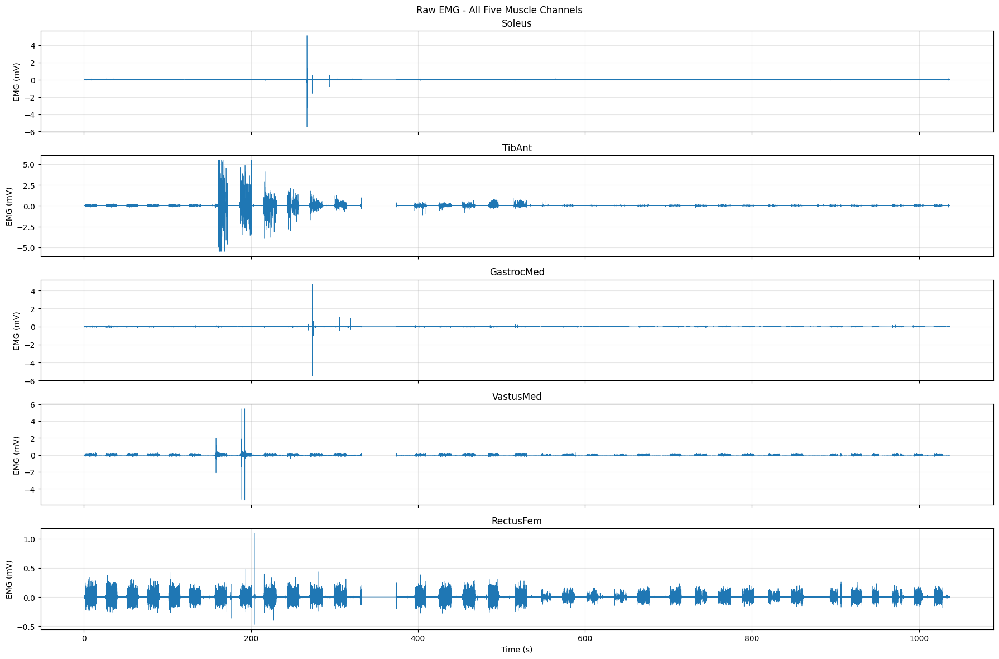

In [10]:
muscles = [
    "Soleus",
    "TibAnt",
    "GastrocMed",
    "VastusMed",
    "RectusFem"
]

fig, ax = plt.subplots(
    5, 1,
    figsize=(18, 12),
    sharex=True
)

for i, muscle in enumerate(muscles):

    ax[i].plot(
        emg_data[f"{muscle}_Time"],
        emg_data[f"{muscle}_EMG"],
        linewidth=0.5
    )

    ax[i].set_title(muscle)
    ax[i].set_ylabel("EMG (mV)")
    ax[i].grid(alpha=0.3)

ax[-1].set_xlabel("Time (s)")

plt.suptitle("Raw EMG - All Five Muscle Channels")
plt.tight_layout()
plt.show()

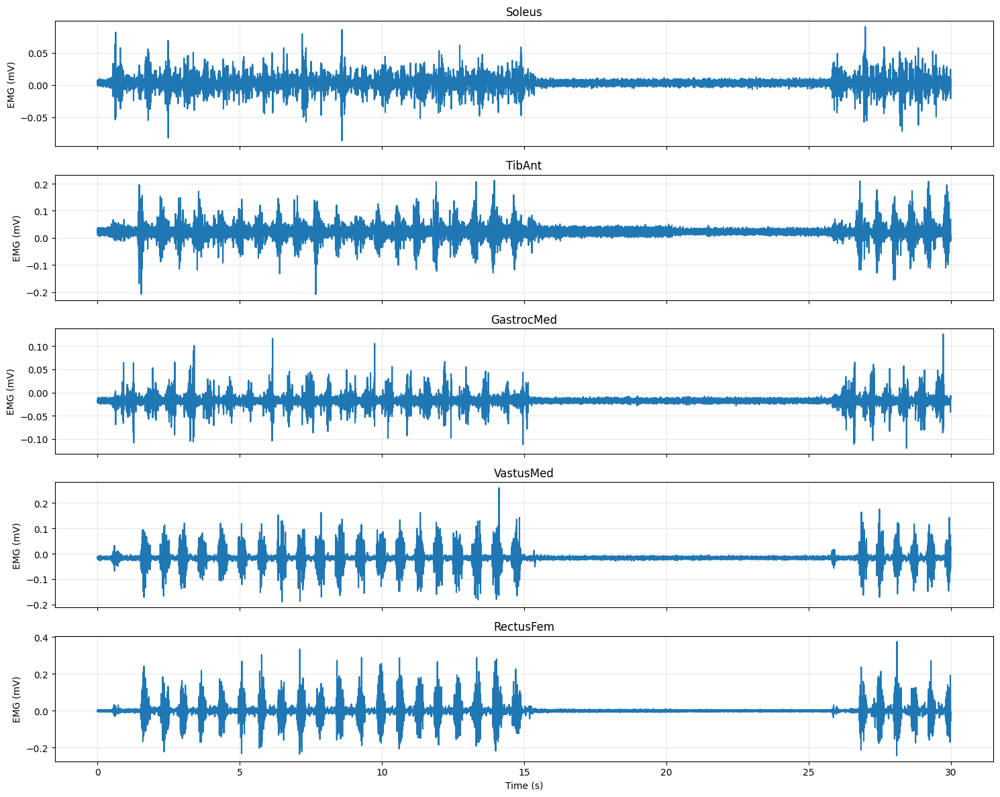

In [11]:
start_time = 0
end_time = 30

fig, ax = plt.subplots(
    5, 1,
    figsize=(15, 12),
    sharex=True
)

for i, muscle in enumerate(muscles):

    t = emg_data[f"{muscle}_Time"]
    emg = emg_data[f"{muscle}_EMG"]

    mask = (t >= start_time) & (t < end_time)

    ax[i].plot(t[mask], emg[mask])

    ax[i].set_title(muscle)
    ax[i].set_ylabel("EMG (mV)")
    ax[i].grid(alpha=0.3)

ax[-1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

In [12]:
from scipy.signal import welch, butter, sosfiltfilt
from scipy.ndimage import uniform_filter1d

fs = 2148.1481

muscle = "RectusFem"

time = emg_data[f"{muscle}_Time"].to_numpy(dtype=float)
emg_raw = emg_data[f"{muscle}_EMG"].to_numpy(dtype=float)

print("Muscle:", muscle)
print("Number of samples:", len(emg_raw))
print("Sampling frequency:", fs)
print("Recording duration:", time[-1] - time[0])
print("Invalid EMG samples:", np.sum(~np.isfinite(emg_raw)))

Muscle: RectusFem
Number of samples: 2228044
Sampling frequency: 2148.1481
Recording duration: 1037.1924311
Invalid EMG samples: 0


In [13]:
dt = np.diff(time)

print("Median sampling interval:", np.median(dt))
print("Non-increasing timestamps:", np.sum(dt <= 0))
print("Potential sampling gaps:",
      np.sum(dt > 1.5 / fs))

Median sampling interval: 0.0004655000000184373
Non-increasing timestamps: 0
Potential sampling gaps: 0


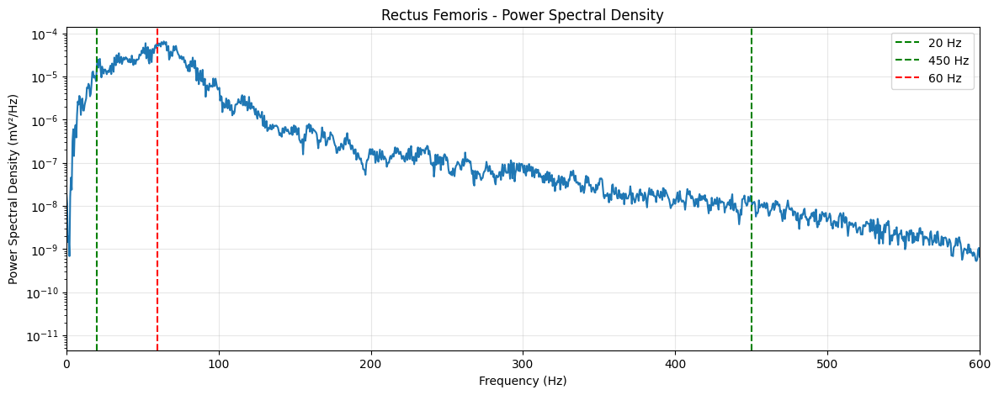

In [14]:
# Representative biking period
mask = (time >= 2) & (time < 14)

emg_segment = emg_raw[mask]

# Calculate PSD using Welch's method
frequencies, psd = welch(
    emg_segment,
    fs=fs,
    nperseg=round(2 * fs)
)

plt.figure(figsize=(14, 5))

plt.semilogy(frequencies, psd)

plt.axvline(20, color="green",
            linestyle="--", label="20 Hz")

plt.axvline(450, color="green",
            linestyle="--", label="450 Hz")

plt.axvline(60, color="red",
            linestyle="--", label="60 Hz")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density (mV²/Hz)")
plt.title("Rectus Femoris - Power Spectral Density")

plt.xlim(0, 600)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
lowcut = 20
highcut = 450

sos = butter(
    4,
    [lowcut, highcut],
    btype="bandpass",
    fs=fs,
    output="sos"
)

emg_filtered = sosfiltfilt(sos, emg_raw)

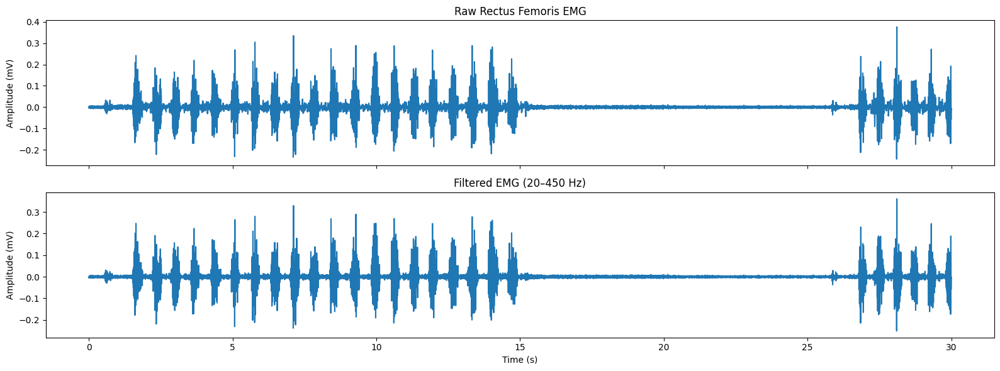

In [16]:
mask = (time >= 0) & (time < 30)

fig, ax = plt.subplots(
    2, 1, figsize=(16, 6), sharex=True
)

ax[0].plot(time[mask], emg_raw[mask])
ax[0].set_title("Raw Rectus Femoris EMG")
ax[0].set_ylabel("Amplitude (mV)")

ax[1].plot(time[mask], emg_filtered[mask])
ax[1].set_title("Filtered EMG (20–450 Hz)")
ax[1].set_ylabel("Amplitude (mV)")
ax[1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

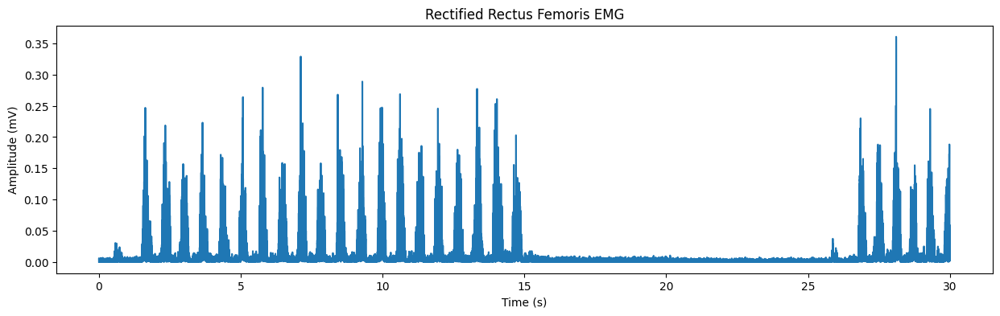

In [17]:
emg_rectified = np.abs(emg_filtered)

plt.figure(figsize=(15, 4))

plt.plot(
    time[mask],
    emg_rectified[mask]
)

plt.title("Rectified Rectus Femoris EMG")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.show()

In [18]:
window_sizes = [25, 50, 100]

rms_results = {}

for window_ms in window_sizes:

    window_samples = max(
        1, round(window_ms * fs / 1000)
    )

    mean_squared = uniform_filter1d(
        emg_filtered**2,
        size=window_samples
    )

    rms_results[window_ms] = np.sqrt(
        np.maximum(mean_squared, 0)
    )

    print(
        f"{window_ms} ms = {window_samples} samples"
    )

25 ms = 54 samples
50 ms = 107 samples
100 ms = 215 samples


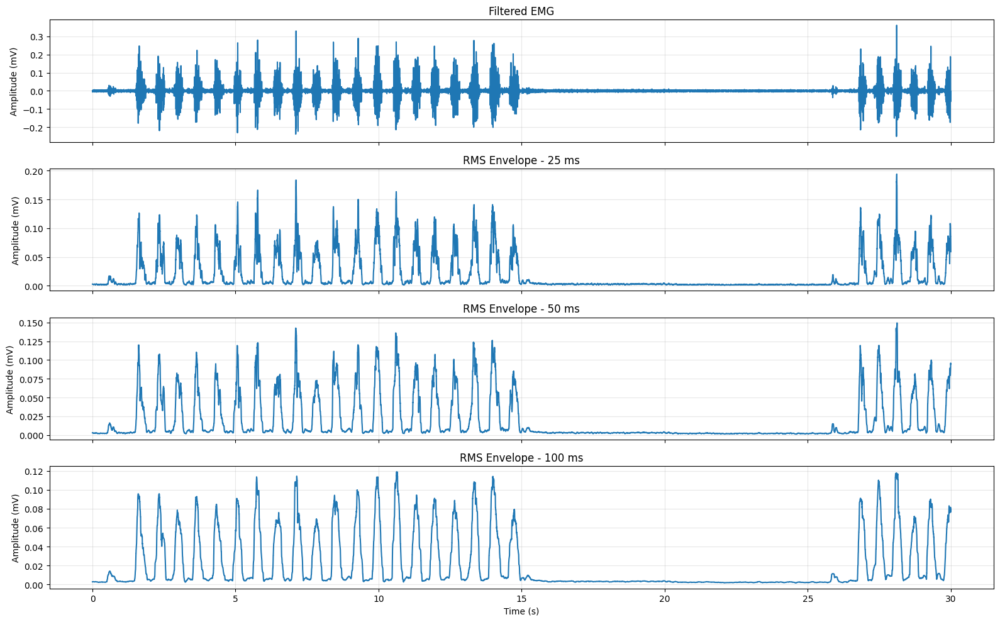

In [19]:
fig, ax = plt.subplots(
    4, 1, figsize=(16, 10), sharex=True
)

ax[0].plot(time[mask], emg_filtered[mask])
ax[0].set_title("Filtered EMG")

for i, window_ms in enumerate(window_sizes):

    ax[i+1].plot(
        time[mask],
        rms_results[window_ms][mask]
    )

    ax[i+1].set_title(
        f"RMS Envelope - {window_ms} ms"
    )

for axis in ax:
    axis.set_ylabel("Amplitude (mV)")
    axis.grid(alpha=0.3)

ax[-1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

Index(['EMG_Raw', 'EMG_Clean', 'EMG_Amplitude', 'EMG_Activity', 'EMG_Onsets',
       'EMG_Offsets'],
      dtype='object')


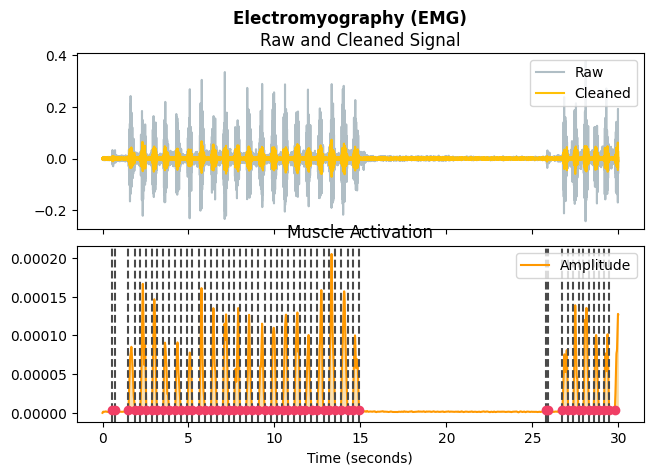

In [20]:
import neurokit2 as nk

pilot_segment = emg_raw[mask]
time_segment = time[mask]

signals_pilot, info_pilot = nk.emg_process(
    pilot_segment,
    sampling_rate=fs
)

print(signals_pilot.columns)

nk.emg_plot(signals_pilot, info_pilot)
plt.show()

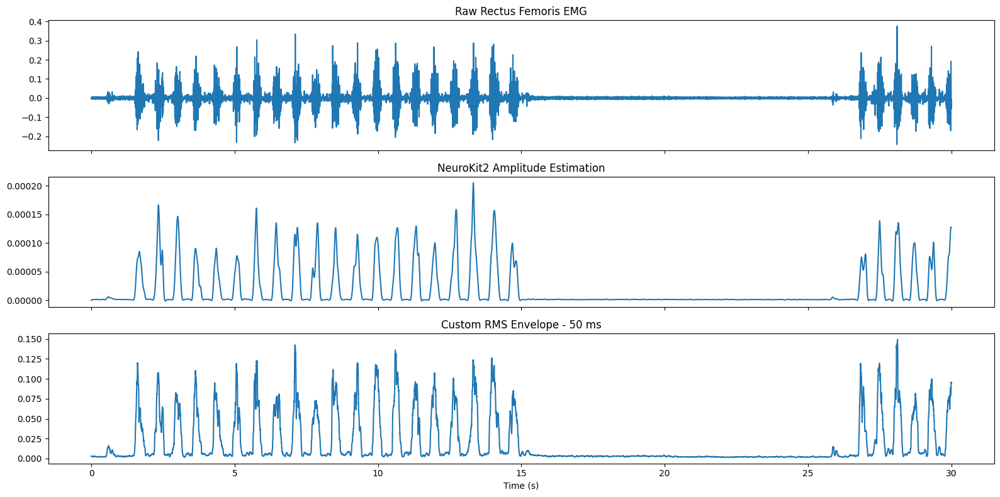

In [21]:
fig, ax = plt.subplots(
    3, 1, figsize=(16, 8), sharex=True
)

ax[0].plot(time_segment, pilot_segment)
ax[0].set_title("Raw Rectus Femoris EMG")

ax[1].plot(
    time_segment,
    signals_pilot["EMG_Amplitude"]
)
ax[1].set_title("NeuroKit2 Amplitude Estimation")

ax[2].plot(
    time_segment,
    rms_results[50][mask]
)
ax[2].set_title("Custom RMS Envelope - 50 ms")

ax[-1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

In [22]:
baseline_start = 17
baseline_end = 23

baseline_mask = (
    (time >= baseline_start) &
    (time < baseline_end)
)

emg_rms = rms_results[50]

baseline = emg_rms[baseline_mask]

baseline_mean = np.mean(baseline)
baseline_std = np.std(baseline)

print("Baseline mean:", baseline_mean)
print("Baseline standard deviation:", baseline_std)

Baseline mean: 0.0026121635673869003
Baseline standard deviation: 0.0005549175137483098


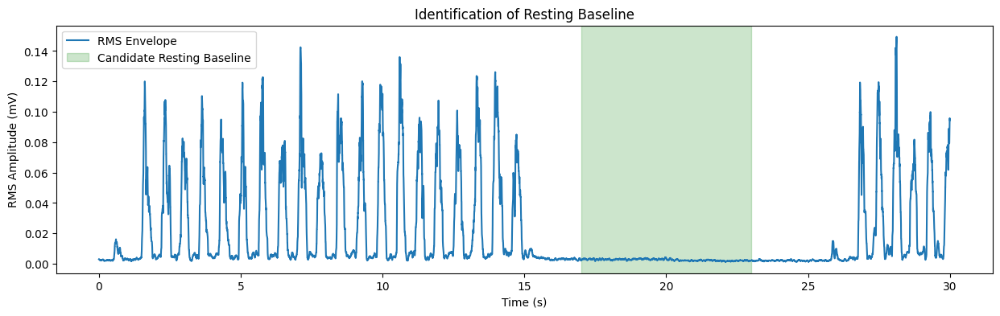

In [23]:
plt.figure(figsize=(15, 4))

plt.plot(
    time[mask],
    emg_rms[mask],
    label="RMS Envelope"
)

plt.axvspan(
    baseline_start,
    baseline_end,
    color="green",
    alpha=0.2,
    label="Candidate Resting Baseline"
)

plt.xlabel("Time (s)")
plt.ylabel("RMS Amplitude (mV)")
plt.title("Identification of Resting Baseline")
plt.legend()
plt.show()

In [24]:
# Select the 50 ms RMS envelope
emg_rms = rms_results[50]

# Candidate resting baseline
baseline_mask = (time >= 17) & (time < 23)

baseline = emg_rms[baseline_mask]

baseline_mean = np.mean(baseline)
baseline_std = np.std(baseline)

# Initial detection parameters
k = 3
min_duration_ms = 50

threshold = baseline_mean + k * baseline_std

print("Baseline mean:", baseline_mean)
print("Baseline SD:", baseline_std)
print("Detection threshold:", threshold)

Baseline mean: 0.0026121635673869003
Baseline SD: 0.0005549175137483098
Detection threshold: 0.00427691610863183


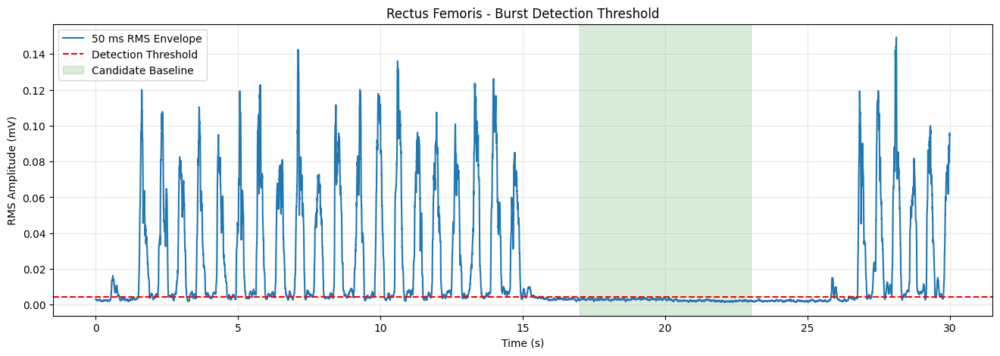

In [25]:
mask = (time >= 0) & (time < 30)

plt.figure(figsize=(16, 5))

plt.plot(
    time[mask],
    emg_rms[mask],
    label="50 ms RMS Envelope"
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Detection Threshold"
)

plt.axvspan(
    17, 23,
    color="green",
    alpha=0.15,
    label="Candidate Baseline"
)

plt.xlabel("Time (s)")
plt.ylabel("RMS Amplitude (mV)")
plt.title("Rectus Femoris - Burst Detection Threshold")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [26]:
def detect_bursts(envelope, threshold, fs,
                  min_duration_ms=50):

    # Identify samples above the threshold
    above_threshold = envelope > threshold

    # Find transitions between active and inactive
    transitions = np.diff(
        above_threshold.astype(int),
        prepend=0,
        append=0
    )

    onsets = np.where(transitions == 1)[0]
    offsets = np.where(transitions == -1)[0]

    # Convert minimum duration to samples
    min_samples = int(
        np.ceil(min_duration_ms * fs / 1000)
    )

    # Remove bursts shorter than minimum duration
    valid = (offsets - onsets) >= min_samples

    onsets = onsets[valid]
    offsets = offsets[valid]

    return onsets, offsets

In [27]:
time_segment = time[mask]
rms_segment = emg_rms[mask]

onsets, offsets = detect_bursts(
    rms_segment,
    threshold,
    fs,
    min_duration_ms=50
)

onset_times = time_segment[0] + onsets / fs
offset_times = time_segment[0] + offsets / fs

print("Number of detected bursts:", len(onsets))

print("\nOnset times:")
print(onset_times)

print("\nOffset times:")
print(offset_times)

Number of detected bursts: 53

Onset times:
[ 0.53139858  1.4978124   1.90839862  2.08110552  2.59131242  2.65788139
  2.76215726  3.29517451  3.45810555  3.51582969  4.08655384  4.79320902
  4.92634696  5.39651938  5.50079525  6.03567457  6.29496768  6.77910562
  6.9457608   7.40522632  7.6095884   8.2222091   8.34557117  8.84460567
  9.05548498  9.67369189  9.77145052 10.26257122 10.35846777 10.45436432
 10.9096402  11.06046779 11.65120918 11.78248504 12.18795057 12.2885023
 12.90717472 13.05893335 13.70041612 14.98943339 15.14026098 25.82527846
 25.94631295 26.75258883 27.13710608 27.25162332 27.74693368 28.36188197
 28.44800266 29.16489923 29.52241648 29.65741648 29.77239924]

Offset times:
[ 0.82932963  1.89350206  2.00057103  2.58200208  2.64484691  2.71700208
  3.1950883   3.42551934  3.51024348  4.00601935  4.62329523  4.88910558
  5.27222628  5.49707111  5.95886422  6.27541595  6.71160562  6.85265735
  7.34564012  7.60493323  8.03693324  8.33346772  8.81434705  9.04896774
  9.

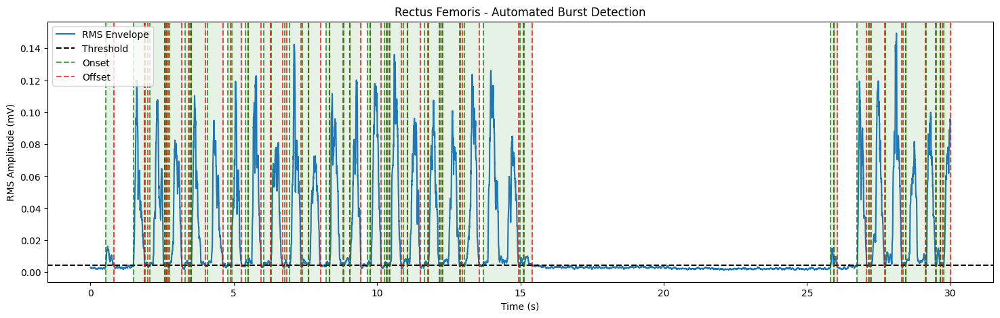

In [28]:
plt.figure(figsize=(18, 5))

plt.plot(
    time_segment,
    rms_segment,
    label="RMS Envelope"
)

plt.axhline(
    threshold,
    color="black",
    linestyle="--",
    label="Threshold"
)

for i, (start, end) in enumerate(
    zip(onset_times, offset_times)
):

    plt.axvline(
        start,
        color="green",
        linestyle="--",
        alpha=0.7,
        label="Onset" if i == 0 else None
    )

    plt.axvline(
        end,
        color="red",
        linestyle="--",
        alpha=0.7,
        label="Offset" if i == 0 else None
    )

    plt.axvspan(
        start, end,
        color="green",
        alpha=0.1
    )

plt.xlabel("Time (s)")
plt.ylabel("RMS Amplitude (mV)")
plt.title("Rectus Femoris - Automated Burst Detection")

plt.legend()
plt.show()

In [77]:
k_values = [1, 2, 3]
duration_values = [20, 50, 100]

results = []

for k in k_values:

    threshold_test = (
        baseline_mean + k * baseline_std
    )

    for duration in duration_values:

        starts, ends = detect_bursts(
            rms_segment,
            threshold_test,
            fs,
            min_duration_ms=duration
        )

        burst_durations = (ends - starts) / fs

        results.append({
            "k": k,
            "Min_Duration_ms": duration,
            "Threshold_mV": threshold_test,
            "Burst_Count": len(starts),
            "Mean_Burst_Duration_s":
                np.mean(burst_durations)
                if len(starts) > 0 else np.nan
        })

results_df = pd.DataFrame(results)

display(results_df)

,k,Min_Duration_ms,Threshold_mV,Burst_Count,Mean_Burst_Duration_s
0,1,20,0.003167,63,0.307685
1,1,50,0.003167,36,0.512961
2,1,100,0.003167,24,0.736429
3,2,20,0.003722,55,0.306006
4,2,50,0.003722,46,0.358732
5,2,100,0.003722,35,0.450009
6,3,20,0.004277,63,0.243562
7,3,50,0.004277,53,0.283351
8,3,100,0.004277,39,0.359702


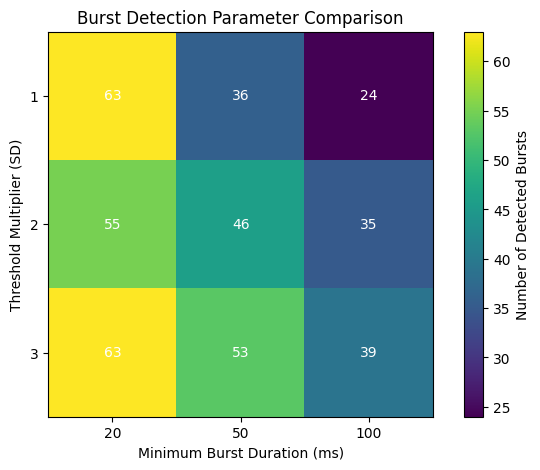

In [78]:
pivot = results_df.pivot(
    index="k",
    columns="Min_Duration_ms",
    values="Burst_Count"
)

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(pivot.values, cmap="viridis")

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)

ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):

        ax.text(
            j, i,
            int(pivot.iloc[i, j]),
            ha="center",
            va="center",
            color="white"
        )

ax.set_xlabel("Minimum Burst Duration (ms)")
ax.set_ylabel("Threshold Multiplier (SD)")
ax.set_title("Burst Detection Parameter Comparison")

plt.colorbar(im, label="Number of Detected Bursts")
plt.show()

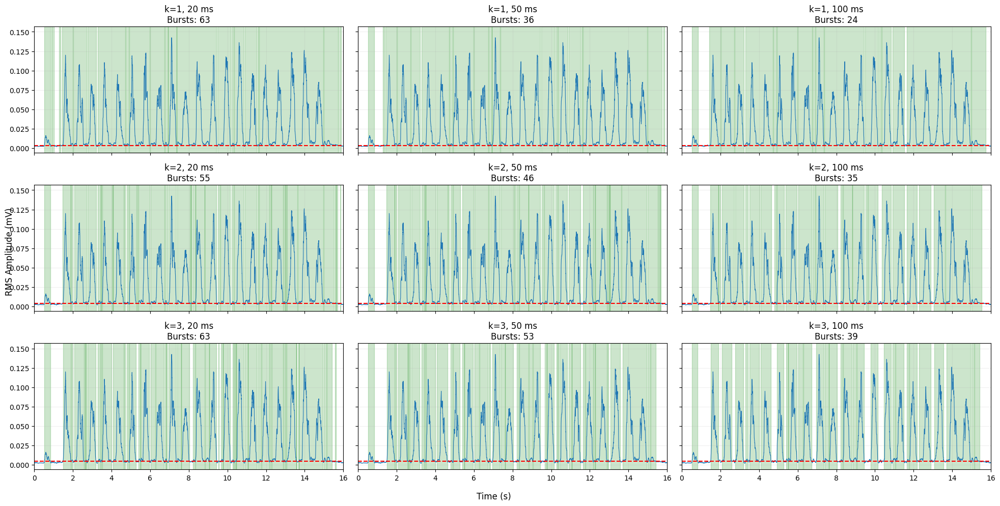

In [31]:
fig, axes = plt.subplots(
    3, 3,
    figsize=(20, 10),
    sharex=True,
    sharey=True
)

for i, k in enumerate(k_values):

    threshold_test = (
        baseline_mean + k * baseline_std
    )

    for j, duration in enumerate(duration_values):

        ax = axes[i, j]

        starts, ends = detect_bursts(
            rms_segment,
            threshold_test,
            fs,
            min_duration_ms=duration
        )

        ax.plot(
            time_segment,
            rms_segment,
            linewidth=0.8
        )

        ax.axhline(
            threshold_test,
            color="red",
            linestyle="--"
        )

        for start, end in zip(starts, ends):

            ax.axvspan(
                time_segment[0] + start/fs,
                time_segment[0] + end/fs,
                color="green",
                alpha=0.2
            )

        ax.set_title(
            f"k={k}, {duration} ms\n"
            f"Bursts: {len(starts)}"
        )

        ax.set_xlim(0, 16)

        ax.grid(alpha=0.2)

fig.supxlabel("Time (s)")
fig.supylabel("RMS Amplitude (mV)")

plt.tight_layout()
plt.show()

In [32]:
k_extended = [3, 5, 8, 10, 15, 20]

extended_results = []

for k in k_extended:

    threshold_test = baseline_mean + k * baseline_std

    starts, ends = detect_bursts(
        rms_segment,
        threshold_test,
        fs,
        min_duration_ms=50
    )

    durations = (ends - starts) / fs

    extended_results.append({
        "k": k,
        "Threshold_mV": threshold_test,
        "Burst_Count": len(starts),
        "Mean_Duration_s": (
            np.mean(durations)
            if len(starts) > 0 else np.nan
        )
    })

extended_df = pd.DataFrame(extended_results)

display(extended_df)

,k,Threshold_mV,Burst_Count,Mean_Duration_s
0,3,0.004277,53,0.283351
1,5,0.005387,46,0.273653
2,8,0.007052,38,0.267954
3,10,0.008161,35,0.273152
4,15,0.010936,29,0.303405
5,20,0.013711,26,0.319076


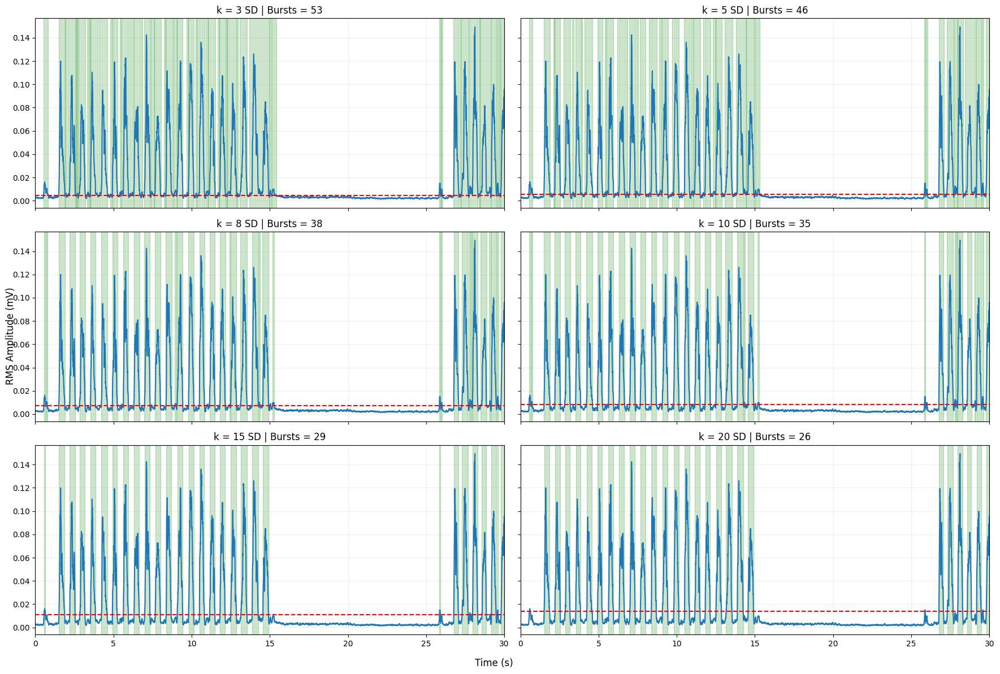

In [79]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(18, 12),
    sharex=True,
    sharey=True
)

for ax, k in zip(axes.flat, k_extended):

    threshold_test = baseline_mean + k * baseline_std

    starts, ends = detect_bursts(
        rms_segment,
        threshold_test,
        fs,
        min_duration_ms=50
    )

    ax.plot(time_segment, rms_segment)

    ax.axhline(
        threshold_test,
        color="red",
        linestyle="--"
    )

    for start, end in zip(starts, ends):

        ax.axvspan(
            time_segment[0] + start/fs,
            time_segment[0] + end/fs,
            color="green",
            alpha=0.2
        )

    ax.set_title(
        f"k = {k} SD | Bursts = {len(starts)}"
    )

    ax.set_xlim(0, 30)
    ax.grid(alpha=0.2)

fig.supxlabel("Time (s)")
fig.supylabel("RMS Amplitude (mV)")

plt.tight_layout()
plt.show()

In [80]:
def detect_bursts_improved(
    envelope,
    threshold,
    fs,
    min_duration_ms=50,
    min_gap_ms=50
):

    above_threshold = envelope > threshold

    transitions = np.diff(
        above_threshold.astype(int),
        prepend=0,
        append=0
    )

    onsets = np.where(transitions == 1)[0]
    offsets = np.where(transitions == -1)[0]

    if len(onsets) == 0:
        return np.array([], dtype=int), np.array([], dtype=int)

    min_samples = int(
        np.ceil(min_duration_ms * fs / 1000)
    )

    gap_samples = int(
        round(min_gap_ms * fs / 1000)
    )

    # Merge bursts separated by short gaps
    merged_onsets = [onsets[0]]
    merged_offsets = [offsets[0]]

    for start, end in zip(onsets[1:], offsets[1:]):

        gap = start - merged_offsets[-1]

        if gap <= gap_samples:

            merged_offsets[-1] = end

        else:

            merged_onsets.append(start)
            merged_offsets.append(end)

    merged_onsets = np.array(merged_onsets)
    merged_offsets = np.array(merged_offsets)

    # Remove short bursts after merging
    valid = (
        merged_offsets - merged_onsets
    ) >= min_samples

    return merged_onsets[valid], merged_offsets[valid]

In [82]:
gap_values = [0, 20, 50, 100]

gap_results = []

# Provisional threshold for testing
k_test = 10

threshold_test = baseline_mean + k_test * baseline_std

for gap in gap_values:

    starts, ends = detect_bursts_improved(
        rms_segment,
        threshold_test,
        fs,
        min_duration_ms=50,
        min_gap_ms=gap
    )

    gap_results.append({
        "k": k_test,
        "Minimum_Gap_ms": gap,
        "Burst_Count": len(starts),
        "Mean_Duration_s": (
            np.mean((ends-starts)/fs)
            if len(starts) > 0 else np.nan
        )
    })

gap_df = pd.DataFrame(gap_results)

display(gap_df)

,k,Minimum_Gap_ms,Burst_Count,Mean_Duration_s
0,10,0,35,0.273152
1,10,20,36,0.267246
2,10,50,32,0.306732
3,10,100,28,0.370951


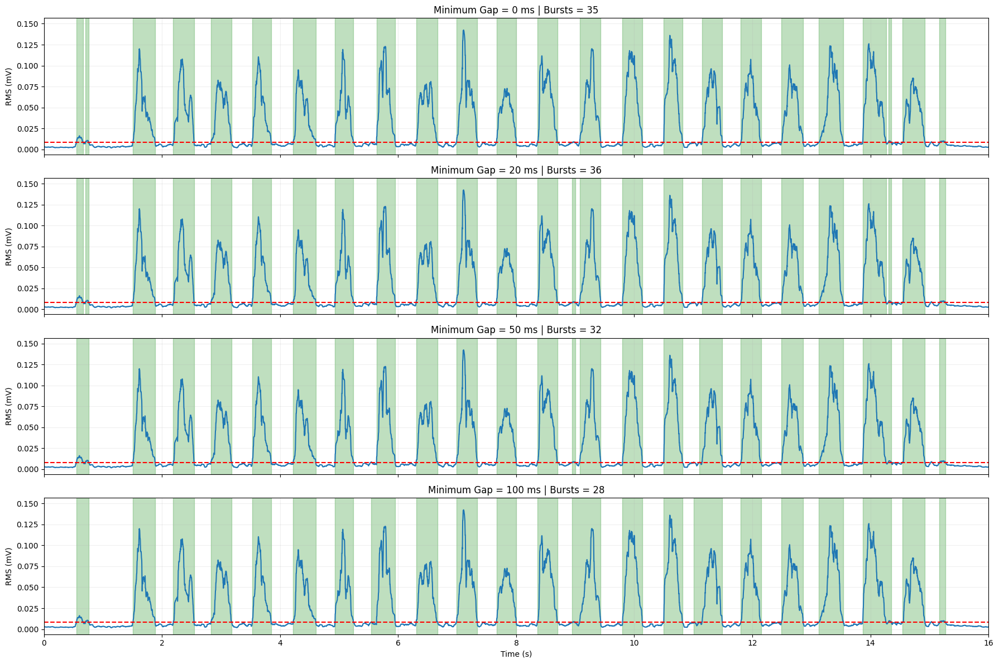

In [83]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(18, 12),
    sharex=True,
    sharey=True
)

for ax, gap in zip(axes, gap_values):

    starts, ends = detect_bursts_improved(
        rms_segment,
        threshold_test,
        fs,
        min_duration_ms=50,
        min_gap_ms=gap
    )

    ax.plot(time_segment, rms_segment)

    ax.axhline(
        threshold_test,
        color="red",
        linestyle="--"
    )

    for start, end in zip(starts, ends):

        ax.axvspan(
            time_segment[0] + start/fs,
            time_segment[0] + end/fs,
            color="green",
            alpha=0.25
        )

    ax.set_title(
        f"Minimum Gap = {gap} ms | Bursts = {len(starts)}"
    )

    ax.set_ylabel("RMS (mV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 16)

plt.tight_layout()
plt.show()

In [84]:
def detect_bursts_hysteresis(
    envelope,
    onset_threshold,
    offset_threshold,
    fs,
    min_duration_ms=50
):

    if onset_threshold <= offset_threshold:
        raise ValueError(
            "Onset threshold must exceed offset threshold."
        )

    onsets = []
    offsets = []

    active = False

    for i, value in enumerate(envelope):

        if not active and value >= onset_threshold:

            onsets.append(i)
            active = True

        elif active and value < offset_threshold:

            offsets.append(i)
            active = False

    # Handle a burst extending beyond the segment
    if active:
        offsets.append(len(envelope))

    onsets = np.array(onsets, dtype=int)
    offsets = np.array(offsets, dtype=int)

    min_samples = int(
        np.ceil(min_duration_ms * fs / 1000)
    )

    valid = (offsets - onsets) >= min_samples

    return onsets[valid], offsets[valid]

In [85]:
k_onset = 10
k_offset = 5

onset_threshold = (
    baseline_mean + k_onset * baseline_std
)

offset_threshold = (
    baseline_mean + k_offset * baseline_std
)

h_onsets, h_offsets = detect_bursts_hysteresis(
    rms_segment,
    onset_threshold,
    offset_threshold,
    fs,
    min_duration_ms=50
)

print("Onset threshold:", onset_threshold)
print("Offset threshold:", offset_threshold)
print("Detected bursts:", len(h_onsets))

Onset threshold: 0.008161338704869998
Offset threshold: 0.005386751136128449
Detected bursts: 34


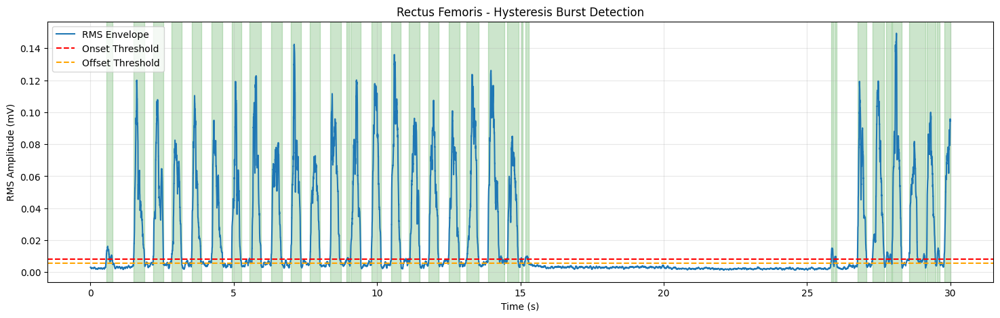

In [86]:
plt.figure(figsize=(18, 5))

plt.plot(
    time_segment,
    rms_segment,
    label="RMS Envelope"
)

plt.axhline(
    onset_threshold,
    color="red",
    linestyle="--",
    label="Onset Threshold"
)

plt.axhline(
    offset_threshold,
    color="orange",
    linestyle="--",
    label="Offset Threshold"
)

for start, end in zip(h_onsets, h_offsets):

    plt.axvspan(
        time_segment[0] + start/fs,
        time_segment[0] + end/fs,
        color="green",
        alpha=0.2
    )

plt.xlabel("Time (s)")
plt.ylabel("RMS Amplitude (mV)")
plt.title("Rectus Femoris - Hysteresis Burst Detection")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [87]:
candidate_methods = {}

# Method A: Single threshold, 15 SD
candidate_methods["A: Single 15 SD"] = detect_bursts(
    rms_segment,
    baseline_mean + 15 * baseline_std,
    fs,
    min_duration_ms=50
)

# Method B: Single threshold, 20 SD
candidate_methods["B: Single 20 SD"] = detect_bursts(
    rms_segment,
    baseline_mean + 20 * baseline_std,
    fs,
    min_duration_ms=50
)

# Method C: Gap merging
candidate_methods["C: Gap Merging"] = detect_bursts_improved(
    rms_segment,
    baseline_mean + 10 * baseline_std,
    fs,
    min_duration_ms=50,
    min_gap_ms=100
)

# Method D: Original hysteresis
candidate_methods["D: Hysteresis 10/5"] = detect_bursts_hysteresis(
    rms_segment,
    baseline_mean + 10 * baseline_std,
    baseline_mean + 5 * baseline_std,
    fs,
    min_duration_ms=50
)

# Method E: Modified hysteresis
candidate_methods["E: Hysteresis 20/10"] = detect_bursts_hysteresis(
    rms_segment,
    baseline_mean + 20 * baseline_std,
    baseline_mean + 10 * baseline_std,
    fs,
    min_duration_ms=50
)

In [88]:
comparison_results = []

for method, (starts, ends) in candidate_methods.items():

    durations = (ends - starts) / fs

    total_active_time = np.sum(durations)

    percent_active = (
        total_active_time / (len(rms_segment) / fs)
    ) * 100

    comparison_results.append({
        "Method": method,
        "Burst_Count": len(starts),
        "Mean_Duration_s": (
            np.mean(durations)
            if len(durations) > 0 else np.nan
        ),
        "SD_Duration_s": (
            np.std(durations)
            if len(durations) > 0 else np.nan
        ),
        "Total_Active_Time_s": total_active_time,
        "Percent_Active": percent_active
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Method,Burst_Count,Mean_Duration_s,SD_Duration_s,Total_Active_Time_s,Percent_Active
0,A: Single 15 SD,29,0.3034,0.0881,8.7987,29.3293
1,B: Single 20 SD,26,0.3191,0.0368,8.2960,27.6535
2,C: Gap Merging,28,0.3710,0.1563,10.3866,34.6223
3,D: Hysteresis 10/5,34,0.3134,0.1287,10.6543,35.5146
4,E: Hysteresis 20/10,28,0.3125,0.0764,8.7513,29.1711


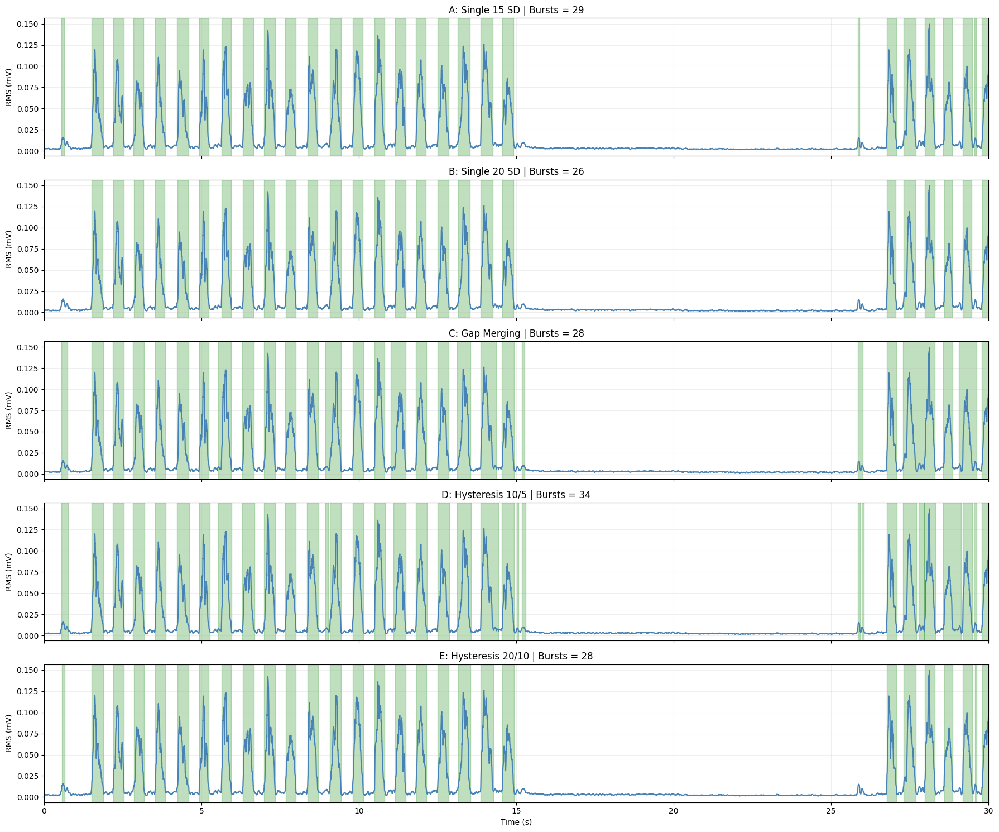

In [89]:
fig, axes = plt.subplots(
    5, 1,
    figsize=(18, 15),
    sharex=True,
    sharey=True
)

for ax, (method, (starts, ends)) in zip(
    axes, candidate_methods.items()
):

    ax.plot(
        time_segment,
        rms_segment,
        color="steelblue",
        label="RMS Envelope"
    )

    for start, end in zip(starts, ends):

        ax.axvspan(
            time_segment[0] + start / fs,
            time_segment[0] + end / fs,
            color="green",
            alpha=0.25
        )

    ax.set_title(
        f"{method} | Bursts = {len(starts)}"
    )

    ax.set_ylabel("RMS (mV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 30)

plt.tight_layout()
plt.show()

In [43]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=time_segment,
        y=rms_segment,
        mode="lines",
        name="RMS Envelope"
    )
)

fig.update_layout(
    title="Rectus Femoris - Manual Burst Annotation",
    xaxis_title="Time (s)",
    yaxis_title="RMS Amplitude (mV)",
    width=1100,
    height=500,
    hovermode="x",
    xaxis=dict(
        rangeslider=dict(visible=True)
    )
)

fig.show()

In [44]:
manual_bursts = [
    # Enter your manually identified onset and offset times
    # (onset_time, offset_time),

]

In [66]:
manual_bursts = [
    # First active period
    (1.49, 1.90),
    (2.18, 2.55),
    (2.82, 3.20),
    (3.52, 3.86),
    (4.22, 4.62),
    (4.92, 5.28),
    (5.63, 5.97),
    (6.30, 6.68),
    (6.94, 7.35),
    (7.64, 8.01),
    (8.34, 8.71),
    (9.06, 9.45),
    (9.79, 10.15),
    (10.46, 10.85),
    (11.14, 11.50),
    (11.78, 12.17),
    (12.48, 12.88),
    (13.06, 13.56),
    (13.86, 14.27),
    (14.53, 14.94),

    # Second active period
    (26.75, 27.09),
    (27.25, 27.72),
    (27.96, 28.32),
    (28.56, 28.86),
    (29.17, 29.49)
]

print("Number of manually annotated bursts:",
      len(manual_bursts))

Number of manually annotated bursts: 25


In [72]:
manual_df = pd.DataFrame(
    manual_bursts,
    columns=["Onset_s", "Offset_s"]
)

manual_df["Duration_s"] = (
    manual_df["Offset_s"] - manual_df["Onset_s"]
)

manual_df.insert(
    0,
    "Burst_ID",
    np.arange(1, len(manual_df) + 1)
)

display(manual_df)

print("Manually identified bursts:", len(manual_df))

,Burst_ID,Onset_s,Offset_s,Duration_s
0,1,1.49,1.90,0.41
1,2,2.18,2.55,0.37
2,3,2.82,3.20,0.38
3,4,3.52,3.86,0.34
4,5,4.22,4.62,0.40
5,6,4.92,5.28,0.36
6,7,5.63,5.97,0.34
7,8,6.30,6.68,0.38
8,9,6.94,7.35,0.41
9,10,7.64,8.01,0.37


Manually identified bursts: 25


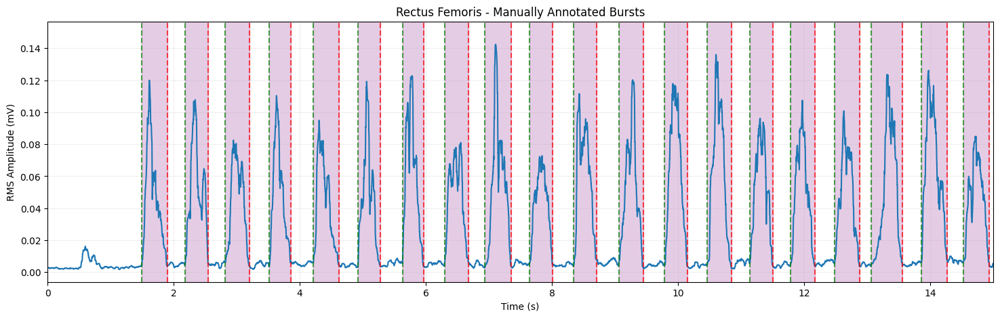

In [73]:
plt.figure(figsize=(18, 5))

plt.plot(
    time_segment,
    rms_segment,
    label="RMS Envelope"
)

for onset, offset in manual_bursts:

    plt.axvspan(
        onset,
        offset,
        color="purple",
        alpha=0.2
    )

    plt.axvline(
        onset,
        color="green",
        linestyle="--",
        alpha=0.7
    )

    plt.axvline(
        offset,
        color="red",
        linestyle="--",
        alpha=0.7
    )

plt.xlim(0, 15)
plt.xlabel("Time (s)")
plt.ylabel("RMS Amplitude (mV)")
plt.title("Rectus Femoris - Manually Annotated Bursts")
plt.grid(alpha=0.2)
plt.show()

In [74]:
manual_df.to_csv(
    "rectus_femoris_manual_annotations.csv",
    index=False
)

from google.colab import files

files.download(
    "rectus_femoris_manual_annotations.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [75]:
import plotly.graph_objects as go

def annotation_plot(start_time, end_time):

    mask = (
        (time_segment >= start_time) &
        (time_segment <= end_time)
    )

    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=time_segment[mask],
            y=rms_segment[mask],
            mode="lines",
            name="RMS Envelope",
            hovertemplate=(
                "Time: %{x:.4f} s<br>"
                "RMS: %{y:.5f} mV"
                "<extra></extra>"
            )
        )
    )

    fig.update_layout(
        title=f"Manual Annotation: {start_time}-{end_time} s",
        xaxis_title="Time (s)",
        yaxis_title="RMS Amplitude (mV)",
        height=450,
        hovermode="closest"
    )

    fig.show()

In [76]:
annotation_plot(0, 3.5)

In [51]:
annotation_plot(3, 6.5)

In [52]:
annotation_plot(6, 9.5)

In [53]:
annotation_plot(9, 12.5)

In [54]:
annotation_plot(12, 15.5)

In [55]:
from scipy.optimize import linear_sum_assignment

def match_bursts(manual, detected, iou_threshold=0.5):

    manual = np.asarray(manual).reshape(-1, 2)
    detected = np.asarray(detected).reshape(-1, 2)

    iou_matrix = np.zeros(
        (len(manual), len(detected))
    )

    for i, (m_start, m_end) in enumerate(manual):

        for j, (d_start, d_end) in enumerate(detected):

            intersection = max(
                0,
                min(m_end, d_end) -
                max(m_start, d_start)
            )

            union = (
                max(m_end, d_end) -
                min(m_start, d_start)
            )

            if union > 0:
                iou_matrix[i, j] = intersection / union

    # Prioritize valid matches, then overlap quality
    valid = iou_matrix >= iou_threshold
    bonus = min(len(manual), len(detected)) + 1

    scores = np.where(
        valid,
        bonus + iou_matrix,
        0
    )

    rows, cols = linear_sum_assignment(-scores)

    matches = [
        (i, j)
        for i, j in zip(rows, cols)
        if valid[i, j]
    ]

    return matches

In [96]:
def evaluate_detection(manual, detected):

    manual = np.asarray(manual).reshape(-1, 2)
    detected = np.asarray(detected).reshape(-1, 2)

    matches = match_bursts(manual, detected)

    TP = len(matches)
    FP = len(detected) - TP
    FN = len(manual) - TP

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    onset_errors = []
    offset_errors = []
    duration_errors = []

    for i, j in matches:

        m_start, m_end = manual[i]
        d_start, d_end = detected[j]

        onset_errors.append(
            abs(d_start - m_start) * 1000
        )

        offset_errors.append(
            abs(d_end - m_end) * 1000
        )

        duration_errors.append(
            abs(
                (d_end - d_start) -
                (m_end - m_start)
            ) * 1000
        )

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Onset_MAE_ms": (
            np.mean(onset_errors)
            if TP else np.nan
        ),
        "Offset_MAE_ms": (
            np.mean(offset_errors)
            if TP else np.nan
        ),
        "Duration_MAE_ms": (
            np.mean(duration_errors)
            if TP else np.nan
        )
    }

In [95]:
validation_results = []

for method, (starts, ends) in candidate_methods.items():

    detected_bursts = np.column_stack([
        time_segment[0] + np.asarray(starts) / fs,
        time_segment[0] + np.asarray(ends) / fs
    ])

    metrics = evaluate_detection(
        manual_bursts,
        detected_bursts
    )

    metrics["Method"] = method

    validation_results.append(metrics)

validation_df = pd.DataFrame(validation_results)

validation_df = validation_df[
    [
        "Method",
        "TP",
        "FP",
        "FN",
        "Precision",
        "Recall",
        "F1",
        "Onset_MAE_ms",
        "Offset_MAE_ms",
        "Duration_MAE_ms"
    ]
]

display(
    validation_df.sort_values(
        "F1",
        ascending=False
    ).round(4)
)

,Method,TP,FP,FN,Precision,Recall,F1,Onset_MAE_ms,Offset_MAE_ms,Duration_MAE_ms
1,B: Single 20 SD,25,1,0,0.9615,1.00,0.9804,29.2133,28.0612,57.2745
4,E: Hysteresis 20/10,25,3,0,0.8929,1.00,0.9434,29.2133,16.0496,44.8545
0,A: Single 15 SD,25,4,0,0.8621,1.00,0.9259,23.2175,22.3074,45.5248
2,C: Gap Merging,23,5,2,0.8214,0.92,0.8679,34.5127,24.0029,53.3673
3,D: Hysteresis 10/5,25,9,0,0.7353,1.00,0.8475,21.4819,27.3028,43.6862


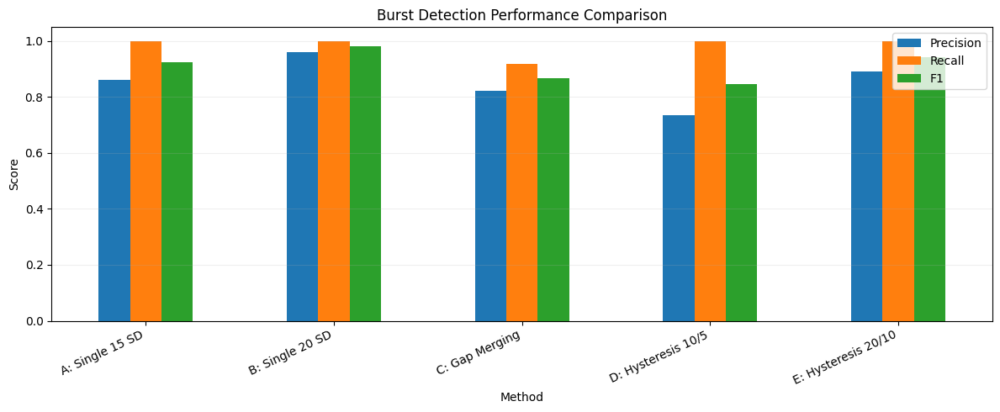

In [93]:
validation_df.set_index("Method")[
    ["Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.ylabel("Score")
plt.title("Burst Detection Performance Comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

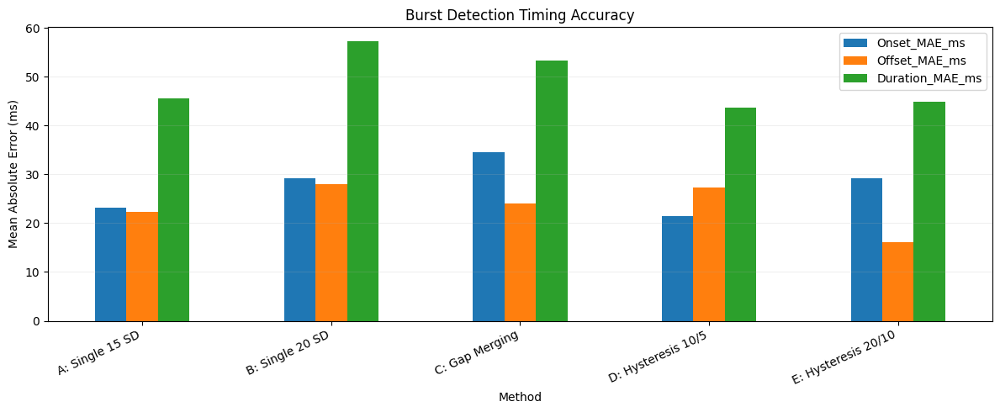

In [94]:
validation_df.set_index("Method")[
    [
        "Onset_MAE_ms",
        "Offset_MAE_ms",
        "Duration_MAE_ms"
    ]
].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.ylabel("Mean Absolute Error (ms)")
plt.title("Burst Detection Timing Accuracy")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [62]:
annotation_plot(25, 28)

In [63]:
annotation_plot(27.5, 30)

In [64]:
annotation_plot(15, 25)

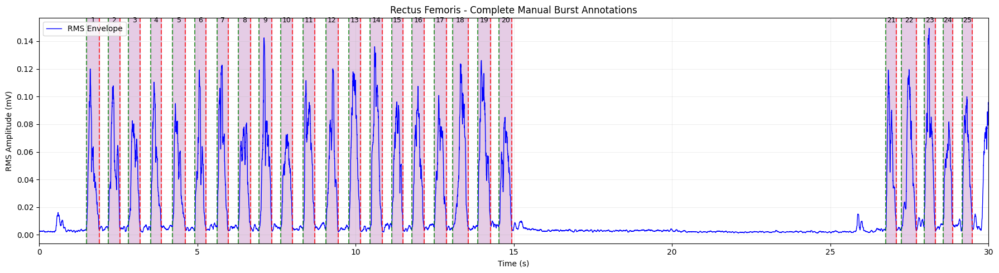

In [67]:
plt.figure(figsize=(18, 5))

plt.plot(
    time_segment,
    rms_segment,
    color="blue",
    linewidth=1,
    label="RMS Envelope"
)

for i, (onset, offset) in enumerate(manual_bursts):

    plt.axvspan(
        onset,
        offset,
        color="purple",
        alpha=0.2
    )

    plt.axvline(
        onset,
        color="green",
        linestyle="--",
        alpha=0.7
    )

    plt.axvline(
        offset,
        color="red",
        linestyle="--",
        alpha=0.7
    )

    plt.text(
        (onset + offset) / 2,
        max(rms_segment) * 1.03,
        str(i + 1),
        ha="center",
        fontsize=9
    )

plt.xlabel("Time (s)")
plt.ylabel("RMS Amplitude (mV)")
plt.title("Rectus Femoris - Complete Manual Burst Annotations")
plt.xlim(0, 30)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [68]:
manual_df = pd.DataFrame(
    manual_bursts,
    columns=["Onset_s", "Offset_s"]
)

manual_df.insert(
    0, "Burst_ID", range(1, len(manual_df) + 1)
)

manual_df["Duration_s"] = (
    manual_df["Offset_s"] - manual_df["Onset_s"]
)

manual_df.to_csv(
    "rectus_femoris_manual_annotations.csv",
    index=False
)

display(manual_df)

,Burst_ID,Onset_s,Offset_s,Duration_s
0,1,1.49,1.90,0.41
1,2,2.18,2.55,0.37
2,3,2.82,3.20,0.38
3,4,3.52,3.86,0.34
4,5,4.22,4.62,0.40
5,6,4.92,5.28,0.36
6,7,5.63,5.97,0.34
7,8,6.30,6.68,0.38
8,9,6.94,7.35,0.41
9,10,7.64,8.01,0.37


In [69]:
from google.colab import files

files.download("rectus_femoris_manual_annotations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

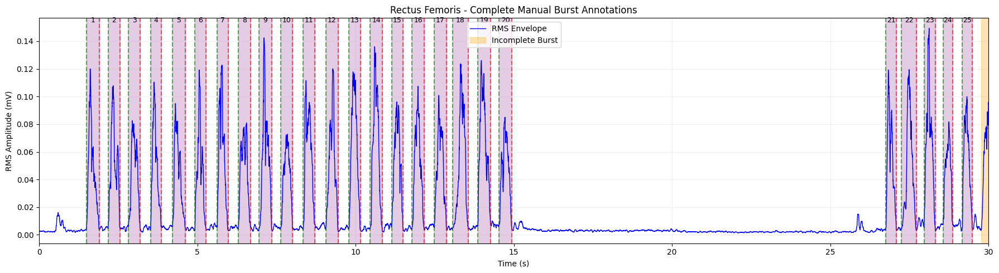

In [70]:
plt.figure(figsize=(18, 5))

plt.plot(
    time_segment,
    rms_segment,
    color="blue",
    linewidth=1,
    label="RMS Envelope"
)

for i, (onset, offset) in enumerate(manual_bursts):

    plt.axvspan(
        onset, offset,
        color="purple",
        alpha=0.2
    )

    plt.axvline(
        onset, color="green",
        linestyle="--", alpha=0.6
    )

    plt.axvline(
        offset, color="red",
        linestyle="--", alpha=0.6
    )

    plt.text(
        (onset + offset) / 2,
        max(rms_segment) * 1.03,
        str(i + 1),
        ha="center",
        fontsize=9
    )

# Mark incomplete contraction
plt.axvspan(
    29.77, 30,
    color="orange",
    alpha=0.3,
    label="Incomplete Burst"
)

plt.xlabel("Time (s)")
plt.ylabel("RMS Amplitude (mV)")
plt.title("Rectus Femoris - Complete Manual Burst Annotations")
plt.xlim(0, 30)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [97]:
evaluation_end = 29.70

def filter_evaluation_bursts(bursts):
    return [
        (onset, offset)
        for onset, offset in bursts
        if onset >= 0 and offset <= evaluation_end
    ]

In [98]:
def inspect_evaluation_window(bursts, name):

    excluded = [
        (onset, offset)
        for onset, offset in bursts
        if onset < 0 or offset > 29.70
    ]

    print(name)
    print("Original count:", len(bursts))
    print("Excluded bursts:", excluded)
    print("Remaining count:",
          len(bursts) - len(excluded))

In [101]:
import neurokit2 as nk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NeuroKit2 version:", nk.__version__)

NeuroKit2 version: 0.3.0


In [102]:
# Extract the same 30-second raw EMG segment
mask = (time >= 0) & (time < 30)

raw_segment = emg_raw[mask]
time_segment = time[mask]

# Verify the segment
print("Sampling rate:", fs, "Hz")
print("Raw segment samples:", len(raw_segment))
print("RMS segment samples:", len(rms_segment))
print("Duration:", len(raw_segment) / fs, "seconds")

# Process using NeuroKit2
nk_signals, nk_info = nk.emg_process(
    raw_segment,
    sampling_rate=fs
)

display(nk_signals.head())

print(nk_signals.columns.tolist())

Sampling rate: 2148.1481 Hz
Raw segment samples: 64444
RMS segment samples: 64444
Duration: 29.999793775857448 seconds


,EMG_Raw,EMG_Clean,EMG_Amplitude,EMG_Activity,EMG_Onsets,EMG_Offsets
0,0.001511,-0.000069,-6.372335e-08,0.0,0,0
1,-0.001007,-0.001765,-3.451837e-08,0.0,0,0
2,-0.002182,-0.002149,-5.416540e-09,0.0,0,0
3,-0.003525,-0.002763,2.356667e-08,0.0,0,0
4,-0.005036,-0.003636,5.241614e-08,0.0,0,0


['EMG_Raw', 'EMG_Clean', 'EMG_Amplitude', 'EMG_Activity', 'EMG_Onsets', 'EMG_Offsets']


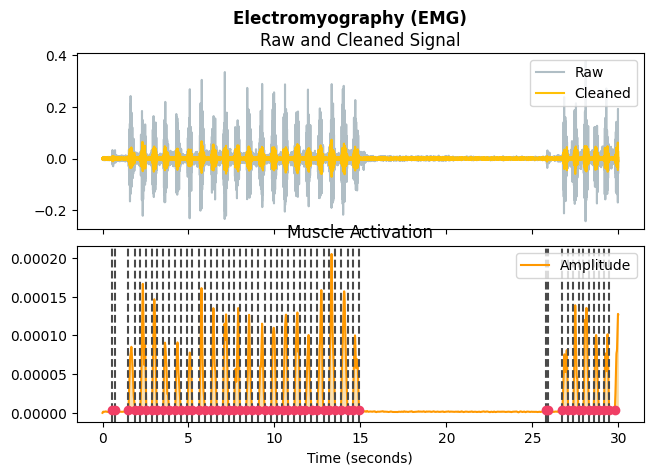

In [103]:
nk.emg_plot(nk_signals, nk_info)

plt.show()

In [104]:
nk_onsets = np.flatnonzero(
    nk_signals["EMG_Onsets"].to_numpy() == 1
)

nk_offsets = np.flatnonzero(
    nk_signals["EMG_Offsets"].to_numpy() == 1
)

print("Number of onsets:", len(nk_onsets))
print("Number of offsets:", len(nk_offsets))

print("Onset times (s):", nk_onsets / fs)
print("Offset times (s):", nk_offsets / fs)

Number of onsets: 28
Number of offsets: 27
Onset times (s): [ 0.54465518  1.49896555  2.1856035   2.85408627  3.52117249  4.22410354
  4.9219139   5.62112082  6.300776    6.99113809  7.64798293  8.34253467
  9.06967262  9.80472436 10.47041403 11.15053473 11.7971382  12.48656925
 13.14853478 13.86543135 14.55579343 25.82363851 26.74675922 27.37660406
 27.97153511 28.56506961 29.16093169 29.7954317 ]
Offset times (s): [ 0.72294829  1.89651728  2.55010351  3.17156904  3.87031043  4.55601734
  5.23427598  5.96141393  6.65922429  7.33236223  8.00456914  8.71075882
  9.45046573 10.14362092 10.8176899  11.49827612 12.15744855 12.8603796
 13.53584513 14.2555348  14.9272762  25.9069661  27.08705233 27.69036269
 28.30903512 28.87463858 29.47282825]


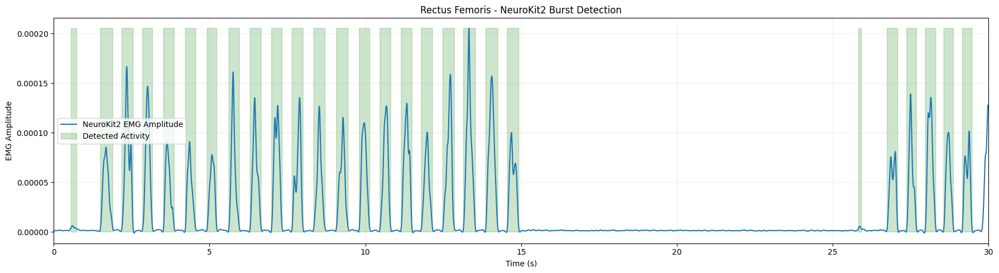

In [105]:
nk_time = np.arange(len(nk_signals)) / fs

plt.figure(figsize=(18, 5))

plt.plot(
    nk_time,
    nk_signals["EMG_Amplitude"],
    label="NeuroKit2 EMG Amplitude"
)

plt.fill_between(
    nk_time,
    0,
    nk_signals["EMG_Amplitude"].max(),
    where=nk_signals["EMG_Activity"].to_numpy() > 0,
    color="green",
    alpha=0.2,
    label="Detected Activity"
)

plt.xlabel("Time (s)")
plt.ylabel("EMG Amplitude")
plt.title("Rectus Femoris - NeuroKit2 Burst Detection")
plt.xlim(0, 30)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [106]:
activity = nk_signals["EMG_Activity"].to_numpy() > 0

# Identify transitions between rest and activity
transitions = np.diff(
    np.concatenate(([0], activity.astype(int), [0]))
)

nk_start_indices = np.where(transitions == 1)[0]
nk_end_indices = np.where(transitions == -1)[0]

# Convert sample indices to seconds
nk_bursts = [
    (start / fs, end / fs)
    for start, end in zip(nk_start_indices, nk_end_indices)
]

print("Total NeuroKit2 bursts:", len(nk_bursts))

nk_burst_df = pd.DataFrame(
    nk_bursts,
    columns=["Onset_s", "Offset_s"]
)

nk_burst_df["Duration_s"] = (
    nk_burst_df["Offset_s"] - nk_burst_df["Onset_s"]
)

display(nk_burst_df)

Total NeuroKit2 bursts: 27


,Onset_s,Offset_s,Duration_s
0,0.544655,0.722948,0.178293
1,1.498966,1.896517,0.397552
2,2.185603,2.550104,0.364500
3,2.854086,3.171569,0.317483
4,3.521172,3.870310,0.349138
5,4.224104,4.556017,0.331914
6,4.921914,5.234276,0.312362
7,5.621121,5.961414,0.340293
8,6.300776,6.659224,0.358448
9,6.991138,7.332362,0.341224


In [107]:
nk_bursts_eval = [
    (onset, offset)
    for onset, offset in nk_bursts
    if onset >= 0 and offset <= 29.70
]

print("Original burst count:", len(nk_bursts))
print("Evaluation burst count:", len(nk_bursts_eval))
print("Excluded bursts:",
      len(nk_bursts) - len(nk_bursts_eval))

Original burst count: 27
Evaluation burst count: 27
Excluded bursts: 0


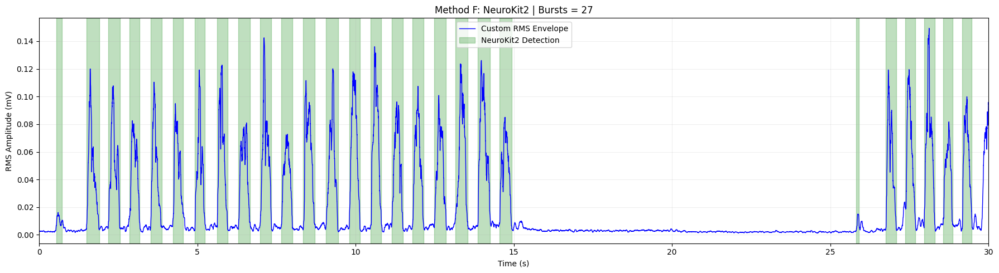

In [108]:
plt.figure(figsize=(18, 5))

plt.plot(
    time_segment,
    rms_segment,
    color="blue",
    linewidth=1,
    label="Custom RMS Envelope"
)

for i, (onset, offset) in enumerate(nk_bursts_eval):
    plt.axvspan(
        onset,
        offset,
        color="green",
        alpha=0.25,
        label="NeuroKit2 Detection" if i == 0 else None
    )

plt.xlabel("Time (s)")
plt.ylabel("RMS Amplitude (mV)")
plt.title(
    f"Method F: NeuroKit2 | Bursts = {len(nk_bursts_eval)}"
)

plt.xlim(0, 30)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [109]:
for name in list(globals()):
    if any(keyword in name.lower() for keyword in [
        "manual",
        "eval",
        "match",
        "method",
        "result",
        "comparison"
    ]):
        if not name.startswith("_"):
            print(name, ":", type(globals()[name]).__name__)

rms_results : dict
results : list
results_df : DataFrame
extended_results : list
gap_results : list
candidate_methods : dict
comparison_results : list
method : str
comparison_df : DataFrame
manual_bursts : list
manual_df : DataFrame
match_bursts : function
evaluate_detection : function
validation_results : list
evaluation_end : float
filter_evaluation_bursts : function
inspect_evaluation_window : function
nk_bursts_eval : list


In [110]:
# Preliminary estimates based on visual inspection
TP_nk = 25
FP_nk = 2
FN_nk = 0

precision_nk = TP_nk / (TP_nk + FP_nk)
recall_nk = TP_nk / (TP_nk + FN_nk)

f1_nk = (
    2 * precision_nk * recall_nk
    / (precision_nk + recall_nk)
)

print("Preliminary NeuroKit2 Performance")
print(f"Precision: {precision_nk:.4f}")
print(f"Recall: {recall_nk:.4f}")
print(f"F1 Score: {f1_nk:.4f}")

Preliminary NeuroKit2 Performance
Precision: 0.9259
Recall: 1.0000
F1 Score: 0.9615


In [111]:
import inspect

print(inspect.signature(evaluate_detection))
print(inspect.getsource(evaluate_detection))

(manual, detected)
def evaluate_detection(manual, detected):

    manual = np.asarray(manual).reshape(-1, 2)
    detected = np.asarray(detected).reshape(-1, 2)

    matches = match_bursts(manual, detected)

    TP = len(matches)
    FP = len(detected) - TP
    FN = len(manual) - TP

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    onset_errors = []
    offset_errors = []
    duration_errors = []

    for i, j in matches:

        m_start, m_end = manual[i]
        d_start, d_end = detected[j]

        onset_errors.append(
            abs(d_start - m_start) * 1000
        )

        offset_errors.append(
            abs(d_end - m_end) * 1000
        )

        duration_errors.append(
            abs(
                (d_end - d_start) -
                (m_end - m_start)
            ) * 1000
        )

    return {
        "TP": TP

In [112]:
print("Manual bursts:", len(manual_bursts))
print("NeuroKit2 bursts:", len(nk_bursts_eval))

print("\nManual burst example:")
print(manual_bursts[:3])

print("\nNeuroKit2 burst example:")
print(nk_bursts_eval[:3])

print("\nEvaluation end:", evaluation_end)

Manual bursts: 25
NeuroKit2 bursts: 27

Manual burst example:
[(1.49, 1.9), (2.18, 2.55), (2.82, 3.2)]

NeuroKit2 burst example:
[(np.float64(0.5446551846215818), np.float64(0.7229482920660825)), (np.float64(1.498965550838883), np.float64(1.8965172838874564)), (np.float64(2.1856034972635268), np.float64(2.5501035054333547))]

Evaluation end: 29.7


In [113]:
nk_validation = evaluate_detection(
    manual_bursts,
    nk_bursts_eval
)

print(nk_validation)

{'TP': 25, 'FP': 2, 'FN': 0, 'Precision': 0.9259259259259259, 'Recall': 1.0, 'F1': 0.9615384615384615, 'Onset_MAE_ms': np.float64(18.859469233057535), 'Offset_MAE_ms': np.float64(16.199129138255834), 'Duration_MAE_ms': np.float64(32.80482214424574)}


In [114]:
import pandas as pd

nk_validation["Method"] = "F: NeuroKit2"

# Combine previous results with NeuroKit2
all_validation_results = [
    result for result in validation_results
    if result.get("Method") != "F: NeuroKit2"
] + [nk_validation]

final_validation_df = pd.DataFrame(
    all_validation_results
)

final_validation_df = final_validation_df[
    [
        "Method",
        "TP",
        "FP",
        "FN",
        "Precision",
        "Recall",
        "F1",
        "Onset_MAE_ms",
        "Offset_MAE_ms",
        "Duration_MAE_ms"
    ]
]

final_validation_df = final_validation_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

display(final_validation_df.round(4))

,Method,TP,FP,FN,Precision,Recall,F1,Onset_MAE_ms,Offset_MAE_ms,Duration_MAE_ms
0,B: Single 20 SD,25,1,0,0.9615,1.00,0.9804,29.2133,28.0612,57.2745
1,F: NeuroKit2,25,2,0,0.9259,1.00,0.9615,18.8595,16.1991,32.8048
2,E: Hysteresis 20/10,25,3,0,0.8929,1.00,0.9434,29.2133,16.0496,44.8545
3,A: Single 15 SD,25,4,0,0.8621,1.00,0.9259,23.2175,22.3074,45.5248
4,C: Gap Merging,23,5,2,0.8214,0.92,0.8679,34.5127,24.0029,53.3673
5,D: Hysteresis 10/5,25,9,0,0.7353,1.00,0.8475,21.4819,27.3028,43.6862


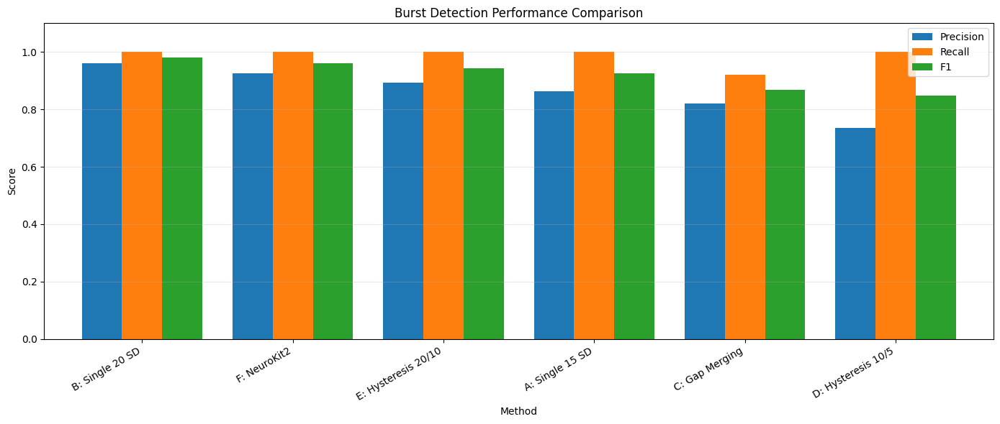

In [115]:
import matplotlib.pyplot as plt

final_validation_df.set_index("Method")[
    ["Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Burst Detection Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Method")
plt.ylim(0, 1.1)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

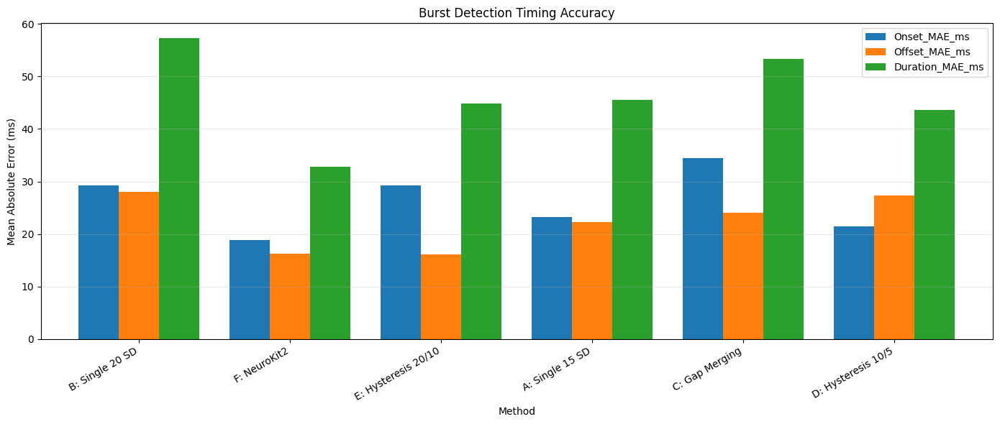

In [116]:
final_validation_df.set_index("Method")[
    [
        "Onset_MAE_ms",
        "Offset_MAE_ms",
        "Duration_MAE_ms"
    ]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Burst Detection Timing Accuracy")
plt.ylabel("Mean Absolute Error (ms)")
plt.xlabel("Method")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Candidate Algorithm Selection

In [117]:
selected_method_names = [
    "F: NeuroKit2",
    "B: Single 20 SD",
    "E: Hysteresis 20/10"
]

shortlisted_df = final_validation_df[
    final_validation_df["Method"].isin(
        selected_method_names
    )
].copy()

shortlisted_df = shortlisted_df.set_index("Method").loc[
    selected_method_names
].reset_index()

display(shortlisted_df.round(4))

,Method,TP,FP,FN,Precision,Recall,F1,Onset_MAE_ms,Offset_MAE_ms,Duration_MAE_ms
0,F: NeuroKit2,25,2,0,0.9259,1.0,0.9615,18.8595,16.1991,32.8048
1,B: Single 20 SD,25,1,0,0.9615,1.0,0.9804,29.2133,28.0612,57.2745
2,E: Hysteresis 20/10,25,3,0,0.8929,1.0,0.9434,29.2133,16.0496,44.8545


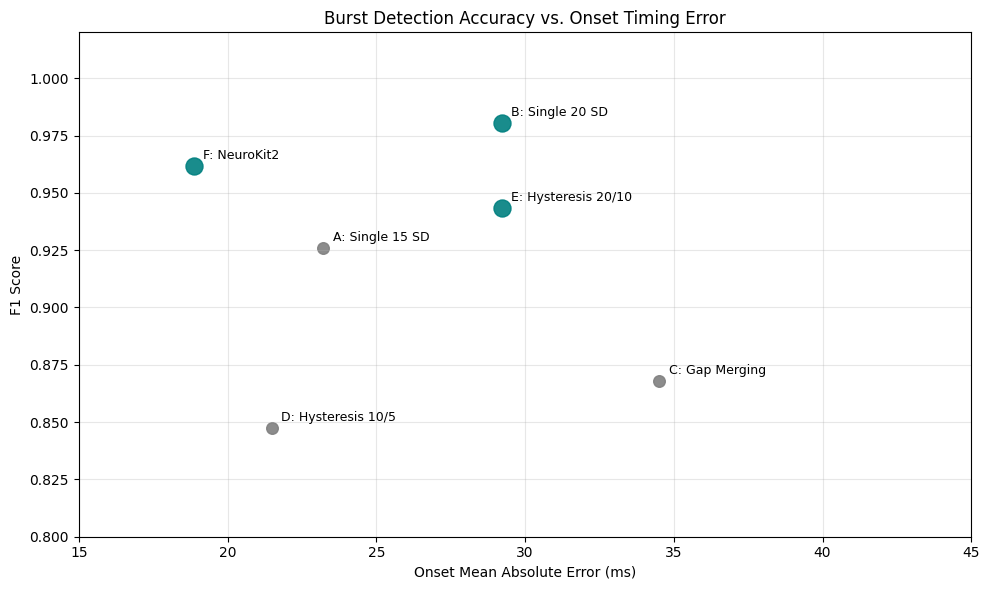

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for _, row in final_validation_df.iterrows():

    selected = row["Method"] in selected_method_names

    plt.scatter(
        row["Onset_MAE_ms"],
        row["F1"],
        s=150 if selected else 70,
        color="teal" if selected else "gray",
        alpha=0.9
    )

    plt.annotate(
        row["Method"],
        (row["Onset_MAE_ms"], row["F1"]),
        xytext=(7, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Onset Mean Absolute Error (ms)")
plt.ylabel("F1 Score")
plt.title("Burst Detection Accuracy vs. Onset Timing Error")
plt.xlim(15, 45)
plt.ylim(0.80, 1.02)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [119]:
final_validation_df.to_csv(
    "rectus_femoris_all_methods_validation.csv",
    index=False
)

shortlisted_df.to_csv(
    "rectus_femoris_shortlisted_methods.csv",
    index=False
)

manual_df.to_csv(
    "rectus_femoris_manual_annotations.csv",
    index=False
)

print("Validation results successfully saved.")

Validation results successfully saved.


In [121]:
from google.colab import files

files.download("rectus_femoris_all_methods_validation.csv")
files.download("rectus_femoris_shortlisted_methods.csv")
files.download("rectus_femoris_manual_annotations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [122]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

feature_signal = np.asarray(emg_filtered).squeeze()
feature_envelope = np.asarray(rms_results[50]).squeeze()
feature_time = np.asarray(time).squeeze()

print("Filtered EMG shape:", feature_signal.shape)
print("RMS envelope shape:", feature_envelope.shape)
print("Time vector shape:", feature_time.shape)
print("Sampling frequency:", fs)
print("Number of detected bursts:", len(nk_bursts_eval))

assert feature_signal.ndim == 1
assert feature_envelope.ndim == 1
assert feature_time.ndim == 1

assert len(feature_signal) == len(feature_envelope) == len(feature_time)

Filtered EMG shape: (2228044,)
RMS envelope shape: (2228044,)
Time vector shape: (2228044,)
Sampling frequency: 2148.1481
Number of detected bursts: 27


In [123]:
from scipy.integrate import trapezoid

def extract_emg_features(signal, envelope, time, bursts):

    signal = np.asarray(signal)
    envelope = np.asarray(envelope)
    time = np.asarray(time)

    features = []
    previous_offset = None
    previous_onset = None

    for i, (onset, offset) in enumerate(sorted(bursts)):

        if onset < time[0] or offset > time[-1] or offset <= onset:
            continue

        # Convert burst times to sample indices
        start_idx = np.searchsorted(time, onset)
        end_idx = np.searchsorted(time, offset, side="right")

        # Extract individual burst
        burst_signal = signal[start_idx:end_idx]
        burst_envelope = envelope[start_idx:end_idx]
        burst_time = time[start_idx:end_idx]

        if len(burst_signal) < 2:
            continue

        # Timing features
        duration_ms = (offset - onset) * 1000

        # Amplitude features
        peak_rms = np.max(burst_envelope)
        mean_rms = np.mean(burst_envelope)

        burst_rms = np.sqrt(
            np.mean(burst_signal ** 2)
        )

        # Integrated rectified EMG
        iemg = trapezoid(
            np.abs(burst_signal),
            x=burst_time
        )

        # Area under RMS envelope
        envelope_area = trapezoid(
            burst_envelope,
            x=burst_time
        )

        # Time to peak
        peak_idx = np.argmax(burst_envelope)

        time_to_peak_ms = (
            burst_time[peak_idx] - onset
        ) * 1000

        # Time between contractions
        if previous_offset is None:
            ibi_ms = np.nan
            onset_interval_ms = np.nan
        else:
            ibi_ms = (onset - previous_offset) * 1000

            onset_interval_ms = (
                onset - previous_onset
            ) * 1000

        features.append({
            "Burst_ID": i + 1,
            "Onset_s": onset,
            "Offset_s": offset,
            "Duration_ms": duration_ms,
            "Peak_RMS_mV": peak_rms,
            "Mean_RMS_mV": mean_rms,
            "Burst_RMS_mV": burst_rms,
            "iEMG_mV_s": iemg,
            "Envelope_Area_mV_s": envelope_area,
            "Time_to_Peak_ms": time_to_peak_ms,
            "Inter_Burst_Interval_ms": ibi_ms,
            "Onset_Interval_ms": onset_interval_ms
        })

        previous_offset = offset
        previous_onset = onset

    return pd.DataFrame(features)

In [124]:
emg_features_df = extract_emg_features(
    signal=feature_signal,
    envelope=feature_envelope,
    time=feature_time,
    bursts=nk_bursts_eval
)

print("Total bursts processed:", len(emg_features_df))

display(emg_features_df.round(4))

Total bursts processed: 27


,Burst_ID,Onset_s,Offset_s,Duration_ms,Peak_RMS_mV,Mean_RMS_mV,Burst_RMS_mV,iEMG_mV_s,Envelope_Area_mV_s,Time_to_Peak_ms,Inter_Burst_Interval_ms,Onset_Interval_ms
0,1,0.5447,0.7229,178.2931,0.0162,0.0110,0.0113,0.0016,0.0020,57.0365,NaN,NaN
1,2,1.4990,1.8965,397.5517,0.1200,0.0482,0.0572,0.0154,0.0192,117.5537,776.0173,954.3104
2,3,2.1856,2.5501,364.5000,0.1078,0.0537,0.0606,0.0158,0.0196,156.6572,289.0862,686.6379
3,4,2.8541,3.1716,317.4828,0.0825,0.0527,0.0571,0.0137,0.0167,94.7434,303.9828,668.4828
4,5,3.5212,3.8703,349.1379,0.1104,0.0488,0.0580,0.0138,0.0170,111.5020,349.6035,667.0862
5,6,4.2241,4.5560,331.9138,0.0950,0.0512,0.0571,0.0140,0.0170,84.0365,353.7931,702.9311
6,7,4.9219,5.2343,312.3621,0.1192,0.0529,0.0606,0.0129,0.0165,140.3640,365.8966,697.8104
7,8,5.6211,5.9614,340.2931,0.1227,0.0610,0.0714,0.0163,0.0208,160.8468,386.8448,699.2069
8,9,6.3008,6.6592,358.4483,0.0810,0.0509,0.0555,0.0150,0.0182,252.5537,339.3621,679.6552
9,10,6.9911,7.3324,341.2241,0.1425,0.0670,0.0750,0.0179,0.0229,117.5536,331.9138,690.3621


In [125]:
feature_columns = [
    "Duration_ms",
    "Peak_RMS_mV",
    "Mean_RMS_mV",
    "Burst_RMS_mV",
    "iEMG_mV_s",
    "Envelope_Area_mV_s",
    "Time_to_Peak_ms",
    "Inter_Burst_Interval_ms",
    "Onset_Interval_ms"
]

feature_summary_df = (
    emg_features_df[feature_columns]
    .describe()
    .T
)

display(feature_summary_df.round(4))

,count,mean,std,min,25%,50%,75%,max
Duration_ms,27.0,333.7069,64.8047,83.3276,324.6983,347.2759,366.3621,397.5517
Peak_RMS_mV,27.0,0.1029,0.0316,0.0150,0.0899,0.1104,0.1201,0.1494
Mean_RMS_mV,27.0,0.0536,0.0143,0.0110,0.0510,0.0538,0.0608,0.0708
Burst_RMS_mV,27.0,0.0605,0.0165,0.0113,0.0571,0.0617,0.0710,0.0801
iEMG_mV_s,27.0,0.0150,0.0046,0.0007,0.0139,0.0155,0.0173,0.0219
Envelope_Area_mV_s,27.0,0.0186,0.0057,0.0009,0.0170,0.0195,0.0214,0.0273
Time_to_Peak_ms,27.0,136.6052,46.8935,46.3291,110.1050,140.3640,163.4071,252.5537
Inter_Burst_Interval_ms,26.0,766.0803,2070.6245,256.0345,299.2112,330.7500,354.1422,10896.3623
Onset_Interval_ms,26.0,1100.6260,2075.3015,593.5345,662.8966,688.0345,702.0000,11267.8451


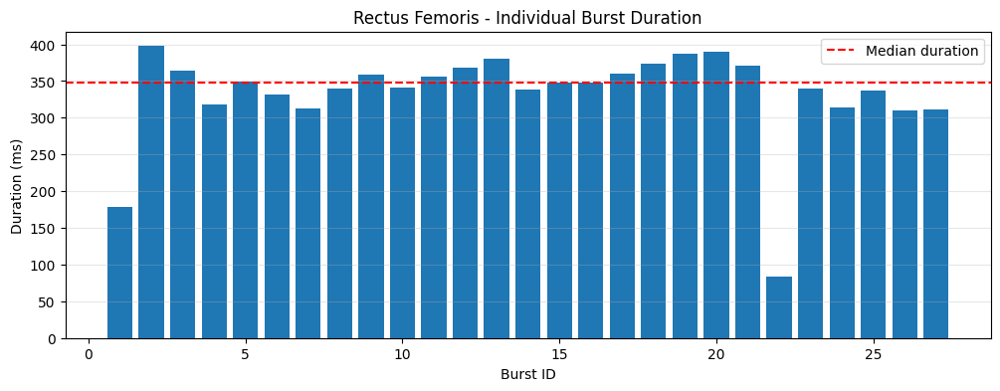

In [126]:
plt.figure(figsize=(12, 4))

plt.bar(
    emg_features_df["Burst_ID"],
    emg_features_df["Duration_ms"]
)

plt.axhline(
    emg_features_df["Duration_ms"].median(),
    color="red",
    linestyle="--",
    label="Median duration"
)

plt.xlabel("Burst ID")
plt.ylabel("Duration (ms)")
plt.title("Rectus Femoris - Individual Burst Duration")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

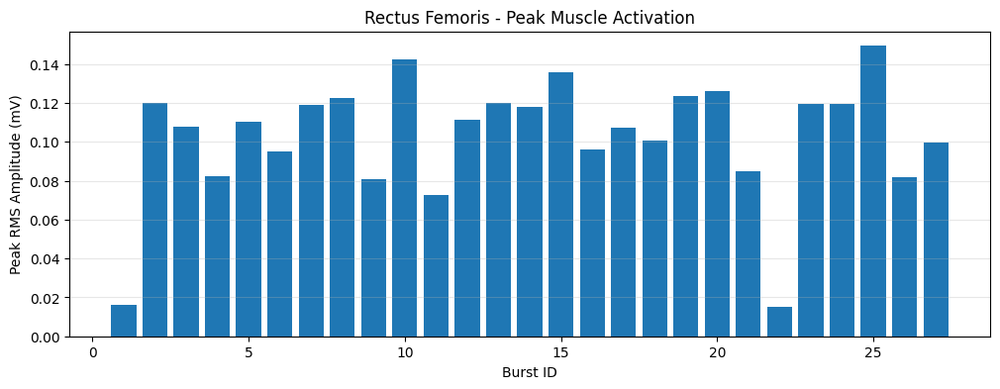

In [127]:
plt.figure(figsize=(12, 4))

plt.bar(
    emg_features_df["Burst_ID"],
    emg_features_df["Peak_RMS_mV"]
)

plt.xlabel("Burst ID")
plt.ylabel("Peak RMS Amplitude (mV)")
plt.title("Rectus Femoris - Peak Muscle Activation")
plt.grid(axis="y", alpha=0.3)
plt.show()

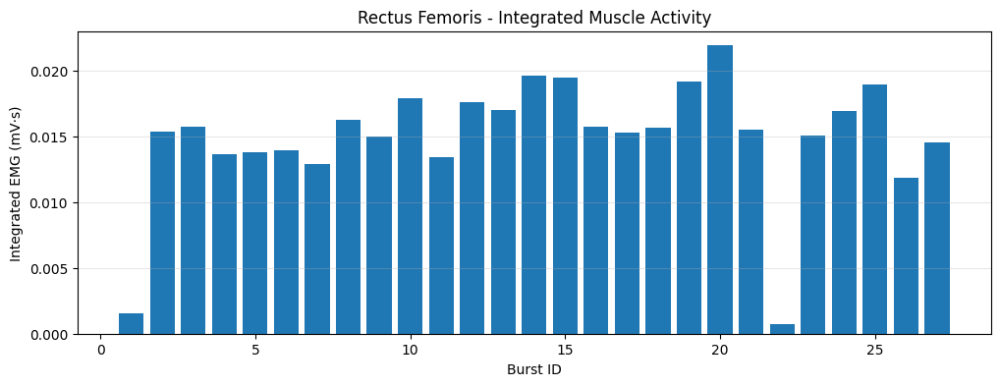

In [128]:
plt.figure(figsize=(12, 4))

plt.bar(
    emg_features_df["Burst_ID"],
    emg_features_df["iEMG_mV_s"]
)

plt.xlabel("Burst ID")
plt.ylabel("Integrated EMG (mV·s)")
plt.title("Rectus Femoris - Integrated Muscle Activity")
plt.grid(axis="y", alpha=0.3)
plt.show()

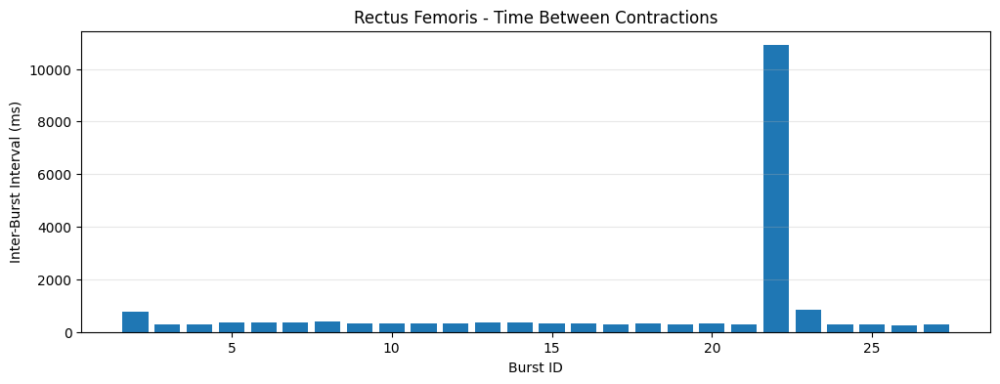

In [129]:
plt.figure(figsize=(12, 4))

plt.bar(
    emg_features_df["Burst_ID"],
    emg_features_df["Inter_Burst_Interval_ms"]
)

plt.xlabel("Burst ID")
plt.ylabel("Inter-Burst Interval (ms)")
plt.title("Rectus Femoris - Time Between Contractions")
plt.grid(axis="y", alpha=0.3)
plt.show()

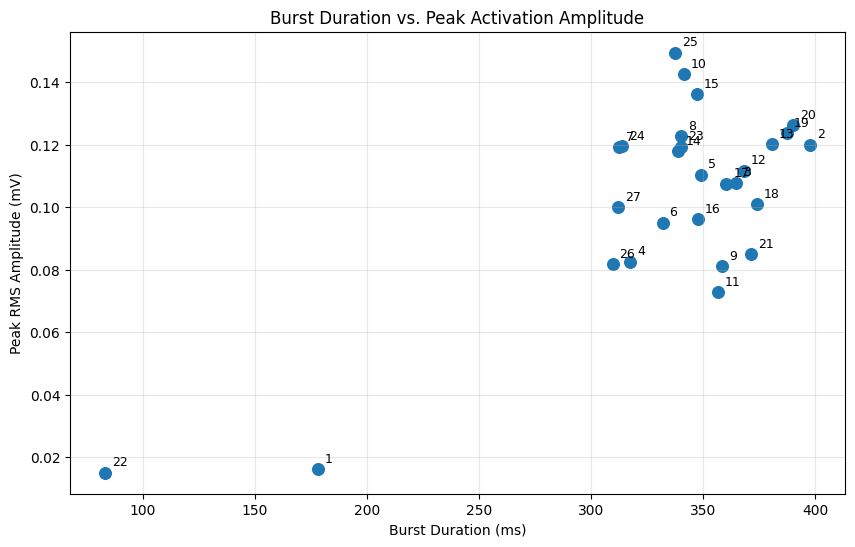

In [130]:
plt.figure(figsize=(10, 6))

plt.scatter(
    emg_features_df["Duration_ms"],
    emg_features_df["Peak_RMS_mV"],
    s=70
)

for _, row in emg_features_df.iterrows():

    plt.annotate(
        int(row["Burst_ID"]),
        (
            row["Duration_ms"],
            row["Peak_RMS_mV"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Burst Duration (ms)")
plt.ylabel("Peak RMS Amplitude (mV)")
plt.title("Burst Duration vs. Peak Activation Amplitude")
plt.grid(alpha=0.3)
plt.show()

In [131]:
emg_features_df.to_csv(
    "rectus_femoris_burst_features.csv",
    index=False
)

feature_summary_df.to_csv(
    "rectus_femoris_feature_summary.csv"
)

print("EMG features successfully exported.")

EMG features successfully exported.


In [132]:
from google.colab import files

files.download("rectus_femoris_burst_features.csv")
files.download("rectus_femoris_feature_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [133]:
duration_thresholds = [
    50, 100, 150, 175, 200, 250, 300, 350
]

qc_results = []

for threshold in duration_thresholds:

    accepted = emg_features_df[
        emg_features_df["Duration_ms"] >= threshold
    ]

    rejected = emg_features_df[
        emg_features_df["Duration_ms"] < threshold
    ]

    qc_results.append({
        "Min_Duration_ms": threshold,
        "Bursts_Retained": len(accepted),
        "Bursts_Removed": len(rejected),
        "Removed_Burst_IDs": rejected["Burst_ID"].tolist()
    })

qc_results_df = pd.DataFrame(qc_results)

display(qc_results_df)

,Min_Duration_ms,Bursts_Retained,Bursts_Removed,Removed_Burst_IDs
0,50,27,0,[]
1,100,26,1,[22]
2,150,26,1,[22]
3,175,26,1,[22]
4,200,25,2,"[1, 22]"
5,250,25,2,"[1, 22]"
6,300,25,2,"[1, 22]"
7,350,11,16,"[1, 4, 5, 6, 7, 8, 10, 14, 15, 16, 22, 23, 24,..."


In [134]:
def apply_burst_qc(
    features_df,
    min_duration_ms=200,
    min_peak_rms=None
):

    df = features_df.copy()

    df["Pass_Duration"] = (
        df["Duration_ms"] >= min_duration_ms
    )

    if min_peak_rms is not None:

        df["Pass_Amplitude"] = (
            df["Peak_RMS_mV"] >= min_peak_rms
        )

    else:

        df["Pass_Amplitude"] = True

    df["QC_Pass"] = (
        df["Pass_Duration"] &
        df["Pass_Amplitude"]
    )

    accepted = df[df["QC_Pass"]].copy()
    rejected = df[~df["QC_Pass"]].copy()

    return accepted, rejected

In [135]:
accepted_df, rejected_df = apply_burst_qc(
    emg_features_df,
    min_duration_ms=200,
    min_peak_rms=None
)

print("Original bursts:", len(emg_features_df))
print("Accepted bursts:", len(accepted_df))
print("Rejected bursts:", len(rejected_df))

display(
    rejected_df[[
        "Burst_ID",
        "Onset_s",
        "Offset_s",
        "Duration_ms",
        "Peak_RMS_mV"
    ]]
)

Original bursts: 27
Accepted bursts: 25
Rejected bursts: 2


,Burst_ID,Onset_s,Offset_s,Duration_ms,Peak_RMS_mV
0,1,0.544655,0.722948,178.293107,0.016163
21,22,25.823639,25.906966,83.327588,0.015008


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.



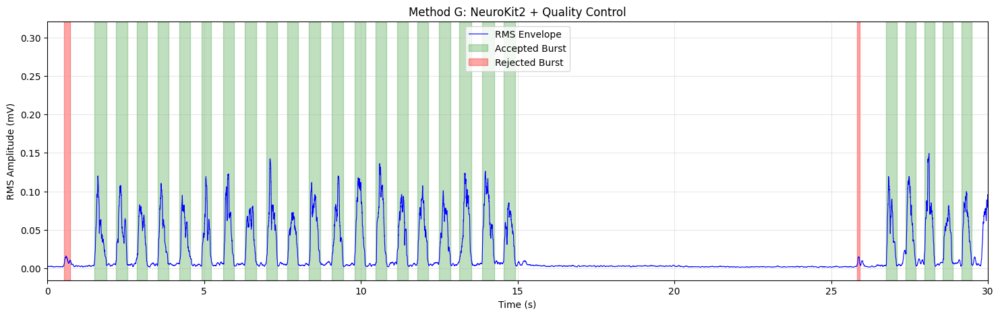

In [136]:
plt.figure(figsize=(18, 5))

plt.plot(
    feature_time,
    feature_envelope,
    color="blue",
    linewidth=0.8,
    label="RMS Envelope"
)

for i, (_, row) in enumerate(accepted_df.iterrows()):

    plt.axvspan(
        row["Onset_s"],
        row["Offset_s"],
        color="green",
        alpha=0.25,
        label="Accepted Burst" if i == 0 else None
    )

for i, (_, row) in enumerate(rejected_df.iterrows()):

    plt.axvspan(
        row["Onset_s"],
        row["Offset_s"],
        color="red",
        alpha=0.35,
        label="Rejected Burst" if i == 0 else None
    )

plt.xlabel("Time (s)")
plt.ylabel("RMS Amplitude (mV)")
plt.title("Method G: NeuroKit2 + Quality Control")
plt.xlim(0, 30)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [137]:
qc_bursts = list(
    accepted_df[["Onset_s", "Offset_s"]]
    .itertuples(index=False, name=None)
)

print("Total QC bursts:", len(qc_bursts))

print("First five bursts:")
print(qc_bursts[:5])

Total QC bursts: 25
First five bursts:
[(1.498965550838883, 1.8965172838874564), (2.1856034972635268, 2.5501035054333547), (2.8540862708674513, 3.171569036604134), (3.5211724927159356, 3.870310431575924), (4.224103542954045, 4.556017343496941)]


In [138]:
import inspect

print(inspect.signature(evaluate_detection))

(manual, detected)


In [139]:
qc_features_df = extract_emg_features(
    signal=feature_signal,
    envelope=feature_envelope,
    time=feature_time,
    bursts=qc_bursts
)

qc_summary_df = (
    qc_features_df[feature_columns]
    .describe()
    .T
)

display(qc_features_df.round(4))
display(qc_summary_df.round(4))

,Burst_ID,Onset_s,Offset_s,Duration_ms,Peak_RMS_mV,Mean_RMS_mV,Burst_RMS_mV,iEMG_mV_s,Envelope_Area_mV_s,Time_to_Peak_ms,Inter_Burst_Interval_ms,Onset_Interval_ms
0,1,1.4990,1.8965,397.5517,0.1200,0.0482,0.0572,0.0154,0.0192,117.5537,NaN,NaN
1,2,2.1856,2.5501,364.5000,0.1078,0.0537,0.0606,0.0158,0.0196,156.6572,289.0862,686.6379
2,3,2.8541,3.1716,317.4828,0.0825,0.0527,0.0571,0.0137,0.0167,94.7434,303.9828,668.4828
3,4,3.5212,3.8703,349.1379,0.1104,0.0488,0.0580,0.0138,0.0170,111.5020,349.6035,667.0862
4,5,4.2241,4.5560,331.9138,0.0950,0.0512,0.0571,0.0140,0.0170,84.0365,353.7931,702.9311
5,6,4.9219,5.2343,312.3621,0.1192,0.0529,0.0606,0.0129,0.0165,140.3640,365.8966,697.8104
6,7,5.6211,5.9614,340.2931,0.1227,0.0610,0.0714,0.0163,0.0208,160.8468,386.8448,699.2069
7,8,6.3008,6.6592,358.4483,0.0810,0.0509,0.0555,0.0150,0.0182,252.5537,339.3621,679.6552
8,9,6.9911,7.3324,341.2241,0.1425,0.0670,0.0750,0.0179,0.0229,117.5536,331.9138,690.3621
9,10,7.6480,8.0046,356.5862,0.0728,0.0455,0.0494,0.0134,0.0162,196.6916,315.6207,656.8448


,count,mean,std,min,25%,50%,75%,max
Duration_ms,25.0,349.9386,25.6262,309.5690,337.5000,347.7414,368.2241,397.5517
Peak_RMS_mV,25.0,0.1099,0.0198,0.0728,0.0962,0.1116,0.1201,0.1494
Mean_RMS_mV,25.0,0.0570,0.0077,0.0455,0.0512,0.0547,0.0610,0.0708
Burst_RMS_mV,25.0,0.0644,0.0089,0.0494,0.0572,0.0628,0.0714,0.0801
iEMG_mV_s,25.0,0.0161,0.0024,0.0119,0.0146,0.0157,0.0176,0.0219
Envelope_Area_mV_s,25.0,0.0199,0.0030,0.0147,0.0180,0.0196,0.0220,0.0273
Time_to_Peak_ms,25.0,143.3990,41.6029,84.0365,111.5020,144.5536,165.9673,252.5537
Inter_Burst_Interval_ms,24.0,801.0582,2347.1292,256.0345,296.5345,329.3535,350.6509,11819.4830
Onset_Interval_ms,24.0,1152.5819,2351.4796,593.5345,660.6854,683.3793,698.1595,12190.9658


In [140]:
summary_comparison_df = pd.DataFrame({
    "Original_Mean":
        emg_features_df[feature_columns].mean(),

    "QC_Mean":
        qc_features_df[feature_columns].mean(),

    "Original_SD":
        emg_features_df[feature_columns].std(),

    "QC_SD":
        qc_features_df[feature_columns].std()
})

display(summary_comparison_df.round(4))

,Original_Mean,QC_Mean,Original_SD,QC_SD
Duration_ms,333.7069,349.9386,64.8047,25.6262
Peak_RMS_mV,0.1029,0.1099,0.0316,0.0198
Mean_RMS_mV,0.0536,0.0570,0.0143,0.0077
Burst_RMS_mV,0.0605,0.0644,0.0165,0.0089
iEMG_mV_s,0.0150,0.0161,0.0046,0.0024
Envelope_Area_mV_s,0.0186,0.0199,0.0057,0.0030
Time_to_Peak_ms,136.6052,143.3990,46.8935,41.6029
Inter_Burst_Interval_ms,766.0803,801.0582,2070.6245,2347.1292
Onset_Interval_ms,1100.6260,1152.5819,2075.3015,2351.4796


In [141]:
qc_features_df.to_csv(
    "rectus_femoris_qc_features.csv",
    index=False
)

qc_summary_df.to_csv(
    "rectus_femoris_qc_summary.csv"
)

rejected_df.to_csv(
    "rectus_femoris_rejected_bursts.csv",
    index=False
)

qc_results_df.to_csv(
    "duration_threshold_comparison.csv",
    index=False
)

In [142]:
import inspect

print(inspect.signature(evaluate_detection))

(manual, detected)


In [143]:
print(inspect.getsource(evaluate_detection))

def evaluate_detection(manual, detected):

    manual = np.asarray(manual).reshape(-1, 2)
    detected = np.asarray(detected).reshape(-1, 2)

    matches = match_bursts(manual, detected)

    TP = len(matches)
    FP = len(detected) - TP
    FN = len(manual) - TP

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    onset_errors = []
    offset_errors = []
    duration_errors = []

    for i, j in matches:

        m_start, m_end = manual[i]
        d_start, d_end = detected[j]

        onset_errors.append(
            abs(d_start - m_start) * 1000
        )

        offset_errors.append(
            abs(d_end - m_end) * 1000
        )

        duration_errors.append(
            abs(
                (d_end - d_start) -
                (m_end - m_start)
            ) * 1000
        )

    return {
        "TP": TP,
        "FP": FP,

In [144]:
qc_bursts = list(
    accepted_df[["Onset_s", "Offset_s"]]
    .itertuples(index=False, name=None)
)

print("Number of QC bursts:", len(qc_bursts))

print("\nFirst five QC bursts:")
print(qc_bursts[:5])

print("\nFirst five manual bursts:")
print(manual_bursts[:5])

Number of QC bursts: 25

First five QC bursts:
[(1.498965550838883, 1.8965172838874564), (2.1856034972635268, 2.5501035054333547), (2.8540862708674513, 3.171569036604134), (3.5211724927159356, 3.870310431575924), (4.224103542954045, 4.556017343496941)]

First five manual bursts:
[(1.49, 1.9), (2.18, 2.55), (2.82, 3.2), (3.52, 3.86), (4.22, 4.62)]


In [145]:
import inspect

print(inspect.signature(evaluate_detection))
print(inspect.getsource(evaluate_detection))

(manual, detected)
def evaluate_detection(manual, detected):

    manual = np.asarray(manual).reshape(-1, 2)
    detected = np.asarray(detected).reshape(-1, 2)

    matches = match_bursts(manual, detected)

    TP = len(matches)
    FP = len(detected) - TP
    FN = len(manual) - TP

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    onset_errors = []
    offset_errors = []
    duration_errors = []

    for i, j in matches:

        m_start, m_end = manual[i]
        d_start, d_end = detected[j]

        onset_errors.append(
            abs(d_start - m_start) * 1000
        )

        offset_errors.append(
            abs(d_end - m_end) * 1000
        )

        duration_errors.append(
            abs(
                (d_end - d_start) -
                (m_end - m_start)
            ) * 1000
        )

    return {
        "TP": TP

In [146]:
results_G = evaluate_detection(
    qc_bursts,
    manual_bursts
)

print(results_G)

{'TP': 25, 'FP': 0, 'FN': 0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Onset_MAE_ms': np.float64(18.859469233057535), 'Offset_MAE_ms': np.float64(16.199129138255834), 'Duration_MAE_ms': np.float64(32.80482214424574)}


In [147]:
import pandas as pd

method_G_results = {
    "Method": "G: NeuroKit2 + QC",
    "TP": 25,
    "FP": 0,
    "FN": 0,
    "Precision": 1.0,
    "Recall": 1.0,
    "F1": 1.0,
    "Onset_MAE_ms": 18.859469233057535,
    "Offset_MAE_ms": 16.199129138255834,
    "Duration_MAE_ms": 32.80482214424574
}

# Identify the existing validation comparison table
required_columns = set(method_G_results.keys())

candidate_tables = [
    name for name, obj in list(globals().items())
    if isinstance(obj, pd.DataFrame)
    and required_columns.issubset(obj.columns)
]

print("Available validation tables:", candidate_tables)

Available validation tables: ['validation_df', 'final_validation_df', 'shortlisted_df']


In [148]:
original_validation_df = globals()[candidate_tables[0]].copy()

# Prevent duplicate Method G entries if rerunning
original_validation_df = original_validation_df[
    original_validation_df["Method"] != "G: NeuroKit2 + QC"
]

final_validation_df = pd.concat(
    [
        original_validation_df,
        pd.DataFrame([method_G_results])
    ],
    ignore_index=True
)

final_validation_df = final_validation_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

display(final_validation_df.round(4))

,Method,TP,FP,FN,Precision,Recall,F1,Onset_MAE_ms,Offset_MAE_ms,Duration_MAE_ms
0,G: NeuroKit2 + QC,25,0,0,1.0000,1.00,1.0000,18.8595,16.1991,32.8048
1,B: Single 20 SD,25,1,0,0.9615,1.00,0.9804,29.2133,28.0612,57.2745
2,E: Hysteresis 20/10,25,3,0,0.8929,1.00,0.9434,29.2133,16.0496,44.8545
3,A: Single 15 SD,25,4,0,0.8621,1.00,0.9259,23.2175,22.3074,45.5248
4,C: Gap Merging,23,5,2,0.8214,0.92,0.8679,34.5127,24.0029,53.3673
5,D: Hysteresis 10/5,25,9,0,0.7353,1.00,0.8475,21.4819,27.3028,43.6862


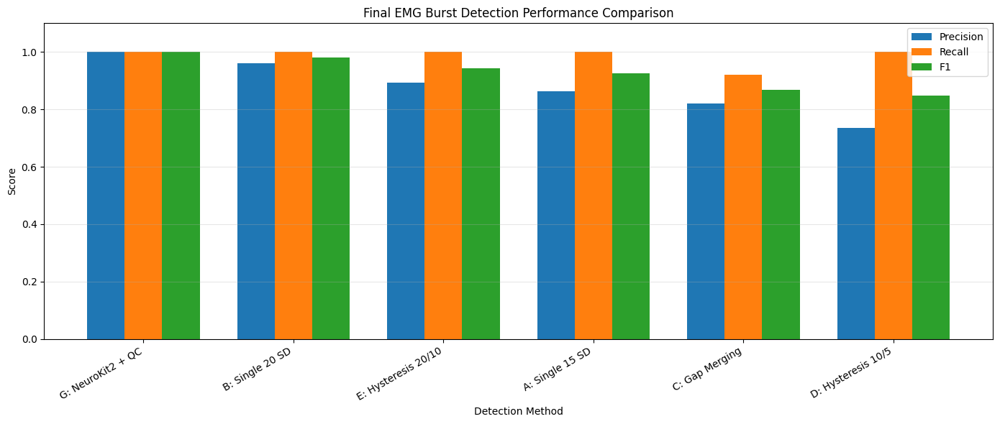

In [149]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(final_validation_df))
width = 0.25

plt.figure(figsize=(14, 6))

plt.bar(
    x - width,
    final_validation_df["Precision"],
    width,
    label="Precision"
)

plt.bar(
    x,
    final_validation_df["Recall"],
    width,
    label="Recall"
)

plt.bar(
    x + width,
    final_validation_df["F1"],
    width,
    label="F1"
)

plt.xticks(
    x,
    final_validation_df["Method"],
    rotation=30,
    ha="right"
)

plt.ylabel("Score")
plt.xlabel("Detection Method")
plt.title("Final EMG Burst Detection Performance Comparison")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

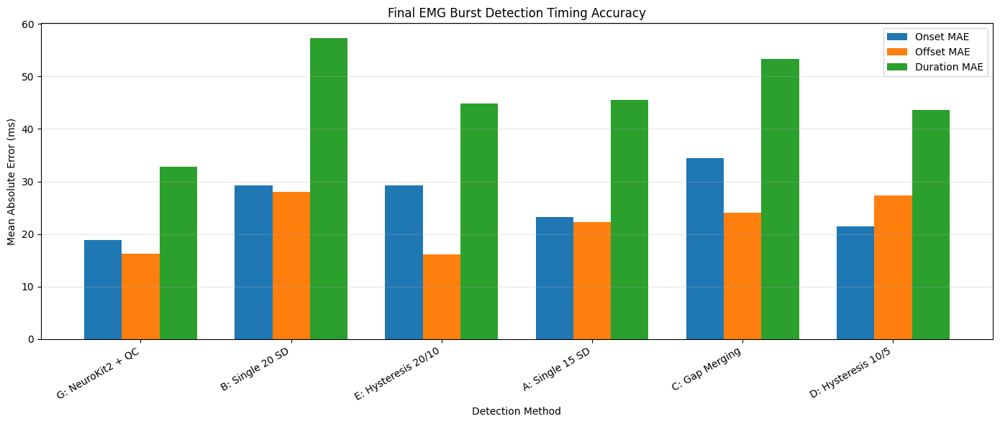

In [150]:
plt.figure(figsize=(14, 6))

plt.bar(
    x - width,
    final_validation_df["Onset_MAE_ms"],
    width,
    label="Onset MAE"
)

plt.bar(
    x,
    final_validation_df["Offset_MAE_ms"],
    width,
    label="Offset MAE"
)

plt.bar(
    x + width,
    final_validation_df["Duration_MAE_ms"],
    width,
    label="Duration MAE"
)

plt.xticks(
    x,
    final_validation_df["Method"],
    rotation=30,
    ha="right"
)

plt.ylabel("Mean Absolute Error (ms)")
plt.xlabel("Detection Method")
plt.title("Final EMG Burst Detection Timing Accuracy")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [151]:
final_validation_df.to_csv(
    "EMG_Final_Method_Comparison.csv",
    index=False
)

from google.colab import files

files.download("EMG_Final_Method_Comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [152]:
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

behavior: (42, 23)
emg_data: (2228044, 10)
signals_pilot: (64444, 6)
results_df: (9, 5)
pivot: (3, 3)
extended_df: (6, 4)
gap_df: (4, 4)
comparison_df: (5, 6)
manual_df: (25, 4)
validation_df: (5, 10)
nk_signals: (64444, 6)
nk_burst_df: (27, 3)
final_validation_df: (6, 10)
shortlisted_df: (3, 10)
emg_features_df: (27, 12)
feature_summary_df: (9, 8)
accepted: (11, 12)
rejected: (16, 12)
qc_results_df: (8, 4)
accepted_df: (25, 15)
rejected_df: (2, 15)
qc_features_df: (25, 12)
qc_summary_df: (9, 8)
summary_comparison_df: (9, 4)
original_validation_df: (5, 10)


In [154]:
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

behavior: (42, 23)
emg_data: (2228044, 10)
signals_pilot: (64444, 6)
results_df: (9, 5)
pivot: (3, 3)
extended_df: (6, 4)
gap_df: (4, 4)
comparison_df: (5, 6)
manual_df: (25, 4)
validation_df: (5, 10)
nk_signals: (64444, 6)
nk_burst_df: (27, 3)
final_validation_df: (6, 10)
shortlisted_df: (3, 10)
emg_features_df: (27, 12)
feature_summary_df: (9, 8)
accepted: (11, 12)
rejected: (16, 12)
qc_results_df: (8, 4)
accepted_df: (25, 15)
rejected_df: (2, 15)
qc_features_df: (25, 12)
qc_summary_df: (9, 8)
summary_comparison_df: (9, 4)
original_validation_df: (5, 10)


In [155]:
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

behavior: (42, 23)
emg_data: (2228044, 10)
signals_pilot: (64444, 6)
results_df: (9, 5)
pivot: (3, 3)
extended_df: (6, 4)
gap_df: (4, 4)
comparison_df: (5, 6)
manual_df: (25, 4)
validation_df: (5, 10)
nk_signals: (64444, 6)
nk_burst_df: (27, 3)
final_validation_df: (6, 10)
shortlisted_df: (3, 10)
emg_features_df: (27, 12)
feature_summary_df: (9, 8)
accepted: (11, 12)
rejected: (16, 12)
qc_results_df: (8, 4)
accepted_df: (25, 15)
rejected_df: (2, 15)
qc_features_df: (25, 12)
qc_summary_df: (9, 8)
summary_comparison_df: (9, 4)
original_validation_df: (5, 10)


In [156]:
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if not name.startswith("_"):
            print(f"\nDataFrame: {name}")
            print(f"Shape: {obj.shape}")
            print(f"Columns: {obj.columns.tolist()}")


DataFrame: behavior
Shape: (42, 23)
Columns: ['thisRow.t', 'notes', 'phase', 'block', 'sd', 'distance', 'calibration_presses', 'calibrated_max', 'mapping', 'trial', 'trial_in_block', 'stimID', 'threshold', 'presses', 'success', 'predicted_success', 'assessment_index', 'choice', 'correct', 'rt', 'interoceptive_index', 'target_mean', 'Unnamed: 22']

DataFrame: emg_data
Shape: (2228044, 10)
Columns: ['Soleus_Time', 'Soleus_EMG', 'TibAnt_Time', 'TibAnt_EMG', 'GastrocMed_Time', 'GastrocMed_EMG', 'VastusMed_Time', 'VastusMed_EMG', 'RectusFem_Time', 'RectusFem_EMG']

DataFrame: signals_pilot
Shape: (64444, 6)
Columns: ['EMG_Raw', 'EMG_Clean', 'EMG_Amplitude', 'EMG_Activity', 'EMG_Onsets', 'EMG_Offsets']

DataFrame: results_df
Shape: (9, 5)
Columns: ['k', 'Min_Duration_ms', 'Threshold_mV', 'Burst_Count', 'Mean_Burst_Duration_s']

DataFrame: pivot
Shape: (3, 3)
Columns: [20, 50, 100]

DataFrame: extended_df
Shape: (6, 4)
Columns: ['k', 'Threshold_mV', 'Burst_Count', 'Mean_Duration_s']

DataFra

In [157]:
print("EMG dataset shape:", emg_data.shape)

print("\nAvailable columns:")

for i, col in enumerate(emg_data.columns):
    print(f"{i}: {col}")

display(emg_data.head(10))

EMG dataset shape: (2228044, 10)

Available columns:
0: Soleus_Time
1: Soleus_EMG
2: TibAnt_Time
3: TibAnt_EMG
4: GastrocMed_Time
5: GastrocMed_EMG
6: VastusMed_Time
7: VastusMed_EMG
8: RectusFem_Time
9: RectusFem_EMG


,Soleus_Time,Soleus_EMG,TibAnt_Time,TibAnt_EMG,GastrocMed_Time,GastrocMed_EMG,VastusMed_Time,VastusMed_EMG,RectusFem_Time,RectusFem_EMG
0,0.000243,0.002518,0.000243,0.026017,0.000243,-0.017288,0.000243,-0.015442,0.000243,0.001511
1,0.000709,0.001175,0.000709,0.028031,0.000709,-0.019303,0.000709,-0.014939,0.000709,-0.001007
2,0.001174,-0.000168,0.001174,0.028534,0.001174,-0.020981,0.001174,-0.015610,0.001174,-0.002182
3,0.001640,0.000839,0.001640,0.029374,0.001640,-0.018296,0.001640,-0.016953,0.001640,-0.003525
4,0.002106,0.002518,0.002106,0.031388,0.002106,-0.016281,0.002106,-0.017792,0.002106,-0.005036
5,0.002571,0.004364,0.002571,0.033066,0.002571,-0.017624,0.002571,-0.017792,0.002571,-0.005036
6,0.003037,0.006210,0.003037,0.034745,0.003037,-0.020646,0.003037,-0.017624,0.003037,-0.002853
7,0.003502,0.006882,0.003502,0.033402,0.003502,-0.020981,0.003502,-0.017288,0.003502,-0.001679
8,0.003968,0.004868,0.003968,0.029374,0.003968,-0.018967,0.003968,-0.017624,0.003968,-0.002182
9,0.004433,0.001511,0.004433,0.026352,0.004433,-0.016281,0.004433,-0.016281,0.004433,-0.001846


In [158]:
muscle_channels = {
    "Soleus": {
        "time": "Soleus_Time",
        "emg": "Soleus_EMG"
    },
    "Tibialis Anterior": {
        "time": "TibAnt_Time",
        "emg": "TibAnt_EMG"
    },
    "Medial Gastrocnemius": {
        "time": "GastrocMed_Time",
        "emg": "GastrocMed_EMG"
    },
    "Vastus Medialis": {
        "time": "VastusMed_Time",
        "emg": "VastusMed_EMG"
    },
    "Rectus Femoris": {
        "time": "RectusFem_Time",
        "emg": "RectusFem_EMG"
    }
}

print("Number of muscle channels:", len(muscle_channels))

for muscle, columns in muscle_channels.items():
    print(muscle, ":", columns)

Number of muscle channels: 5
Soleus : {'time': 'Soleus_Time', 'emg': 'Soleus_EMG'}
Tibialis Anterior : {'time': 'TibAnt_Time', 'emg': 'TibAnt_EMG'}
Medial Gastrocnemius : {'time': 'GastrocMed_Time', 'emg': 'GastrocMed_EMG'}
Vastus Medialis : {'time': 'VastusMed_Time', 'emg': 'VastusMed_EMG'}
Rectus Femoris : {'time': 'RectusFem_Time', 'emg': 'RectusFem_EMG'}


In [159]:
import numpy as np
import pandas as pd

channel_info = []

for muscle, columns in muscle_channels.items():

    t = pd.to_numeric(
        emg_data[columns["time"]],
        errors="coerce"
    ).to_numpy()

    x = pd.to_numeric(
        emg_data[columns["emg"]],
        errors="coerce"
    ).to_numpy()

    valid = np.isfinite(t) & np.isfinite(x)

    t_valid = t[valid]
    x_valid = x[valid]

    dt = np.diff(t_valid)
    positive_dt = dt[dt > 0]

    estimated_fs = (
        1 / np.median(positive_dt)
        if len(positive_dt) > 0
        else np.nan
    )

    channel_info.append({
        "Muscle": muscle,
        "Total_Samples": len(x),
        "Valid_Samples": len(x_valid),
        "Missing_Time": np.sum(~np.isfinite(t)),
        "Missing_EMG": np.sum(~np.isfinite(x)),
        "Start_Time_s": t_valid[0],
        "End_Time_s": t_valid[-1],
        "Duration_s": t_valid[-1] - t_valid[0],
        "Sampling_Rate_Hz": estimated_fs,
        "Duplicate_Timestamps": np.sum(dt == 0),
        "Negative_Time_Steps": np.sum(dt < 0),
        "Large_Time_Gaps": np.sum(
            dt > 1.5 * np.median(positive_dt)
        ),
        "Min_EMG": np.min(x_valid),
        "Max_EMG": np.max(x_valid)
    })

channel_info_df = pd.DataFrame(channel_info)

display(channel_info_df.round(4))

,Muscle,Total_Samples,Valid_Samples,Missing_Time,Missing_EMG,Start_Time_s,End_Time_s,Duration_s,Sampling_Rate_Hz,Duplicate_Timestamps,Negative_Time_Steps,Large_Time_Gaps,Min_EMG,Max_EMG
0,Soleus,2228044,2228044,0,0,0.0002,1037.1927,1037.1924,2148.2277,0,0,0,-5.4937,5.0984
1,Tibialis Anterior,2228044,2228044,0,0,0.0002,1037.1927,1037.1924,2148.2277,0,0,0,-5.4937,5.4999
2,Medial Gastrocnemius,2228044,2228044,0,0,0.0002,1037.1927,1037.1924,2148.2277,0,0,0,-5.4942,4.7023
3,Vastus Medialis,2228044,2228044,0,0,0.0002,1037.1927,1037.1924,2148.2277,0,0,0,-5.3671,5.4670
4,Rectus Femoris,2228044,2228044,0,0,0.0002,1037.1927,1037.1924,2148.2277,0,0,0,-0.4748,1.1006


In [160]:
reference_time = emg_data[
    "RectusFem_Time"
].to_numpy(dtype=float)

sync_results = []

for muscle, columns in muscle_channels.items():

    muscle_time = emg_data[
        columns["time"]
    ].to_numpy(dtype=float)

    valid = (
        np.isfinite(muscle_time) &
        np.isfinite(reference_time)
    )

    differences = (
        muscle_time[valid] -
        reference_time[valid]
    )

    sync_results.append({
        "Muscle": muscle,
        "Mean_Time_Difference_ms":
            np.mean(differences) * 1000,
        "Max_Absolute_Difference_ms":
            np.max(np.abs(differences)) * 1000,
        "Identical_Timestamps":
            np.array_equal(
                muscle_time,
                reference_time,
                equal_nan=True
            )
    })

sync_df = pd.DataFrame(sync_results)

display(sync_df.round(6))

,Muscle,Mean_Time_Difference_ms,Max_Absolute_Difference_ms,Identical_Timestamps
0,Soleus,0.0,0.0,True
1,Tibialis Anterior,0.0,0.0,True
2,Medial Gastrocnemius,0.0,0.0,True
3,Vastus Medialis,0.0,0.0,True
4,Rectus Femoris,0.0,0.0,True


In [161]:
pilot_start = 0
pilot_end = 30

multichannel_pilot = {}

for muscle, columns in muscle_channels.items():

    t = emg_data[
        columns["time"]
    ].to_numpy(dtype=float)

    x = emg_data[
        columns["emg"]
    ].to_numpy(dtype=float)

    mask = (
        (t >= pilot_start) &
        (t < pilot_end)
    )

    multichannel_pilot[muscle] = {
        "time": t[mask],
        "raw": x[mask]
    }

    print(
        muscle,
        "| Samples:",
        len(x[mask])
    )

Soleus | Samples: 64444
Tibialis Anterior | Samples: 64444
Medial Gastrocnemius | Samples: 64444
Vastus Medialis | Samples: 64444
Rectus Femoris | Samples: 64444


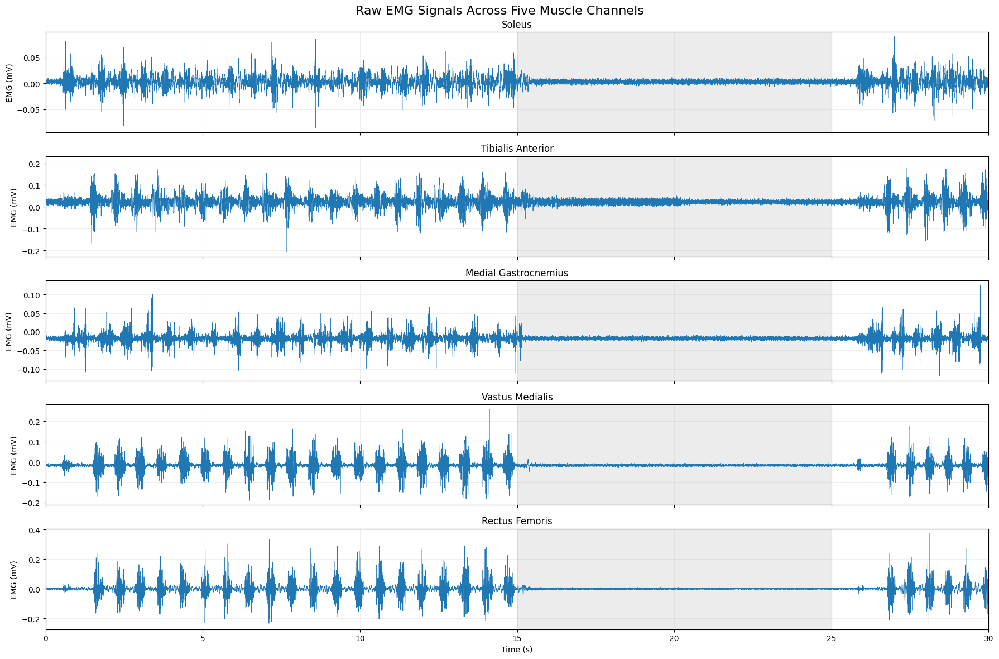

In [162]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    5, 1,
    figsize=(18, 12),
    sharex=True
)

for ax, (muscle, data) in zip(
    axes,
    multichannel_pilot.items()
):

    ax.plot(
        data["time"],
        data["raw"],
        linewidth=0.6
    )

    ax.set_title(muscle)
    ax.set_ylabel("EMG (mV)")
    ax.grid(alpha=0.2)

    # Expected first scheduled rest period
    ax.axvspan(
        15, 25,
        color="gray",
        alpha=0.15
    )

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 30)

fig.suptitle(
    "Raw EMG Signals Across Five Muscle Channels",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [163]:
import inspect

for name, obj in list(globals().items()):

    if inspect.isfunction(obj):

        if obj.__module__ == "__main__":

            print(
                name,
                inspect.signature(obj)
            )

detect_bursts (envelope, threshold, fs, min_duration_ms=50)
detect_bursts_improved (envelope, threshold, fs, min_duration_ms=50, min_gap_ms=50)
detect_bursts_hysteresis (envelope, onset_threshold, offset_threshold, fs, min_duration_ms=50)
annotation_plot (start_time, end_time)
match_bursts (manual, detected, iou_threshold=0.5)
evaluate_detection (manual, detected)
filter_evaluation_bursts (bursts)
inspect_evaluation_window (bursts, name)
extract_emg_features (signal, envelope, time, bursts)
apply_burst_qc (features_df, min_duration_ms=200, min_peak_rms=None)


In [165]:
method_F_results = {
    "Method": "F: NeuroKit2",
    "TP": 25,
    "FP": 2,
    "FN": 0,
    "Precision": 25 / 27,
    "Recall": 1.0,
    "F1": 50 / 52,
    "Onset_MAE_ms": 18.859469233057535,
    "Offset_MAE_ms": 16.199129138255834,
    "Duration_MAE_ms": 32.80482214424574
}

final_validation_df = pd.concat(
    [
        validation_df,
        pd.DataFrame([
            method_F_results,
            method_G_results
        ])
    ],
    ignore_index=True
)

final_validation_df = (
    final_validation_df
    .drop_duplicates(subset="Method")
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

display(final_validation_df.round(4))

print("Total methods:", len(final_validation_df))

assert len(final_validation_df) == 7

,Method,TP,FP,FN,Precision,Recall,F1,Onset_MAE_ms,Offset_MAE_ms,Duration_MAE_ms
0,G: NeuroKit2 + QC,25,0,0,1.0000,1.00,1.0000,18.8595,16.1991,32.8048
1,B: Single 20 SD,25,1,0,0.9615,1.00,0.9804,29.2133,28.0612,57.2745
2,F: NeuroKit2,25,2,0,0.9259,1.00,0.9615,18.8595,16.1991,32.8048
3,E: Hysteresis 20/10,25,3,0,0.8929,1.00,0.9434,29.2133,16.0496,44.8545
4,A: Single 15 SD,25,4,0,0.8621,1.00,0.9259,23.2175,22.3074,45.5248
5,C: Gap Merging,23,5,2,0.8214,0.92,0.8679,34.5127,24.0029,53.3673
6,D: Hysteresis 10/5,25,9,0,0.7353,1.00,0.8475,21.4819,27.3028,43.6862


Total methods: 7


In [166]:
final_validation_df.to_csv(
    "EMG_Final_Method_Comparison.csv",
    index=False
)

In [167]:
emg_config = {
    "sampling_rate": 2148.2277,
    "pilot_start_s": 0,
    "pilot_end_s": 30,
    "detection_method": "NeuroKit2",
    "min_burst_duration_ms": 200,
    "min_peak_rms": None,
    "apply_quality_control": True
}

for key, value in emg_config.items():
    print(f"{key}: {value}")

sampling_rate: 2148.2277
pilot_start_s: 0
pilot_end_s: 30
detection_method: NeuroKit2
min_burst_duration_ms: 200
min_peak_rms: None
apply_quality_control: True


In [168]:
keywords = [
    "nk.emg_process(",
    "nk.emg_clean(",
    "nk.emg_activation(",
    "nk.emg_amplitude(",
    "butter(",
    "filtfilt(",
    "sosfiltfilt(",
    "iirnotch(",
    "feature_signal =",
    "feature_envelope =",
    "feature_time =",
    "nk_bursts ="
]

for i, cell in enumerate(In):

    if any(keyword in cell for keyword in keywords):

        # Exclude this search cell
        if "keywords = [" in cell:
            continue

        print(f"\n{'=' * 60}")
        print(f"Cell {i}")
        print("=" * 60)
        print(cell)


Cell 15
lowcut = 20
highcut = 450

sos = butter(
    4,
    [lowcut, highcut],
    btype="bandpass",
    fs=fs,
    output="sos"
)

emg_filtered = sosfiltfilt(sos, emg_raw)

Cell 20
import neurokit2 as nk

pilot_segment = emg_raw[mask]
time_segment = time[mask]

signals_pilot, info_pilot = nk.emg_process(
    pilot_segment,
    sampling_rate=fs
)

print(signals_pilot.columns)

nk.emg_plot(signals_pilot, info_pilot)
plt.show()

Cell 100
nk_signals, nk_info = nk.emg_process(
    raw_segment,
    sampling_rate=fs
)

display(nk_signals.head())

print(nk_signals.columns.tolist())

Cell 102
# Extract the same 30-second raw EMG segment
mask = (time >= 0) & (time < 30)

raw_segment = emg_raw[mask]
time_segment = time[mask]

# Verify the segment
print("Sampling rate:", fs, "Hz")
print("Raw segment samples:", len(raw_segment))
print("RMS segment samples:", len(rms_segment))
print("Duration:", len(raw_segment) / fs, "seconds")

# Process using NeuroKit2
nk_signals, nk_info = nk.emg_process(
    

In [169]:
import inspect

print("FEATURE EXTRACTION FUNCTION")
print("=" * 60)
print(inspect.getsource(extract_emg_features))

print("\nQUALITY CONTROL FUNCTION")
print("=" * 60)
print(inspect.getsource(apply_burst_qc))

FEATURE EXTRACTION FUNCTION
def extract_emg_features(signal, envelope, time, bursts):

    signal = np.asarray(signal)
    envelope = np.asarray(envelope)
    time = np.asarray(time)

    features = []
    previous_offset = None
    previous_onset = None

    for i, (onset, offset) in enumerate(sorted(bursts)):

        if onset < time[0] or offset > time[-1] or offset <= onset:
            continue

        # Convert burst times to sample indices
        start_idx = np.searchsorted(time, onset)
        end_idx = np.searchsorted(time, offset, side="right")

        # Extract individual burst
        burst_signal = signal[start_idx:end_idx]
        burst_envelope = envelope[start_idx:end_idx]
        burst_time = time[start_idx:end_idx]

        if len(burst_signal) < 2:
            continue

        # Timing features
        duration_ms = (offset - onset) * 1000

        # Amplitude features
        peak_rms = np.max(burst_envelope)
        mean_rms = np.mean(burst_envelope)

        b

In [170]:
import numpy as np

variables_to_check = [
    "fs",
    "fs_pilot",
    "feature_signal",
    "feature_envelope",
    "feature_time",
    "nk_bursts",
    "qc_bursts"
]

for name in variables_to_check:

    if name in globals():

        value = globals()[name]

        print(f"\nVariable: {name}")
        print(f"Type: {type(value)}")

        if np.isscalar(value):
            print("Value:", value)

        else:
            arr = np.asarray(value)

            print("Shape:", arr.shape)
            print("First five values:", arr[:5])

    else:
        print(f"\n{name}: Not defined")


Variable: fs
Type: <class 'float'>
Value: 2148.1481

fs_pilot: Not defined

Variable: feature_signal
Type: <class 'numpy.ndarray'>
Shape: (2228044,)
First five values: [ 0.00017201 -0.00175054 -0.00361479 -0.00517143 -0.00593063]

Variable: feature_envelope
Type: <class 'numpy.ndarray'>
Shape: (2228044,)
First five values: [0.00302747 0.00301428 0.0029972  0.00298308 0.00297093]

Variable: feature_time
Type: <class 'numpy.ndarray'>
Shape: (2228044,)
First five values: [0.0002434 0.000709  0.0011745 0.00164   0.0021055]

Variable: nk_bursts
Type: <class 'list'>
Shape: (27, 2)
First five values: [[0.54465518 0.72294829]
 [1.49896555 1.89651728]
 [2.1856035  2.55010351]
 [2.85408627 3.17156904]
 [3.52117249 3.87031043]]

Variable: qc_bursts
Type: <class 'list'>
Shape: (25, 2)
First five values: [[1.49896555 1.89651728]
 [2.1856035  2.55010351]
 [2.85408627 3.17156904]
 [3.52117249 3.87031043]
 [4.22410354 4.55601734]]


In [171]:
emg_config = {
    "sampling_rate": float(fs),

    # Preprocessing
    "lowcut_hz": 20,
    "highcut_hz": 450,
    "filter_order": 4,

    # Feature extraction
    "rms_window_ms": 50,

    # Detection
    "detection_method": "NeuroKit2",
    "pilot_start_s": 0,
    "pilot_end_s": 30,

    # Quality control
    "apply_quality_control": True,
    "min_burst_duration_ms": 200,
    "min_peak_rms": None,

    # Validation
    "iou_threshold": 0.5
}

for key, value in emg_config.items():
    print(f"{key}: {value}")

sampling_rate: 2148.1481
lowcut_hz: 20
highcut_hz: 450
filter_order: 4
rms_window_ms: 50
detection_method: NeuroKit2
pilot_start_s: 0
pilot_end_s: 30
apply_quality_control: True
min_burst_duration_ms: 200
min_peak_rms: None
iou_threshold: 0.5


In [172]:
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

def preprocess_emg(
    raw_signal,
    fs,
    lowcut=20,
    highcut=450,
    order=4
):

    raw_signal = np.asarray(
        raw_signal,
        dtype=float
    ).squeeze()

    # Validate input
    if raw_signal.ndim != 1:
        raise ValueError("EMG signal must be one-dimensional.")

    if not np.all(np.isfinite(raw_signal)):
        raise ValueError("EMG signal contains invalid values.")

    if not 0 < lowcut < highcut < fs / 2:
        raise ValueError("Invalid bandpass cutoff frequencies.")

    # Design Butterworth bandpass filter
    sos = butter(
        order,
        [lowcut, highcut],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    # Apply zero-phase filtering
    filtered_signal = sosfiltfilt(
        sos,
        raw_signal
    )

    return filtered_signal

In [173]:
test_filtered = preprocess_emg(
    raw_signal=emg_data["RectusFem_EMG"].to_numpy(),
    fs=emg_config["sampling_rate"],
    lowcut=emg_config["lowcut_hz"],
    highcut=emg_config["highcut_hz"],
    order=emg_config["filter_order"]
)

print("Original filtered shape:", feature_signal.shape)
print("New filtered shape:", test_filtered.shape)

print(
    "Signals match:",
    np.allclose(
        test_filtered,
        feature_signal
    )
)

print(
    "Maximum absolute difference:",
    np.max(
        np.abs(test_filtered - feature_signal)
    )
)

Original filtered shape: (2228044,)
New filtered shape: (2228044,)
Signals match: True
Maximum absolute difference: 0.0


In [174]:
rms_keywords = [
    "rms_results",
    "np.convolve(",
    "uniform_filter1d(",
    ".rolling(",
    "window_samples",
    "window_size"
]

for i, cell in enumerate(In):

    if "rms_keywords = [" in cell:
        continue

    if any(keyword in cell for keyword in rms_keywords):

        print(f"\n{'=' * 60}")
        print(f"Cell {i}")
        print("=" * 60)
        print(cell)


Cell 18
window_sizes = [25, 50, 100]

rms_results = {}

for window_ms in window_sizes:

    window_samples = max(
        1, round(window_ms * fs / 1000)
    )

    mean_squared = uniform_filter1d(
        emg_filtered**2,
        size=window_samples
    )

    rms_results[window_ms] = np.sqrt(
        np.maximum(mean_squared, 0)
    )

    print(
        f"{window_ms} ms = {window_samples} samples"
    )

Cell 19
fig, ax = plt.subplots(
    4, 1, figsize=(16, 10), sharex=True
)

ax[0].plot(time[mask], emg_filtered[mask])
ax[0].set_title("Filtered EMG")

for i, window_ms in enumerate(window_sizes):

    ax[i+1].plot(
        time[mask],
        rms_results[window_ms][mask]
    )

    ax[i+1].set_title(
        f"RMS Envelope - {window_ms} ms"
    )

for axis in ax:
    axis.set_ylabel("Amplitude (mV)")
    axis.grid(alpha=0.3)

ax[-1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

Cell 21
fig, ax = plt.subplots(
    3, 1, figsize=(16, 8), sharex=True
)

ax[0].plot(time_segment

In [175]:
import neurokit2 as nk

def detect_bursts_neurokit(
    raw_signal,
    fs,
    start_time_s=0
):

    raw_signal = np.asarray(
        raw_signal,
        dtype=float
    ).squeeze()

    # NeuroKit2 processing
    signals, info = nk.emg_process(
        raw_signal,
        sampling_rate=fs
    )

    # Extract binary muscle activity
    activity = (
        signals["EMG_Activity"].to_numpy() > 0
    )

    # Identify transitions
    transitions = np.diff(
        np.concatenate(
            ([0], activity.astype(int), [0])
        )
    )

    start_indices = np.where(
        transitions == 1
    )[0]

    end_indices = np.where(
        transitions == -1
    )[0]

    # Convert sample indices into seconds
    bursts = [
        (
            start_time_s + start / fs,
            start_time_s + end / fs
        )
        for start, end in zip(
            start_indices,
            end_indices
        )
    ]

    return bursts, signals, info

In [176]:
rectus_pilot = multichannel_pilot["Rectus Femoris"]

test_bursts, test_signals, test_info = (
    detect_bursts_neurokit(
        raw_signal=rectus_pilot["raw"],
        fs=emg_config["sampling_rate"],
        start_time_s=0
    )
)

print("Original detected bursts:", len(nk_bursts))
print("New detected bursts:", len(test_bursts))

print("\nOriginal first five bursts:")
print(nk_bursts[:5])

print("\nNew first five bursts:")
print(test_bursts[:5])

print(
    "\nBurst boundaries match:",
    len(test_bursts) == len(nk_bursts)
    and np.allclose(test_bursts, nk_bursts)
)

Original detected bursts: 27
New detected bursts: 27

Original first five bursts:
[(np.float64(0.5446551846215818), np.float64(0.7229482920660825)), (np.float64(1.498965550838883), np.float64(1.8965172838874564)), (np.float64(2.1856034972635268), np.float64(2.5501035054333547)), (np.float64(2.8540862708674513), np.float64(3.171569036604134)), (np.float64(3.5211724927159356), np.float64(3.870310431575924))]

New first five bursts:
[(np.float64(0.5446551846215818), np.float64(0.7229482920660825)), (np.float64(1.498965550838883), np.float64(1.8965172838874564)), (np.float64(2.1856034972635268), np.float64(2.5501035054333547)), (np.float64(2.8540862708674513), np.float64(3.171569036604134)), (np.float64(3.5211724927159356), np.float64(3.870310431575924))]

Burst boundaries match: True


In [177]:
len(nk_bursts_eval)

27

In [178]:
import inspect

print(inspect.getsource(filter_evaluation_bursts))

print("\nOriginal NeuroKit2 bursts:")
print(len(nk_bursts))

print("\nEvaluation NeuroKit2 bursts:")
print(len(nk_bursts_eval))

print("\nLast five original bursts:")
print(nk_bursts[-5:])

print("\nLast five evaluation bursts:")
print(nk_bursts_eval[-5:])

def filter_evaluation_bursts(bursts):
    return [
        (onset, offset)
        for onset, offset in bursts
        if onset >= 0 and offset <= evaluation_end
    ]


Original NeuroKit2 bursts:
27

Evaluation NeuroKit2 bursts:
27

Last five original bursts:
[(np.float64(26.746759220185982), np.float64(27.087052331261518)), (np.float64(27.376604061889402), np.float64(27.69036268961158)), (np.float64(27.971535109706824), np.float64(28.309035117271478)), (np.float64(28.5650696057688), np.float64(28.87463857822466)), (np.float64(29.16093168808985), np.float64(29.472828246804774))]

Last five evaluation bursts:
[(np.float64(26.746759220185982), np.float64(27.087052331261518)), (np.float64(27.376604061889402), np.float64(27.69036268961158)), (np.float64(27.971535109706824), np.float64(28.309035117271478)), (np.float64(28.5650696057688), np.float64(28.87463857822466)), (np.float64(29.16093168808985), np.float64(29.472828246804774))]


In [179]:
evaluate_detection(
    manual_bursts,
    detected_bursts
)

{'TP': 25,
 'FP': 3,
 'FN': 0,
 'Precision': 0.8928571428571429,
 'Recall': 1.0,
 'F1': 0.9433962264150945,
 'Onset_MAE_ms': np.float64(29.213324652774517),
 'Offset_MAE_ms': np.float64(16.049639841993304),
 'Duration_MAE_ms': np.float64(44.85447521984163)}

In [180]:
import numpy as np
import pandas as pd
import neurokit2 as nk
import matplotlib.pyplot as plt

from scipy.signal import butter, sosfiltfilt
from scipy.integrate import trapezoid

emg_config = {
    "sampling_rate": float(fs),
    "lowcut_hz": 20,
    "highcut_hz": 450,
    "filter_order": 4,
    "rms_window_ms": 50,
    "min_burst_duration_ms": 200,
    "min_peak_rms": None,
    "pilot_start_s": 0,
    "pilot_end_s": 30
}

In [181]:
def process_single_channel_emg(
    raw_signal,
    time,
    config
):

    raw_signal = np.asarray(raw_signal, dtype=float)
    time = np.asarray(time, dtype=float)

    fs = config["sampling_rate"]

    if raw_signal.ndim != 1 or time.ndim != 1:
        raise ValueError("Inputs must be one-dimensional.")

    if len(raw_signal) != len(time):
        raise ValueError("Signal and time lengths differ.")

    if not np.all(np.isfinite(raw_signal)):
        raise ValueError("Invalid EMG samples.")

    if not np.all(np.isfinite(time)):
        raise ValueError("Invalid timestamps.")

    if np.any(np.diff(time) <= 0):
        raise ValueError("Timestamps must be increasing.")

    # 1. Bandpass filtering
    sos = butter(
        config["filter_order"],
        [
            config["lowcut_hz"],
            config["highcut_hz"]
        ],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    filtered = sosfiltfilt(sos, raw_signal)

    # 2. Calculate moving RMS envelope
    window_samples = max(
        1,
        int(config["rms_window_ms"] * fs / 1000)
    )

    rms = np.sqrt(
        np.convolve(
            filtered ** 2,
            np.ones(window_samples) / window_samples,
            mode="same"
        )
    )

    # 3. Extract pilot segment
    mask = (
        (time >= config["pilot_start_s"]) &
        (time < config["pilot_end_s"])
    )

    raw_segment = raw_signal[mask]
    time_segment = time[mask]

    if len(raw_segment) == 0:
        raise ValueError("Pilot segment is empty.")

    # 4. NeuroKit2 burst detection
    signals, info = nk.emg_process(
        raw_segment,
        sampling_rate=fs
    )

    activity = (
        signals["EMG_Activity"].to_numpy() > 0
    )

    transitions = np.diff(
        np.concatenate(
            ([0], activity.astype(int), [0])
        )
    )

    starts = np.where(transitions == 1)[0]
    ends = np.where(transitions == -1)[0]

    # Preserve original pilot timing convention
    bursts = [
        (
            config["pilot_start_s"] + start / fs,
            config["pilot_start_s"] + end / fs
        )
        for start, end in zip(starts, ends)
    ]

    # Exclude bursts touching the segment boundaries
    complete_bursts = [
        burst
        for burst, start, end in zip(
            bursts, starts, ends
        )
        if start > 0 and end < len(activity)
    ]

    # 5. Extract initial features
    initial_features = extract_emg_features(
        signal=filtered,
        envelope=rms,
        time=time,
        bursts=complete_bursts
    )

    # Handle channels without detected bursts
    if initial_features.empty:
        initial_features = pd.DataFrame(
            columns=emg_features_df.columns
        )

    # 6. Apply quality control
    accepted, rejected = apply_burst_qc(
        initial_features,
        min_duration_ms=config[
            "min_burst_duration_ms"
        ],
        min_peak_rms=config["min_peak_rms"]
    )

    accepted_bursts = list(
        accepted[
            ["Onset_s", "Offset_s"]
        ].itertuples(index=False, name=None)
    )

    # 7. Recalculate features after QC
    final_features = extract_emg_features(
        signal=filtered,
        envelope=rms,
        time=time,
        bursts=accepted_bursts
    )

    if final_features.empty:
        final_features = initial_features.iloc[0:0].copy()

    # Preserve original burst identifiers
    final_features["Original_Burst_ID"] = (
        accepted["Burst_ID"].to_numpy()
    )

    # 8. Return results
    return {
        "time": time_segment,
        "raw": raw_segment,
        "filtered": filtered[mask],
        "rms": rms[mask],
        "neurokit_signals": signals,
        "detected_bursts": bursts,
        "complete_bursts": complete_bursts,
        "accepted_bursts": accepted_bursts,
        "initial_features": initial_features,
        "accepted_features": final_features,
        "rejected_features": rejected
    }

In [182]:
rectus_results = process_single_channel_emg(
    raw_signal=emg_data["RectusFem_EMG"].to_numpy(),
    time=emg_data["RectusFem_Time"].to_numpy(),
    config=emg_config
)

print(
    "Total detected bursts:",
    len(rectus_results["detected_bursts"])
)

print(
    "Complete bursts:",
    len(rectus_results["complete_bursts"])
)

print(
    "Accepted bursts:",
    len(rectus_results["accepted_features"])
)

print(
    "Rejected bursts:",
    len(rectus_results["rejected_features"])
)

display(
    rectus_results["accepted_features"].head()
)

Total detected bursts: 27
Complete bursts: 27
Accepted bursts: 25
Rejected bursts: 2


,Burst_ID,Onset_s,Offset_s,Duration_ms,Peak_RMS_mV,Mean_RMS_mV,Burst_RMS_mV,iEMG_mV_s,Envelope_Area_mV_s,Time_to_Peak_ms,Inter_Burst_Interval_ms,Onset_Interval_ms,Original_Burst_ID
0,1,1.498966,1.896517,397.551733,0.119997,0.048199,0.057233,0.015397,0.019159,117.553749,NaN,NaN,2
1,2,2.185603,2.550104,364.500008,0.107814,0.053718,0.060611,0.015759,0.019577,156.657203,289.086213,686.637946,3
2,3,2.854086,3.171569,317.482766,0.082531,0.052734,0.057075,0.013683,0.016737,94.743429,303.982765,668.482774,4
3,4,3.521172,3.870310,349.137939,0.110405,0.048818,0.058015,0.013829,0.017042,111.502007,349.603456,667.086222,5
4,5,4.224104,4.556017,331.913801,0.094962,0.051201,0.057106,0.013987,0.016988,84.036457,353.793111,702.931050,6


In [ ]:
reproducibility_results = evaluate_detection(
    manual_bursts,
    rectus_results["accepted_bursts"]
)

display(
    pd.DataFrame([reproducibility_results])
)

In [183]:
multichannel_results = {}

for muscle, columns in muscle_channels.items():

    print(f"Processing {muscle}...")

    results = process_single_channel_emg(
        raw_signal=emg_data[
            columns["emg"]
        ].to_numpy(),

        time=emg_data[
            columns["time"]
        ].to_numpy(),

        config=emg_config
    )

    multichannel_results[muscle] = results

    print(
        "Detected:",
        len(results["detected_bursts"]),
        "| Accepted:",
        len(results["accepted_features"]),
        "| Rejected:",
        len(results["rejected_features"])
    )

print("\nMulti-channel processing complete!")

Processing Soleus...
Detected: 44 | Accepted: 10 | Rejected: 34
Processing Tibialis Anterior...
Detected: 31 | Accepted: 28 | Rejected: 3
Processing Medial Gastrocnemius...
Detected: 31 | Accepted: 24 | Rejected: 7
Processing Vastus Medialis...
Detected: 27 | Accepted: 26 | Rejected: 1
Processing Rectus Femoris...
Detected: 27 | Accepted: 25 | Rejected: 2

Multi-channel processing complete!


In [184]:
muscle_summary = []

for muscle, results in multichannel_results.items():

    features = results["accepted_features"]

    detected = len(results["detected_bursts"])
    evaluated = len(results["initial_features"])
    accepted = len(features)
    rejected = len(results["rejected_features"])

    muscle_summary.append({
        "Muscle": muscle,
        "Detected_Bursts": detected,
        "Evaluated_Bursts": evaluated,
        "Accepted_Bursts": accepted,
        "Rejected_Bursts": rejected,

        "Retention_Percent":
            100 * accepted / evaluated
            if evaluated > 0 else np.nan,

        "Mean_Duration_ms":
            features["Duration_ms"].mean(),

        "SD_Duration_ms":
            features["Duration_ms"].std(),

        "Mean_Peak_RMS_mV":
            features["Peak_RMS_mV"].mean(),

        "Mean_Burst_RMS_mV":
            features["Burst_RMS_mV"].mean(),

        "Mean_iEMG_mV_s":
            features["iEMG_mV_s"].mean()
    })

muscle_summary_df = pd.DataFrame(muscle_summary)

display(muscle_summary_df.round(4))

,Muscle,Detected_Bursts,Evaluated_Bursts,Accepted_Bursts,Rejected_Bursts,Retention_Percent,Mean_Duration_ms,SD_Duration_ms,Mean_Peak_RMS_mV,Mean_Burst_RMS_mV,Mean_iEMG_mV_s
0,Soleus,44,44,10,34,22.7273,570.4914,526.7585,0.0168,0.0083,0.0037
1,Tibialis Anterior,31,31,28,3,90.3226,407.6601,68.0266,0.0543,0.0311,0.0090
2,Medial Gastrocnemius,31,31,24,7,77.4194,493.3125,133.8581,0.0262,0.0132,0.0042
3,Vastus Medialis,27,27,26,1,96.2963,359.4330,35.2871,0.0649,0.0392,0.0103
4,Rectus Femoris,27,27,25,2,92.5926,349.9386,25.6262,0.1099,0.0644,0.0161


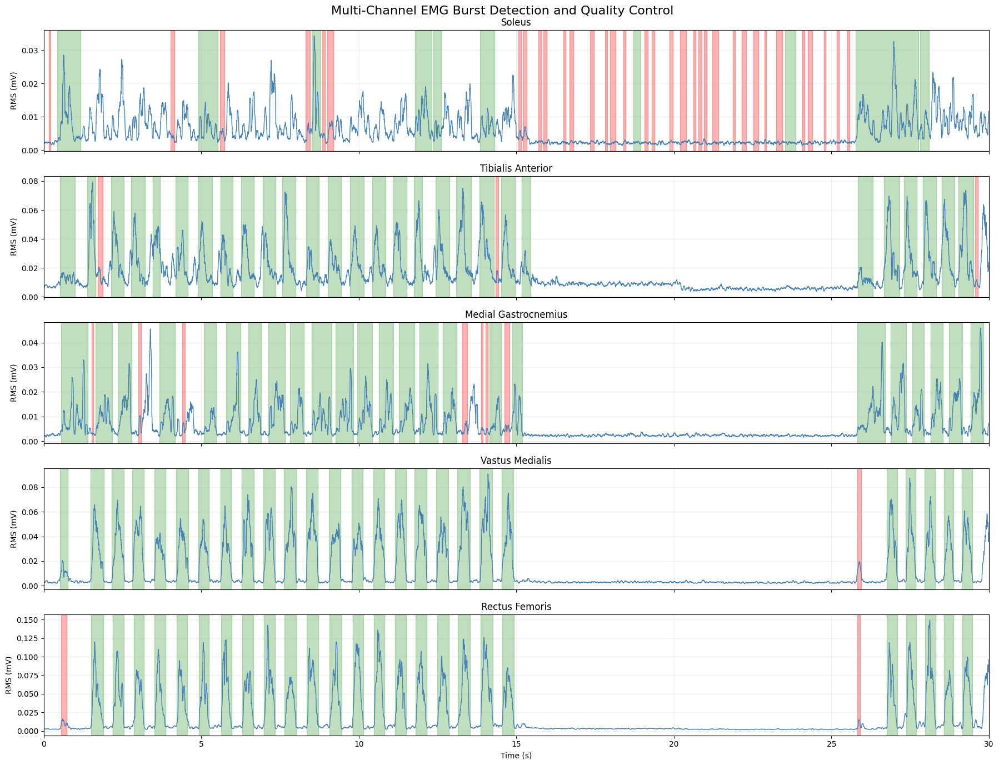

In [185]:
fig, axes = plt.subplots(
    5, 1,
    figsize=(18, 14),
    sharex=True
)

for ax, (muscle, results) in zip(
    axes,
    multichannel_results.items()
):

    ax.plot(
        results["time"],
        results["rms"],
        color="steelblue",
        linewidth=1,
        label="RMS envelope"
    )

    # Accepted bursts
    for onset, offset in results["accepted_bursts"]:

        ax.axvspan(
            onset,
            offset,
            color="green",
            alpha=0.25
        )

    # Rejected bursts
    for _, burst in results[
        "rejected_features"
    ].iterrows():

        ax.axvspan(
            burst["Onset_s"],
            burst["Offset_s"],
            color="red",
            alpha=0.3
        )

    ax.set_title(muscle)
    ax.set_ylabel("RMS (mV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 30)

fig.suptitle(
    "Multi-Channel EMG Burst Detection and Quality Control",
    fontsize=16
)

plt.tight_layout()
plt.show()

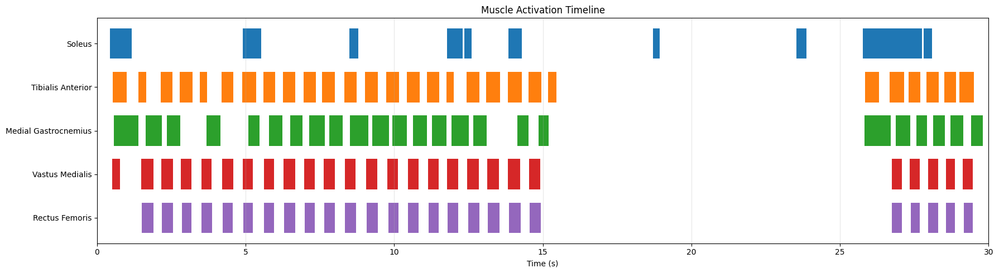

In [186]:
fig, ax = plt.subplots(figsize=(18, 5))

for i, (muscle, results) in enumerate(
    multichannel_results.items()
):

    intervals = [
        (onset, offset - onset)
        for onset, offset in results["accepted_bursts"]
    ]

    ax.broken_barh(
        intervals,
        (i - 0.35, 0.7),
        facecolors=f"C{i}"
    )

ax.set_yticks(
    range(len(multichannel_results))
)

ax.set_yticklabels(
    list(multichannel_results.keys())
)

ax.set_xlim(0, 30)
ax.set_xlabel("Time (s)")
ax.set_title("Muscle Activation Timeline")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [187]:
all_muscle_features = []

for muscle, results in multichannel_results.items():

    features = results["accepted_features"].copy()

    features.insert(0, "Muscle", muscle)

    all_muscle_features.append(features)

multichannel_features_df = pd.concat(
    all_muscle_features,
    ignore_index=True
)

print(
    "Combined dataset shape:",
    multichannel_features_df.shape
)

display(multichannel_features_df.head(10))

Combined dataset shape: (113, 14)


,Muscle,Burst_ID,Onset_s,Offset_s,Duration_ms,Peak_RMS_mV,Mean_RMS_mV,Burst_RMS_mV,iEMG_mV_s,Envelope_Area_mV_s,Time_to_Peak_ms,Inter_Burst_Interval_ms,Onset_Interval_ms,Original_Burst_ID
0,Soleus,1,0.430603,1.168448,737.844844,0.028502,0.008873,0.011081,0.005013,0.006546,194.829642,NaN,NaN,2
1,Soleus,2,4.906552,5.522431,615.879324,0.014358,0.006805,0.007413,0.003240,0.004190,221.364066,3738.103532,4475.948376,4
2,Soleus,3,8.497552,8.783380,285.827593,0.034325,0.014150,0.016978,0.002906,0.004042,83.105285,2975.120756,3591.000080,7
3,Soleus,4,11.781311,12.306414,525.103460,0.019085,0.010035,0.010812,0.004088,0.005267,342.863891,2997.931102,3283.758694,10
4,Soleus,5,12.366000,12.608069,242.068971,0.008861,0.005590,0.005939,0.001037,0.001351,77.519023,59.586208,584.689668,11
5,Soleus,6,13.847276,14.299293,452.017252,0.012589,0.007403,0.007780,0.002661,0.003345,229.743128,1239.206924,1481.275895,12
6,Soleus,7,18.705880,18.941897,236.017247,0.002701,0.002302,0.002338,0.000450,0.000542,169.691270,4406.586306,4858.603557,23
7,Soleus,8,23.531897,23.864276,332.379318,0.002583,0.002192,0.002202,0.000591,0.000727,132.915321,4590.000103,4826.017350,37
8,Soleus,9,25.763587,27.753208,1989.620734,0.032629,0.009619,0.011153,0.015082,0.019136,1213.380816,1899.310387,2231.689705,43
9,Soleus,10,27.813259,28.101414,288.155179,0.012053,0.007378,0.007791,0.001708,0.002124,172.949756,60.051725,2049.672460,44


In [188]:
multichannel_features_df.to_csv(
    "EMG_Multichannel_Features.csv",
    index=False
)

muscle_summary_df.to_csv(
    "EMG_Multichannel_Summary.csv",
    index=False
)

all_rejected = []

for muscle, results in multichannel_results.items():

    rejected = results["rejected_features"].copy()

    rejected.insert(0, "Muscle", muscle)

    all_rejected.append(rejected)

multichannel_rejected_df = pd.concat(
    all_rejected,
    ignore_index=True
)

multichannel_rejected_df.to_csv(
    "EMG_Multichannel_Rejected_Bursts.csv",
    index=False
)

print("All results exported successfully.")

All results exported successfully.


In [189]:
baseline_start = 17
baseline_end = 23

baseline_results = []

for muscle, results in multichannel_results.items():

    t = results["time"]
    rms = results["rms"]

    baseline_mask = (
        (t >= baseline_start) &
        (t < baseline_end)
    )

    baseline_rms = rms[baseline_mask]

    active_mask = (
        ((t >= 1) & (t < 14.5)) |
        ((t >= 27) & (t < 29.5))
    )

    active_rms = rms[active_mask]

    baseline_mean = np.mean(baseline_rms)
    baseline_sd = np.std(baseline_rms)

    baseline_results.append({
        "Muscle": muscle,
        "Baseline_Mean_mV": baseline_mean,
        "Baseline_SD_mV": baseline_sd,
        "Baseline_Median_mV":
            np.median(baseline_rms),
        "Baseline_95th_Percentile_mV":
            np.percentile(baseline_rms, 95),
        "Active_Mean_RMS_mV":
            np.mean(active_rms),
        "Active_95th_Percentile_mV":
            np.percentile(active_rms, 95),
        "Active_to_Baseline_Ratio":
            np.mean(active_rms) / baseline_mean
            if baseline_mean > 0 else np.nan
    })

baseline_summary_df = pd.DataFrame(
    baseline_results
)

display(baseline_summary_df.round(6))

,Muscle,Baseline_Mean_mV,Baseline_SD_mV,Baseline_Median_mV,Baseline_95th_Percentile_mV,Active_Mean_RMS_mV,Active_95th_Percentile_mV,Active_to_Baseline_Ratio
0,Soleus,0.002197,0.000331,0.002209,0.002727,0.008017,0.017220,3.649175
1,Tibialis Anterior,0.007391,0.001899,0.007787,0.010033,0.022637,0.053469,3.062823
2,Medial Gastrocnemius,0.002421,0.000378,0.002400,0.003139,0.008956,0.022096,3.699551
3,Vastus Medialis,0.002795,0.000470,0.002744,0.003659,0.021076,0.059233,7.540790
4,Rectus Femoris,0.002612,0.000555,0.002619,0.003480,0.031595,0.100620,12.095293


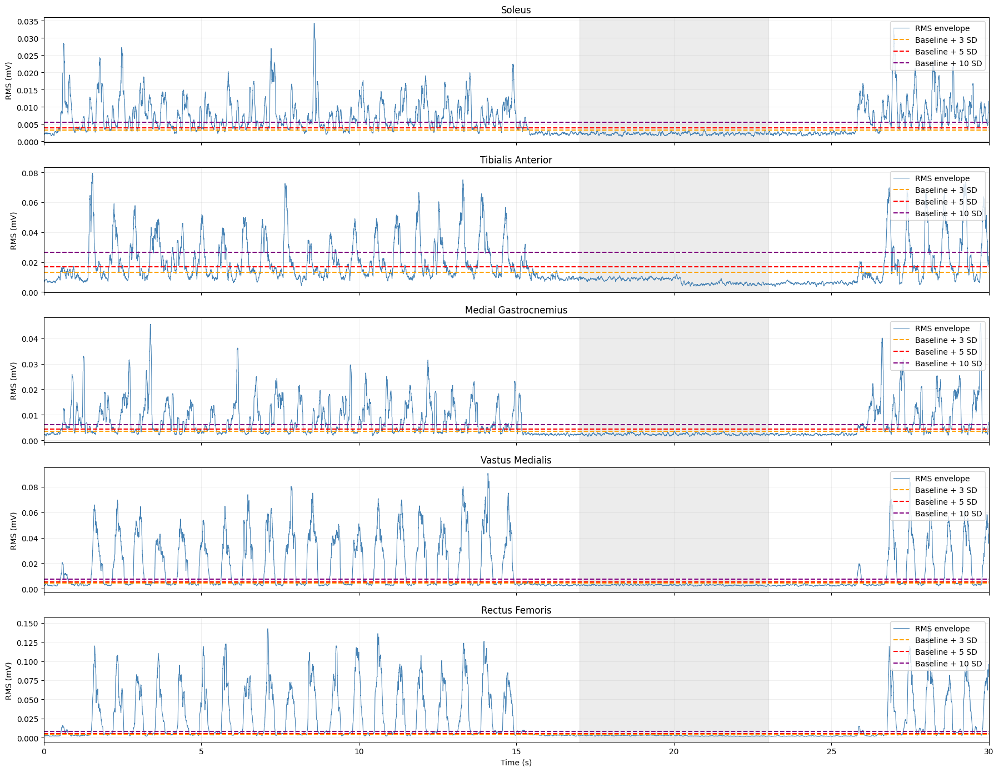

In [190]:
fig, axes = plt.subplots(
    5, 1,
    figsize=(18, 14),
    sharex=True
)

for ax, (muscle, results) in zip(
    axes,
    multichannel_results.items()
):

    t = results["time"]
    rms = results["rms"]

    baseline_mask = (
        (t >= baseline_start) &
        (t < baseline_end)
    )

    baseline = rms[baseline_mask]

    mu = np.mean(baseline)
    sd = np.std(baseline)

    ax.plot(
        t, rms,
        color="steelblue",
        linewidth=0.8,
        label="RMS envelope"
    )

    for k, color in zip(
        [3, 5, 10],
        ["orange", "red", "purple"]
    ):

        threshold = mu + k * sd

        ax.axhline(
            threshold,
            color=color,
            linestyle="--",
            label=f"Baseline + {k} SD"
        )

    ax.axvspan(
        baseline_start,
        baseline_end,
        color="gray",
        alpha=0.15
    )

    ax.set_title(muscle)
    ax.set_ylabel("RMS (mV)")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 30)

plt.tight_layout()
plt.show()

In [195]:
soleus = multichannel_results["Soleus"]

t = soleus["time"]
rms = soleus["rms"]

fs_current = emg_config["sampling_rate"]

baseline_mask = (
    (t >= baseline_start) &
    (t < baseline_end)
)

baseline_mean = np.mean(rms[baseline_mask])
baseline_sd = np.std(rms[baseline_mask])

soleus_threshold_results = []
soleus_candidate_bursts = {}

for k in [3, 5, 10, 15, 20]:

    threshold = baseline_mean + k * baseline_sd

    # Unpack the two arrays
    start_indices, end_indices = detect_bursts(
        envelope=rms,
        threshold=threshold,
        fs=fs_current,
        min_duration_ms=200
    )

    # Convert sample indices to onset/offset pairs
    bursts = [
        (start / fs_current, end / fs_current)
        for start, end in zip(
            start_indices, end_indices
        )
        if start > 0 and end < len(rms)
    ]

    soleus_candidate_bursts[k] = bursts

    soleus_threshold_results.append({
        "k": k,
        "Threshold_mV": threshold,
        "Raw_Burst_Count": len(start_indices),
        "Burst_Count": len(bursts),
        "Boundary_Bursts_Removed":
            len(start_indices) - len(bursts)
    })

soleus_threshold_df = pd.DataFrame(
    soleus_threshold_results
)

display(soleus_threshold_df.round(6))

,k,Threshold_mV,Raw_Burst_Count,Burst_Count,Boundary_Bursts_Removed
0,3,0.003191,24,23,1
1,5,0.003854,29,28,1
2,10,0.005511,22,22,0
3,15,0.007168,15,15,0
4,20,0.008825,4,4,0


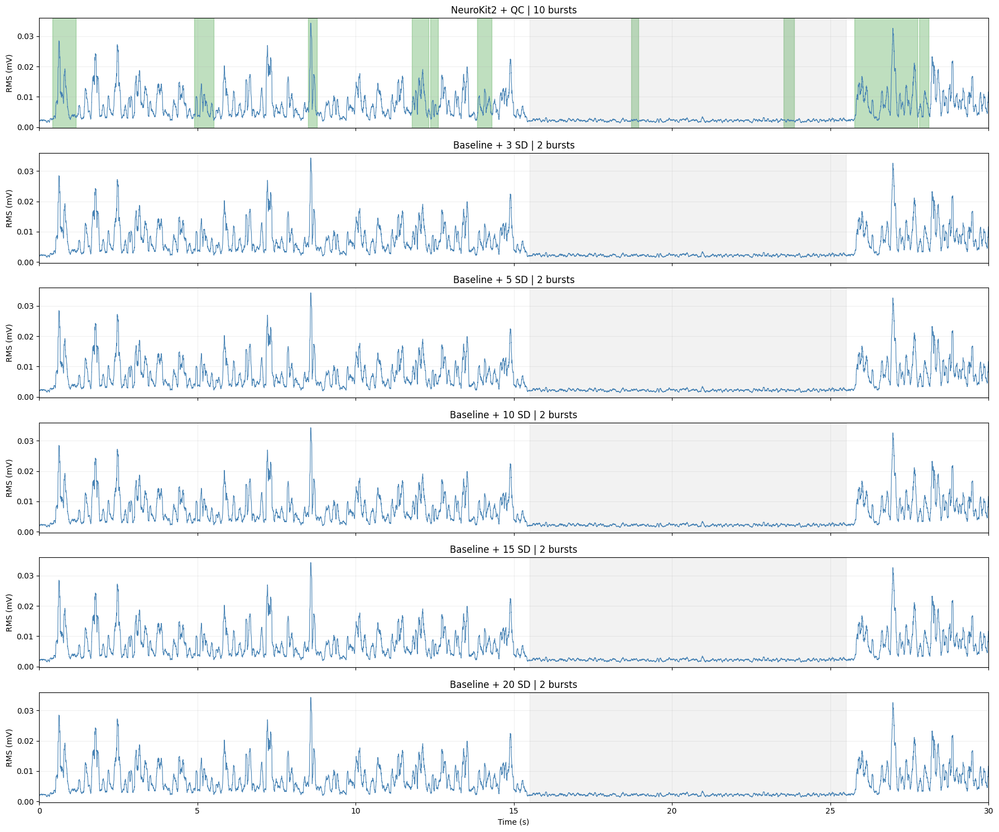

In [193]:
fig, axes = plt.subplots(
    6, 1,
    figsize=(18, 15),
    sharex=True
)

methods = {
    "NeuroKit2 + QC":
        soleus["accepted_bursts"]
}

for k, bursts in soleus_candidate_bursts.items():
    methods[f"Baseline + {k} SD"] = bursts

for ax, (method, bursts) in zip(
    axes,
    methods.items()
):

    ax.plot(
        t, rms,
        color="steelblue",
        linewidth=0.8
    )

    # Extract onset and offset from each burst
    for burst in bursts:

        onset = burst[0]
        offset = burst[1]

        ax.axvspan(
            onset,
            offset,
            color="green",
            alpha=0.25
        )

    # Highlight apparent resting period
    ax.axvspan(
        15.5, 25.5,
        color="gray",
        alpha=0.1
    )

    ax.set_title(
        f"{method} | {len(bursts)} bursts"
    )

    ax.set_ylabel("RMS (mV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 30)

plt.tight_layout()
plt.show()

In [196]:
for k, bursts in soleus_candidate_bursts.items():
    print(f"k = {k}")
    print("First three bursts:", bursts[:3])
    print()

k = 3
First three bursts: [(np.float64(0.5181207012682226), np.float64(0.953844848965488)), (np.float64(1.409586238490726), np.float64(1.6227931398212256)), (np.float64(1.640948312641945), np.float64(2.0883103916345434))]

k = 5
First three bursts: [(np.float64(0.518586218520036), np.float64(0.9487241591955415)), (np.float64(1.642344864397385), np.float64(1.9188621119744957)), (np.float64(2.3387586731101084), np.float64(2.604569023895513))]

k = 10
First three bursts: [(np.float64(0.5251034600454224), np.float64(0.9175345033240493)), (np.float64(1.655379347448158), np.float64(1.9067586634273495)), (np.float64(2.3490000526500014), np.float64(2.58734488557842))]

k = 15
First three bursts: [(np.float64(0.5292931153117423), np.float64(0.8975172614960766)), (np.float64(1.6581724509590379), np.float64(1.9021034909092163)), (np.float64(2.3666897082189076), np.float64(2.5794310922975936))]

k = 20
First three bursts: [(np.float64(1.662827623477171), np.float64(1.8955862493838298)), (np.float6

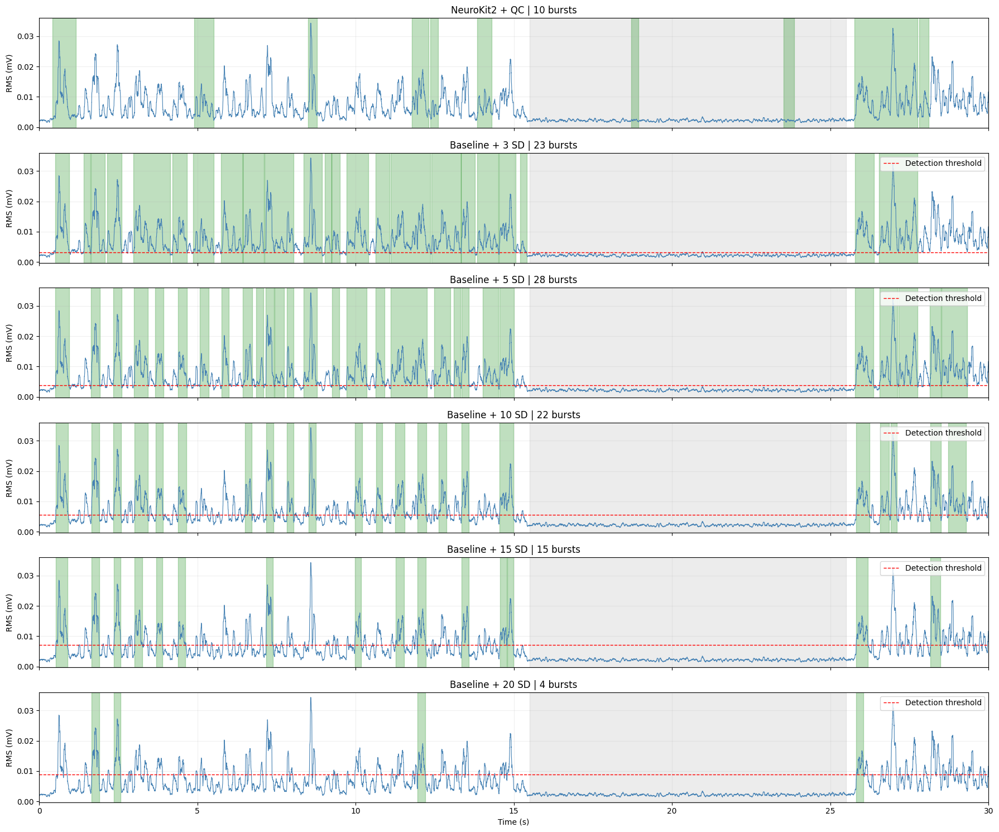

In [197]:
fig, axes = plt.subplots(
    6, 1,
    figsize=(18, 15),
    sharex=True
)

methods = {
    "NeuroKit2 + QC":
        soleus["accepted_bursts"]
}

for k, bursts in soleus_candidate_bursts.items():
    methods[f"Baseline + {k} SD"] = bursts

for ax, (method, bursts) in zip(
    axes,
    methods.items()
):

    ax.plot(
        t, rms,
        color="steelblue",
        linewidth=0.8
    )

    # Highlight apparent resting period
    ax.axvspan(
        15.5, 25.5,
        color="gray",
        alpha=0.15
    )

    # Highlight detected bursts
    for onset, offset in bursts:

        ax.axvspan(
            onset,
            offset,
            color="green",
            alpha=0.25
        )

    # Display detection threshold
    if method != "NeuroKit2 + QC":

        k = int(method.split()[2])
        threshold = baseline_mean + k * baseline_sd

        ax.axhline(
            threshold,
            color="red",
            linestyle="--",
            linewidth=1,
            label="Detection threshold"
        )

        ax.legend(loc="upper right")

    ax.set_title(
        f"{method} | {len(bursts)} bursts"
    )

    ax.set_ylabel("RMS (mV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 30)

plt.tight_layout()
plt.show()

In [198]:
soleus_method_comparison = []

rest_start = 15.5
rest_end = 25.5

for method, bursts in methods.items():

    durations = np.array([
        (offset - onset) * 1000
        for onset, offset in bursts
    ])

    # Bursts overlapping apparent resting period
    rest_bursts = sum(
        onset < rest_end and offset > rest_start
        for onset, offset in bursts
    )

    # Potential merged bursts
    long_bursts = np.sum(durations > 800)

    soleus_method_comparison.append({
        "Method": method,
        "Total_Bursts": len(bursts),
        "Rest_Bursts": rest_bursts,
        "Mean_Duration_ms":
            np.mean(durations) if len(durations) else np.nan,
        "SD_Duration_ms":
            np.std(durations, ddof=1)
            if len(durations) > 1 else np.nan,
        "Max_Duration_ms":
            np.max(durations) if len(durations) else np.nan,
        "Bursts_Over_800ms": long_bursts,
        "Total_Active_Time_s":
            np.sum(durations) / 1000
    })

soleus_method_comparison_df = pd.DataFrame(
    soleus_method_comparison
)

display(soleus_method_comparison_df.round(4))

,Method,Total_Bursts,Rest_Bursts,Mean_Duration_ms,SD_Duration_ms,Max_Duration_ms,Bursts_Over_800ms,Total_Active_Time_s
0,NeuroKit2 + QC,10,2,570.4914,526.7585,1989.6207,1,5.7049
1,Baseline + 3 SD,23,0,615.1102,307.2523,1253.1724,5,14.1475
2,Baseline + 5 SD,28,0,403.9360,212.9740,1139.5862,2,11.3102
3,Baseline + 10 SD,22,0,291.4561,96.5552,560.0173,0,6.4120
4,Baseline + 15 SD,15,0,250.9759,57.7675,374.7414,0,3.7646
5,Baseline + 20 SD,4,0,223.2155,13.5800,234.1552,0,0.8929


In [199]:
def detect_bursts_baseline(
    envelope,
    time,
    fs,
    baseline_start=17,
    baseline_end=23,
    k=10,
    min_duration_ms=200
):

    envelope = np.asarray(envelope)
    time = np.asarray(time)

    if len(envelope) != len(time):
        raise ValueError(
            "Envelope and time lengths differ."
        )

    # Identify baseline period
    baseline_mask = (
        (time >= baseline_start) &
        (time < baseline_end)
    )

    baseline = envelope[baseline_mask]

    if len(baseline) < 2:
        raise ValueError(
            "Insufficient baseline samples."
        )

    # Calculate baseline-relative threshold
    baseline_mean = np.mean(baseline)
    baseline_sd = np.std(baseline)

    threshold = baseline_mean + k * baseline_sd

    # Detect bursts
    start_indices, end_indices = detect_bursts(
        envelope=envelope,
        threshold=threshold,
        fs=fs,
        min_duration_ms=min_duration_ms
    )

    # Convert indices into recorded timestamps
    # Exclude incomplete boundary bursts
    bursts = [
        (time[start], time[end])
        for start, end in zip(
            start_indices, end_indices
        )
        if 0 < start < end < len(time)
    ]

    return {
        "bursts": bursts,
        "threshold": threshold,
        "baseline_mean": baseline_mean,
        "baseline_sd": baseline_sd,
        "k": k
    }

In [200]:
baseline_detection_results = {}

for muscle, results in multichannel_results.items():

    baseline_detection_results[muscle] = {}

    for k in [5, 10]:

        detection = detect_bursts_baseline(
            envelope=results["rms"],
            time=results["time"],
            fs=emg_config["sampling_rate"],
            baseline_start=17,
            baseline_end=23,
            k=k,
            min_duration_ms=200
        )

        baseline_detection_results[muscle][k] = detection

        print(
            f"{muscle} | "
            f"k = {k} | "
            f"Threshold = {detection['threshold']:.6f} mV | "
            f"Bursts = {len(detection['bursts'])}"
        )

Soleus | k = 5 | Threshold = 0.003854 mV | Bursts = 28
Soleus | k = 10 | Threshold = 0.005511 mV | Bursts = 22
Tibialis Anterior | k = 5 | Threshold = 0.016888 mV | Bursts = 23
Tibialis Anterior | k = 10 | Threshold = 0.026385 mV | Bursts = 7
Medial Gastrocnemius | k = 5 | Threshold = 0.004312 mV | Bursts = 28
Medial Gastrocnemius | k = 10 | Threshold = 0.006203 mV | Bursts = 20
Vastus Medialis | k = 5 | Threshold = 0.005144 mV | Bursts = 26
Vastus Medialis | k = 10 | Threshold = 0.007493 mV | Bursts = 25
Rectus Femoris | k = 5 | Threshold = 0.005387 mV | Bursts = 27
Rectus Femoris | k = 10 | Threshold = 0.008161 mV | Bursts = 25


In [201]:
multichannel_method_comparison = []

for muscle, results in multichannel_results.items():

    muscle_methods = {
        "NeuroKit2 + QC":
            results["accepted_bursts"],

        "Baseline + 5 SD":
            baseline_detection_results[muscle][5]["bursts"],

        "Baseline + 10 SD":
            baseline_detection_results[muscle][10]["bursts"]
    }

    for method, bursts in muscle_methods.items():

        durations = np.array([
            (offset - onset) * 1000
            for onset, offset in bursts
        ])

        rest_bursts = sum(
            onset < 25.5 and offset > 15.5
            for onset, offset in bursts
        )

        multichannel_method_comparison.append({
            "Muscle": muscle,
            "Method": method,
            "Burst_Count": len(bursts),
            "Rest_Bursts": rest_bursts,

            "Mean_Duration_ms":
                np.mean(durations)
                if len(durations) else np.nan,

            "SD_Duration_ms":
                np.std(durations, ddof=1)
                if len(durations) > 1 else np.nan,

            "Max_Duration_ms":
                np.max(durations)
                if len(durations) else np.nan,

            "Bursts_Over_800ms":
                np.sum(durations > 800),

            "Total_Active_Time_s":
                np.sum(durations) / 1000
        })

multichannel_method_df = pd.DataFrame(
    multichannel_method_comparison
)

display(multichannel_method_df.round(4))

,Muscle,Method,Burst_Count,Rest_Bursts,Mean_Duration_ms,SD_Duration_ms,Max_Duration_ms,Bursts_Over_800ms,Total_Active_Time_s
0,Soleus,NeuroKit2 + QC,10,2,570.4914,526.7585,1989.6207,1,5.7049
1,Soleus,Baseline + 5 SD,28,0,403.9360,212.9740,1139.5862,2,11.3102
2,Soleus,Baseline + 10 SD,22,0,291.4561,96.5552,560.0172,0,6.4120
3,Tibialis Anterior,NeuroKit2 + QC,28,0,407.6601,68.0266,491.5862,0,11.4145
4,Tibialis Anterior,Baseline + 5 SD,23,0,284.9977,57.8631,456.6725,0,6.5549
5,Tibialis Anterior,Baseline + 10 SD,7,0,229.8325,14.3551,247.1897,0,1.6088
6,Medial Gastrocnemius,NeuroKit2 + QC,24,0,493.3125,133.8581,879.3621,2,11.8395
7,Medial Gastrocnemius,Baseline + 5 SD,28,0,342.5376,82.8774,560.4828,0,9.5911
8,Medial Gastrocnemius,Baseline + 10 SD,20,0,299.9793,71.8456,514.8620,0,5.9996
9,Vastus Medialis,NeuroKit2 + QC,26,0,359.4330,35.2871,415.7069,0,9.3453


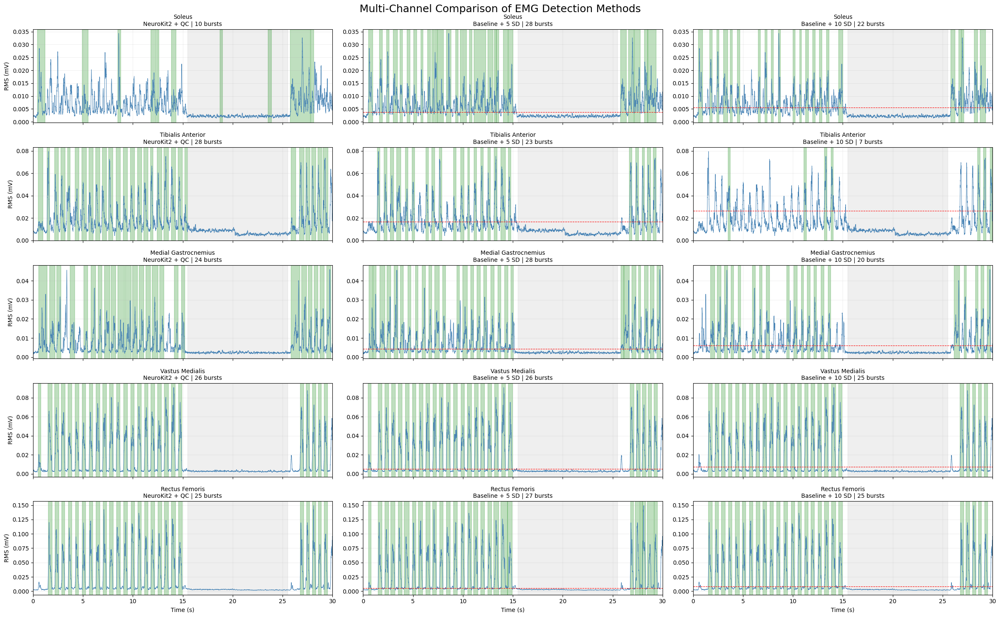

In [202]:
fig, axes = plt.subplots(
    5, 3,
    figsize=(24, 15),
    sharex=True
)

for i, (muscle, results) in enumerate(
    multichannel_results.items()
):

    muscle_methods = {
        "NeuroKit2 + QC":
            results["accepted_bursts"],

        "Baseline + 5 SD":
            baseline_detection_results[muscle][5]["bursts"],

        "Baseline + 10 SD":
            baseline_detection_results[muscle][10]["bursts"]
    }

    for j, (method, bursts) in enumerate(
        muscle_methods.items()
    ):

        ax = axes[i, j]

        ax.plot(
            results["time"],
            results["rms"],
            color="steelblue",
            linewidth=0.7
        )

        # Highlight apparent resting period
        ax.axvspan(
            15.5, 25.5,
            color="gray",
            alpha=0.12
        )

        # Highlight detected bursts
        for onset, offset in bursts:

            ax.axvspan(
                onset,
                offset,
                color="green",
                alpha=0.25
            )

        # Display threshold for baseline methods
        if j > 0:

            k = 5 if j == 1 else 10

            threshold = (
                baseline_detection_results[muscle][k]
                ["threshold"]
            )

            ax.axhline(
                threshold,
                color="red",
                linestyle="--",
                linewidth=0.8
            )

        ax.set_title(
            f"{muscle}\n{method} | {len(bursts)} bursts",
            fontsize=10
        )

        ax.set_xlim(0, 30)
        ax.grid(alpha=0.2)

        if j == 0:
            ax.set_ylabel("RMS (mV)")

        if i == 4:
            ax.set_xlabel("Time (s)")

fig.suptitle(
    "Multi-Channel Comparison of EMG Detection Methods",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [203]:
multichannel_method_df.to_csv(
    "EMG_Multichannel_Method_Comparison.csv",
    index=False
)

soleus_method_comparison_df.to_csv(
    "EMG_Soleus_Method_Comparison.csv",
    index=False
)

print("Method comparison results exported.")

Method comparison results exported.


In [204]:
muscle_detection_config = {

    "Soleus": {
        "method": "baseline",
        "k": 10,
        "min_duration_ms": 200
    },

    "Tibialis Anterior": {
        "method": "neurokit",
        "min_duration_ms": 200
    },

    "Medial Gastrocnemius": {
        "method": "baseline",
        "k": 5,
        "min_duration_ms": 200
    },

    "Vastus Medialis": {
        "method": "neurokit",
        "min_duration_ms": 200
    },

    "Rectus Femoris": {
        "method": "neurokit",
        "min_duration_ms": 200
    }
}

display(
    pd.DataFrame(muscle_detection_config).T
)

,method,k,min_duration_ms
Soleus,baseline,10,200
Tibialis Anterior,neurokit,NaN,200
Medial Gastrocnemius,baseline,5,200
Vastus Medialis,neurokit,NaN,200
Rectus Femoris,neurokit,NaN,200


In [205]:
def select_muscle_bursts(
    muscle,
    multichannel_results,
    baseline_detection_results,
    muscle_detection_config
):

    config = muscle_detection_config[muscle]
    method = config["method"]

    if method == "neurokit":

        bursts = multichannel_results[muscle][
            "accepted_bursts"
        ]

        threshold = np.nan

    elif method == "baseline":

        k = config["k"]

        detection = baseline_detection_results[muscle][k]

        bursts = detection["bursts"]
        threshold = detection["threshold"]

    else:

        raise ValueError(
            f"Unknown detection method: {method}"
        )

    # Apply configured minimum duration
    bursts = [
        (onset, offset)
        for onset, offset in bursts
        if (offset - onset) * 1000
        >= config["min_duration_ms"] - 1e-6
    ]

    return {
        "muscle": muscle,
        "method": method,
        "k": config.get("k", np.nan),
        "threshold": threshold,
        "bursts": bursts
    }

In [206]:
selected_detection_results = {}

for muscle in muscle_detection_config:

    result = select_muscle_bursts(
        muscle=muscle,
        multichannel_results=multichannel_results,
        baseline_detection_results=baseline_detection_results,
        muscle_detection_config=muscle_detection_config
    )

    selected_detection_results[muscle] = result

    print(
        f"{muscle} | "
        f"Method: {result['method']} | "
        f"Bursts: {len(result['bursts'])}"
    )

Soleus | Method: baseline | Bursts: 22
Tibialis Anterior | Method: neurokit | Bursts: 28
Medial Gastrocnemius | Method: baseline | Bursts: 28
Vastus Medialis | Method: neurokit | Bursts: 26
Rectus Femoris | Method: neurokit | Bursts: 25


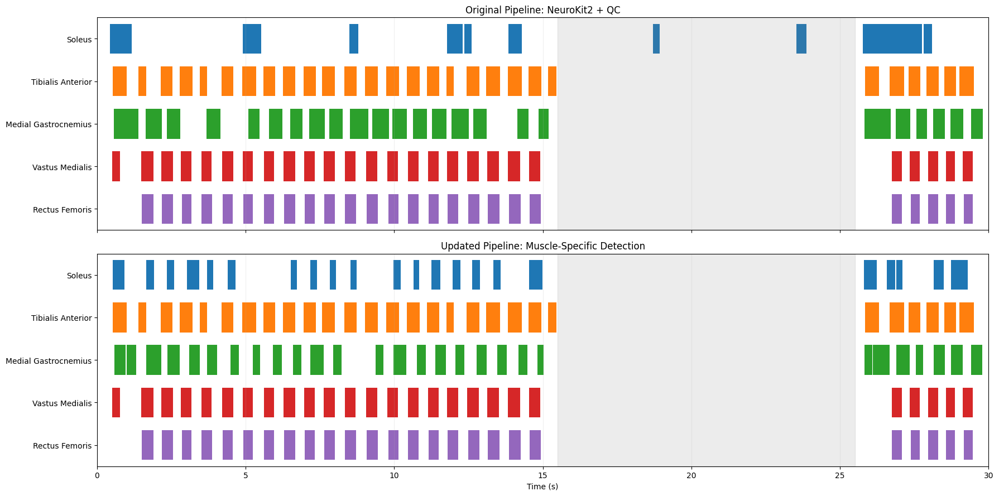

In [207]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(18, 9),
    sharex=True
)

muscles = list(muscle_detection_config.keys())

colors = plt.cm.tab10.colors

for i, muscle in enumerate(muscles):

    original_bursts = multichannel_results[muscle][
        "accepted_bursts"
    ]

    selected_bursts = selected_detection_results[muscle][
        "bursts"
    ]

    for ax, bursts in zip(
        axes,
        [original_bursts, selected_bursts]
    ):

        for onset, offset in bursts:

            ax.broken_barh(
                [(onset, offset - onset)],
                (i - 0.35, 0.7),
                facecolors=colors[i]
            )

for ax in axes:

    ax.set_yticks(range(len(muscles)))
    ax.set_yticklabels(muscles)

    ax.set_ylim(-0.5, len(muscles) - 0.5)
    ax.invert_yaxis()

    ax.axvspan(
        15.5, 25.5,
        color="gray",
        alpha=0.15
    )

    ax.set_xlim(0, 30)
    ax.grid(axis="x", alpha=0.2)

axes[0].set_title(
    "Original Pipeline: NeuroKit2 + QC"
)

axes[1].set_title(
    "Updated Pipeline: Muscle-Specific Detection"
)

axes[1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

In [208]:
selected_summary = []

for muscle, result in selected_detection_results.items():

    bursts = result["bursts"]

    durations = np.array([
        (offset - onset) * 1000
        for onset, offset in bursts
    ])

    original_count = len(
        multichannel_results[muscle]["accepted_bursts"]
    )

    selected_summary.append({

        "Muscle": muscle,

        "Detection_Method": result["method"],

        "k": result["k"],

        "Threshold_mV": result["threshold"],

        "Original_Burst_Count": original_count,

        "Selected_Burst_Count": len(bursts),

        "Change_in_Burst_Count":
            len(bursts) - original_count,

        "Mean_Duration_ms":
            np.mean(durations) if len(durations)
            else np.nan,

        "SD_Duration_ms":
            np.std(durations, ddof=1)
            if len(durations) > 1 else np.nan,

        "Total_Active_Time_s":
            np.sum(durations) / 1000,

        "Rest_Bursts": sum(
            onset < 25.5 and offset > 15.5
            for onset, offset in bursts
        )
    })

selected_summary_df = pd.DataFrame(
    selected_summary
)

display(selected_summary_df.round(4))

print(
    "Original total bursts:",
    selected_summary_df["Original_Burst_Count"].sum()
)

print(
    "Updated total bursts:",
    selected_summary_df["Selected_Burst_Count"].sum()
)

,Muscle,Detection_Method,k,Threshold_mV,Original_Burst_Count,Selected_Burst_Count,Change_in_Burst_Count,Mean_Duration_ms,SD_Duration_ms,Total_Active_Time_s,Rest_Bursts
0,Soleus,baseline,10.0,0.0055,10,22,12,291.4561,96.5552,6.4120,0
1,Tibialis Anterior,neurokit,NaN,NaN,28,28,0,407.6601,68.0266,11.4145,0
2,Medial Gastrocnemius,baseline,5.0,0.0043,24,28,4,342.5376,82.8774,9.5911,0
3,Vastus Medialis,neurokit,NaN,NaN,26,26,0,359.4330,35.2871,9.3453,0
4,Rectus Femoris,neurokit,NaN,NaN,25,25,0,349.9386,25.6262,8.7485,0


Original total bursts: 113
Updated total bursts: 129


In [209]:
def plot_muscle_annotation(
    muscle,
    start_time=0,
    end_time=10
):

    results = multichannel_results[muscle]

    t = np.asarray(results["time"])
    rms = np.asarray(results["rms"])

    mask = (
        (t >= start_time) &
        (t <= end_time)
    )

    fig, ax = plt.subplots(figsize=(20, 4))

    ax.plot(
        t[mask],
        rms[mask],
        color="steelblue",
        linewidth=1
    )

    ax.set_xticks(
        np.arange(start_time, end_time + 0.1, 0.1)
    )

    ax.tick_params(axis="x", rotation=90)

    ax.set_xlabel("Time (s)")
    ax.set_ylabel("RMS (mV)")
    ax.set_title(f"Manual Annotation: {muscle}")

    ax.grid(alpha=0.3)
    ax.set_xlim(start_time, end_time)

    plt.tight_layout()
    plt.show()

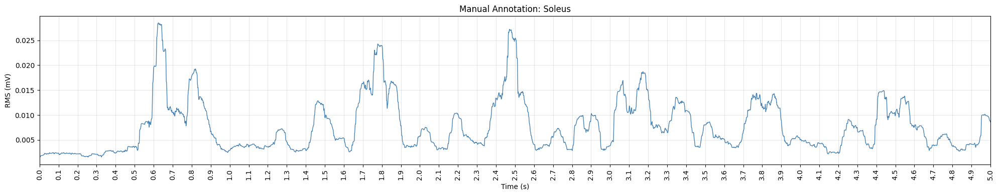

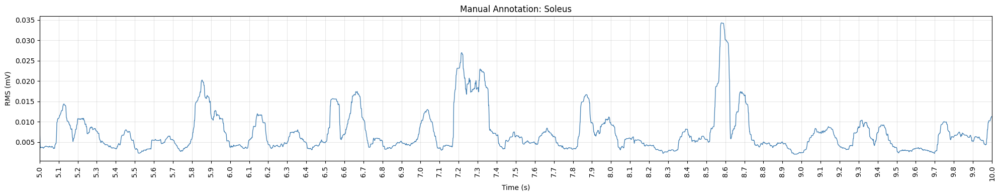

In [210]:
plot_muscle_annotation(
    muscle="Soleus",
    start_time=0,
    end_time=5
)

plot_muscle_annotation(
    muscle="Soleus",
    start_time=5,
    end_time=10
)

In [211]:
soleus_manual_bursts = [
    # (onset_s, offset_s),
    # Add your manual annotations here
]

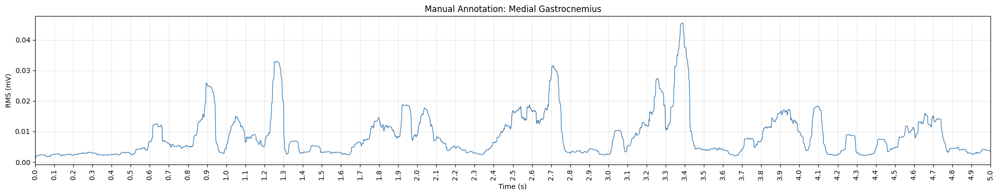

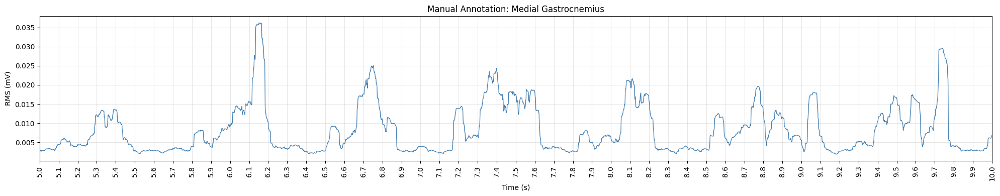

In [212]:
plot_muscle_annotation(
    muscle="Medial Gastrocnemius",
    start_time=0,
    end_time=5
)

plot_muscle_annotation(
    muscle="Medial Gastrocnemius",
    start_time=5,
    end_time=10
)

In [213]:
gastroc_manual_bursts = [
    # (onset_s, offset_s),
    # Add your manual annotations here
]

In [214]:
manual_annotations = {
    "Soleus": soleus_manual_bursts,
    "Medial Gastrocnemius": gastroc_manual_bursts
}

validation_start = 0
validation_end = 10

targeted_validation_results = []

for muscle, manual in manual_annotations.items():

    if len(manual) == 0:
        print(f"Skipping {muscle}: no annotations.")
        continue

    methods = {
        "NeuroKit2 + QC":
            multichannel_results[muscle]["accepted_bursts"],

        "Baseline + 5 SD":
            baseline_detection_results[muscle][5]["bursts"],

        "Baseline + 10 SD":
            baseline_detection_results[muscle][10]["bursts"]
    }

    # Keep complete manual bursts within the window
    manual_window = [
        (onset, offset)
        for onset, offset in manual
        if validation_start < onset < offset < validation_end
    ]

    for method, detected in methods.items():

        # Apply the same evaluation window
        detected_window = [
            (onset, offset)
            for onset, offset in detected
            if validation_start < onset < offset < validation_end
        ]

        metrics = evaluate_detection(
            manual_window,
            detected_window
        )

        targeted_validation_results.append({
            "Muscle": muscle,
            "Method": method,
            "Manual_Bursts": len(manual_window),
            "Detected_Bursts": len(detected_window),
            **metrics
        })

targeted_validation_df = pd.DataFrame(
    targeted_validation_results
)

display(targeted_validation_df.round(4))

Skipping Soleus: no annotations.
Skipping Medial Gastrocnemius: no annotations.


""


In [215]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neurokit2 as nk

from scipy.signal import butter, sosfiltfilt
from scipy.ndimage import uniform_filter1d
from scipy.integrate import trapezoid

muscle_columns = {
    "Soleus": ("Soleus_Time", "Soleus_EMG"),
    "Tibialis Anterior": ("TibAnt_Time", "TibAnt_EMG"),
    "Medial Gastrocnemius": ("GastrocMed_Time", "GastrocMed_EMG"),
    "Vastus Medialis": ("VastusMed_Time", "VastusMed_EMG"),
    "Rectus Femoris": ("RectusFem_Time", "RectusFem_EMG")
}

full_time = emg_data["RectusFem_Time"].to_numpy()

fs_full = 1 / np.median(np.diff(full_time))

full_config = {
    "sampling_rate": fs_full,
    "lowcut": 20,
    "highcut": 450,
    "filter_order": 4,
    "rms_window_ms": 50,
    "min_duration_ms": 200,
    "baseline_start": 17,
    "baseline_end": 23,
    "artifact_threshold_mV": 5.0,
    "artifact_padding_ms": 250
}

print("Sampling rate:", fs_full)
print("Recording duration:", full_time[-1] - full_time[0])
print("Number of samples:", len(full_time))

display(pd.DataFrame(muscle_detection_config).T)

Sampling rate: 2148.227712052401
Recording duration: 1037.1924311
Number of samples: 2228044


,method,k,min_duration_ms
Soleus,baseline,10,200
Tibialis Anterior,neurokit,NaN,200
Medial Gastrocnemius,baseline,5,200
Vastus Medialis,neurokit,NaN,200
Rectus Femoris,neurokit,NaN,200


In [216]:
artifact_summary = []
artifact_masks = {}

for muscle, (time_col, emg_col) in muscle_columns.items():

    raw = emg_data[emg_col].to_numpy()

    artifact_mask = (
        ~np.isfinite(raw) |
        (np.abs(raw) >= full_config["artifact_threshold_mV"])
    )

    artifact_masks[muscle] = artifact_mask

    artifact_summary.append({
        "Muscle": muscle,
        "Total_Samples": len(raw),
        "Flagged_Samples": artifact_mask.sum(),
        "Flagged_Percent": 100 * artifact_mask.mean(),
        "Flagged_Duration_s": artifact_mask.sum() / fs_full,
        "Max_Absolute_EMG_mV": np.nanmax(np.abs(raw))
    })

artifact_summary_df = pd.DataFrame(artifact_summary)

display(artifact_summary_df.round(4))

,Muscle,Total_Samples,Flagged_Samples,Flagged_Percent,Flagged_Duration_s,Max_Absolute_EMG_mV
0,Soleus,2228044,18,0.0008,0.0084,5.4937
1,Tibialis Anterior,2228044,165,0.0074,0.0768,5.4999
2,Medial Gastrocnemius,2228044,14,0.0006,0.0065,5.4942
3,Vastus Medialis,2228044,53,0.0024,0.0247,5.4670
4,Rectus Femoris,2228044,0,0.0000,0.0000,1.1006


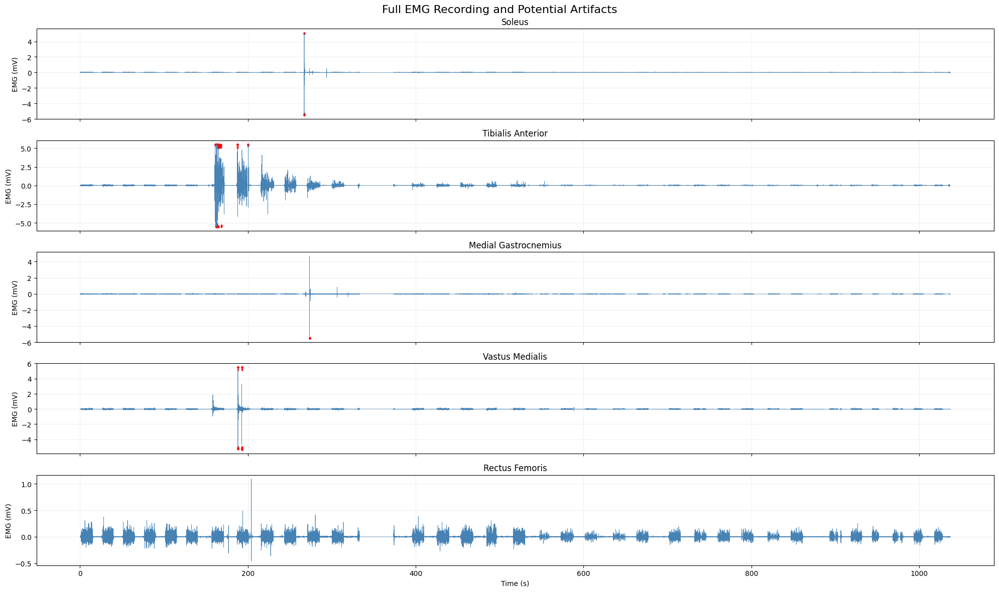

In [217]:
fig, axes = plt.subplots(
    5, 1,
    figsize=(20, 12),
    sharex=True
)

for ax, (muscle, columns) in zip(
    axes, muscle_columns.items()
):

    time_col, emg_col = columns

    t = emg_data[time_col].to_numpy()
    raw = emg_data[emg_col].to_numpy()

    artifact_mask = artifact_masks[muscle]

    ax.plot(
        t[::20],
        raw[::20],
        linewidth=0.5,
        color="steelblue"
    )

    ax.scatter(
        t[artifact_mask],
        raw[artifact_mask],
        color="red",
        s=3,
        label="Potential artifact"
    )

    ax.set_title(muscle)
    ax.set_ylabel("EMG (mV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (s)")

fig.suptitle(
    "Full EMG Recording and Potential Artifacts",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [218]:
from scipy.ndimage import maximum_filter1d

def handle_emg_artifacts(raw, fs, config):

    raw = np.asarray(raw, dtype=float)

    artifact_mask = (
        ~np.isfinite(raw) |
        (np.abs(raw) >= config["artifact_threshold_mV"])
    )

    cleaned = raw.copy()

    if artifact_mask.any():

        valid = ~artifact_mask

        if valid.sum() < 2:
            raise ValueError("Insufficient valid EMG samples.")

        indices = np.arange(len(raw))

        cleaned[artifact_mask] = np.interp(
            indices[artifact_mask],
            indices[valid],
            raw[valid]
        )

    # Expand mask around flagged samples
    padding_samples = int(
        config["artifact_padding_ms"] * fs / 1000
    )

    expanded_mask = maximum_filter1d(
        artifact_mask.astype(np.uint8),
        size=2 * padding_samples + 1,
        mode="constant"
    ).astype(bool)

    return cleaned, artifact_mask, expanded_mask

In [219]:
def process_full_emg_channel(
    raw,
    time,
    muscle,
    config,
    detection_config
):

    raw = np.asarray(raw, dtype=float)
    time = np.asarray(time, dtype=float)

    fs = config["sampling_rate"]

    if len(raw) != len(time):
        raise ValueError("EMG and time lengths differ.")

    if np.any(np.diff(time) <= 0):
        raise ValueError("Timestamps must be increasing.")

    # --------------------------------
    # 1. Artifact handling
    # --------------------------------

    cleaned, artifact_mask, expanded_mask = (
        handle_emg_artifacts(raw, fs, config)
    )

    # --------------------------------
    # 2. Bandpass filtering
    # --------------------------------

    sos = butter(
        config["filter_order"],
        [config["lowcut"], config["highcut"]],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    filtered = sosfiltfilt(sos, cleaned)

    # --------------------------------
    # 3. RMS envelope
    # --------------------------------

    window_samples = max(
        1,
        int(round(config["rms_window_ms"] * fs / 1000))
    )

    rms = np.sqrt(
        np.maximum(
            uniform_filter1d(
                filtered ** 2,
                size=window_samples
            ),
            0
        )
    )

    # --------------------------------
    # 4. Burst detection
    # --------------------------------

    method = detection_config["method"]
    min_duration = detection_config["min_duration_ms"]

    threshold = np.nan

    if method == "neurokit":

        nk_signals, nk_info = nk.emg_process(
            cleaned,
            sampling_rate=fs
        )

        activity = (
            nk_signals["EMG_Activity"].to_numpy() > 0
        )

        transitions = np.diff(
            np.concatenate(
                ([0], activity.astype(int), [0])
            )
        )

        starts = np.where(transitions == 1)[0]
        ends = np.where(transitions == -1)[0]

        del nk_signals, nk_info

    elif method == "baseline":

        baseline_mask = (
            (time >= config["baseline_start"]) &
            (time < config["baseline_end"]) &
            (~expanded_mask)
        )

        baseline = rms[baseline_mask]

        if len(baseline) < 2:
            raise ValueError("Insufficient clean baseline.")

        threshold = (
            np.mean(baseline) +
            detection_config["k"] * np.std(baseline)
        )

        starts, ends = detect_bursts(
            envelope=rms,
            threshold=threshold,
            fs=fs,
            min_duration_ms=min_duration
        )

    else:
        raise ValueError(f"Unknown method: {method}")

    # --------------------------------
    # 5. Burst quality control
    # --------------------------------

    accepted_bursts = []
    rejected_bursts = []

    for start, end in zip(starts, ends):

        duration_ms = (end - start) / fs * 1000

        reason = None

        if start <= 0 or end >= len(time):
            reason = "Boundary burst"

        elif end <= start:
            reason = "Invalid interval"

        elif duration_ms < min_duration:
            reason = "Insufficient duration"

        elif expanded_mask[start:end].any():
            reason = "Artifact overlap"

        if reason is not None:

            rejected_bursts.append({
                "Onset_s": time[min(start, len(time)-1)],
                "Offset_s": time[min(end, len(time)-1)],
                "Duration_ms": duration_ms,
                "Rejection_Reason": reason
            })

        else:

            accepted_bursts.append(
                (time[start], time[end])
            )

    # --------------------------------
    # 6. Feature extraction
    # --------------------------------

    features = extract_emg_features(
        signal=filtered,
        envelope=rms,
        time=time,
        bursts=accepted_bursts
    )

    features.insert(0, "Muscle", muscle)
    features["Detection_Method"] = method
    features["Threshold_mV"] = threshold
    features["Threshold_k"] = detection_config.get(
        "k", np.nan
    )

    rejected_df = pd.DataFrame(
        rejected_bursts,
        columns=[
            "Onset_s",
            "Offset_s",
            "Duration_ms",
            "Rejection_Reason"
        ]
    )

    rejected_df.insert(0, "Muscle", muscle)

    return {
        "muscle": muscle,
        "time": time,
        "filtered": filtered,
        "rms": rms,
        "artifact_mask": artifact_mask,
        "expanded_artifact_mask": expanded_mask,
        "method": method,
        "threshold": threshold,
        "detected_count": len(starts),
        "accepted_bursts": accepted_bursts,
        "rejected_bursts": rejected_df,
        "features": features
    }

In [220]:
import time as timer
import gc

full_recording_results = {}

for muscle, (time_col, emg_col) in muscle_columns.items():

    print(f"\nProcessing {muscle}...")

    start_timer = timer.perf_counter()

    result = process_full_emg_channel(
        raw=emg_data[emg_col].to_numpy(),
        time=emg_data[time_col].to_numpy(),
        muscle=muscle,
        config=full_config,
        detection_config=muscle_detection_config[muscle]
    )

    full_recording_results[muscle] = result

    elapsed = timer.perf_counter() - start_timer

    print("Method:", result["method"])
    print("Detected:", result["detected_count"])
    print("Accepted:", len(result["accepted_bursts"]))
    print("Rejected:", len(result["rejected_bursts"]))
    print(f"Processing time: {elapsed:.2f} seconds")

    gc.collect()

print("\nFull-recording processing complete.")


Processing Soleus...
Method: baseline
Detected: 210
Accepted: 209
Rejected: 1
Processing time: 0.41 seconds

Processing Tibialis Anterior...
Method: neurokit
Detected: 288
Accepted: 4
Rejected: 284
Processing time: 79.46 seconds

Processing Medial Gastrocnemius...
Method: baseline
Detected: 391
Accepted: 390
Rejected: 1
Processing time: 0.28 seconds

Processing Vastus Medialis...
Method: neurokit
Detected: 567
Accepted: 293
Rejected: 274
Processing time: 75.51 seconds

Processing Rectus Femoris...
Method: neurokit
Detected: 591
Accepted: 546
Rejected: 45
Processing time: 111.87 seconds

Full-recording processing complete.


In [221]:
full_features_df = pd.concat(
    [
        result["features"]
        for result in full_recording_results.values()
    ],
    ignore_index=True
)

full_rejected_df = pd.concat(
    [
        result["rejected_bursts"]
        for result in full_recording_results.values()
    ],
    ignore_index=True
)

print("Accepted feature dataset shape:",
      full_features_df.shape)

print("Rejected burst dataset shape:",
      full_rejected_df.shape)

display(full_features_df.head(10))

Accepted feature dataset shape: (1442, 16)
Rejected burst dataset shape: (605, 5)


,Muscle,Burst_ID,Onset_s,Offset_s,Duration_ms,Peak_RMS_mV,Mean_RMS_mV,Burst_RMS_mV,iEMG_mV_s,Envelope_Area_mV_s,Time_to_Peak_ms,Inter_Burst_Interval_ms,Onset_Interval_ms,Detection_Method,Threshold_mV,Threshold_k
0,Soleus,1,0.525347,0.917778,392.4310,0.028502,0.013524,0.014814,0.004036,0.005311,100.0862,NaN,NaN,baseline,0.005511,10.0
1,Soleus,2,1.655623,1.907002,251.3793,0.024279,0.015964,0.016612,0.003117,0.004018,122.4310,737.8449,1130.2759,baseline,0.005511,10.0
2,Soleus,3,2.349243,2.587588,238.3449,0.027226,0.015223,0.016469,0.002881,0.003633,121.9656,442.2413,693.6206,baseline,0.005511,10.0
3,Soleus,4,3.018192,3.441347,423.1552,0.018718,0.011434,0.011934,0.003862,0.004841,154.5517,430.6034,668.9483,baseline,0.005511,10.0
4,Soleus,5,3.694123,3.916174,222.0517,0.014356,0.011461,0.011743,0.002042,0.002548,74.4827,252.7759,675.9311,baseline,0.005511,10.0
5,Soleus,6,4.392399,4.659140,266.7414,0.014901,0.010565,0.010931,0.002177,0.002820,45.1552,476.2241,698.2758,baseline,0.005511,10.0
6,Soleus,7,6.508640,6.719985,211.3448,0.017431,0.012075,0.012650,0.001886,0.002555,159.2069,1849.5000,2116.2414,baseline,0.005511,10.0
7,Soleus,8,7.169675,7.408019,238.3448,0.026980,0.017381,0.018391,0.002976,0.004148,46.0862,449.6897,661.0345,baseline,0.005511,10.0
8,Soleus,9,7.826054,8.035537,209.4828,0.016657,0.010281,0.010805,0.001662,0.002156,44.6896,418.0345,656.3793,baseline,0.005511,10.0
9,Soleus,10,8.518278,8.738468,220.1897,0.034325,0.016909,0.019135,0.002658,0.003729,62.3793,482.7413,692.2241,baseline,0.005511,10.0


In [222]:
full_summary = []

for muscle, result in full_recording_results.items():

    features = result["features"]

    detected = result["detected_count"]
    accepted = len(result["accepted_bursts"])
    rejected = len(result["rejected_bursts"])

    durations = features.get(
        "Duration_ms",
        pd.Series(dtype=float)
    )

    total_duration = (
        result["time"][-1] - result["time"][0]
    )

    active_time = durations.sum() / 1000

    full_summary.append({
        "Muscle": muscle,
        "Method": result["method"],
        "Detected_Bursts": detected,
        "Accepted_Bursts": accepted,
        "Rejected_Bursts": rejected,
        "Retention_Percent":
            100 * accepted / detected if detected else np.nan,
        "Mean_Duration_ms": durations.mean(),
        "SD_Duration_ms": durations.std(),
        "Total_Active_Time_s": active_time,
        "Percent_Active":
            100 * active_time / total_duration,
        "Artifact_Percent":
            100 * result["artifact_mask"].mean(),
        "Excluded_Region_Percent":
            100 * result["expanded_artifact_mask"].mean()
    })

full_summary_df = pd.DataFrame(full_summary)

display(full_summary_df.round(4))

,Muscle,Method,Detected_Bursts,Accepted_Bursts,Rejected_Bursts,Retention_Percent,Mean_Duration_ms,SD_Duration_ms,Total_Active_Time_s,Percent_Active,Artifact_Percent,Excluded_Region_Percent
0,Soleus,baseline,210,209,1,99.5238,269.4008,88.7969,56.3048,5.4286,0.0008,0.0501
1,Tibialis Anterior,neurokit,288,4,284,1.3889,234.9698,23.1713,0.9399,0.0906,0.0074,0.5865
2,Medial Gastrocnemius,baseline,391,390,1,99.7442,325.5816,99.6122,126.9768,12.2424,0.0006,0.0488
3,Vastus Medialis,neurokit,567,293,274,51.6755,242.4916,33.8685,71.0500,6.8502,0.0024,0.1011
4,Rectus Femoris,neurokit,591,546,45,92.3858,396.4860,95.2405,216.4813,20.8719,0.0000,0.0000


In [223]:
if not full_rejected_df.empty:

    rejection_summary_df = pd.crosstab(
        full_rejected_df["Muscle"],
        full_rejected_df["Rejection_Reason"]
    )

    display(rejection_summary_df)

else:

    print("No rejected bursts.")

Rejection_Reason,Artifact overlap,Insufficient duration
Muscle,,
Medial Gastrocnemius,1,0
Rectus Femoris,0,45
Soleus,1,0
Tibialis Anterior,0,284
Vastus Medialis,0,274


In [224]:
if not full_rejected_df.empty:

    rejection_summary_df = pd.crosstab(
        full_rejected_df["Muscle"],
        full_rejected_df["Rejection_Reason"]
    )

    display(rejection_summary_df)

else:

    print("No rejected bursts.")

Rejection_Reason,Artifact overlap,Insufficient duration
Muscle,,
Medial Gastrocnemius,1,0
Rectus Femoris,0,45
Soleus,1,0
Tibialis Anterior,0,284
Vastus Medialis,0,274


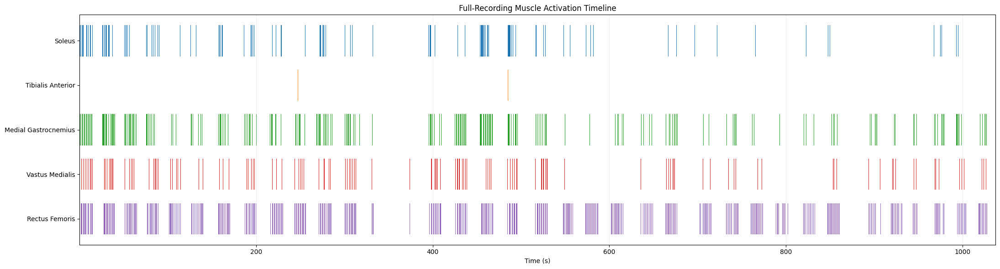

In [225]:
fig, ax = plt.subplots(figsize=(22, 6))

colors = plt.cm.tab10.colors

for i, (muscle, result) in enumerate(
    full_recording_results.items()
):

    intervals = [
        (onset, offset - onset)
        for onset, offset in result["accepted_bursts"]
    ]

    ax.broken_barh(
        intervals,
        (i - 0.35, 0.7),
        facecolors=colors[i]
    )

ax.set_yticks(range(len(full_recording_results)))

ax.set_yticklabels(
    list(full_recording_results.keys())
)

ax.invert_yaxis()

ax.set_xlabel("Time (s)")
ax.set_title("Full-Recording Muscle Activation Timeline")

ax.set_xlim(full_time[0], full_time[-1])

ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

In [226]:
import os
import json

output_dir = "EMG_Pipeline_Results"

os.makedirs(output_dir, exist_ok=True)

full_features_df.to_csv(
    f"{output_dir}/Full_EMG_Burst_Features.csv",
    index=False
)

full_summary_df.to_csv(
    f"{output_dir}/Full_EMG_Muscle_Summary.csv",
    index=False
)

full_rejected_df.to_csv(
    f"{output_dir}/Full_EMG_Rejected_Bursts.csv",
    index=False
)

artifact_summary_df.to_csv(
    f"{output_dir}/EMG_Artifact_Summary.csv",
    index=False
)

with open(
    f"{output_dir}/EMG_Processing_Config.json", "w"
) as f:

    json.dump(
        {
            "processing": full_config,
            "muscle_detection": muscle_detection_config
        },
        f,
        indent=4
    )

print("Exported files:")

for filename in os.listdir(output_dir):
    print(filename)

Exported files:
Full_EMG_Rejected_Bursts.csv
Full_EMG_Burst_Features.csv
EMG_Processing_Config.json
EMG_Artifact_Summary.csv
Full_EMG_Muscle_Summary.csv


In [227]:
print(full_summary_df.round(4).to_string(index=False))

print("\nCombined feature dataset:", full_features_df.shape)

print("\nRejected bursts:", len(full_rejected_df))

              Muscle   Method  Detected_Bursts  Accepted_Bursts  Rejected_Bursts  Retention_Percent  Mean_Duration_ms  SD_Duration_ms  Total_Active_Time_s  Percent_Active  Artifact_Percent  Excluded_Region_Percent
              Soleus baseline              210              209                1            99.5238          269.4008         88.7969              56.3048          5.4286            0.0008                   0.0501
   Tibialis Anterior neurokit              288                4              284             1.3889          234.9698         23.1713               0.9399          0.0906            0.0074                   0.5865
Medial Gastrocnemius baseline              391              390                1            99.7442          325.5816         99.6122             126.9768         12.2424            0.0006                   0.0488
     Vastus Medialis neurokit              567              293              274            51.6755          242.4916         33.8685           

In [228]:
rejection_summary_df = pd.crosstab(
    full_rejected_df["Muscle"],
    full_rejected_df["Rejection_Reason"]
)

display(rejection_summary_df)

Rejection_Reason,Artifact overlap,Insufficient duration
Muscle,,
Medial Gastrocnemius,1,0
Rectus Femoris,0,45
Soleus,1,0
Tibialis Anterior,0,284
Vastus Medialis,0,274


In [229]:
rejected_duration_summary = (
    full_rejected_df
    .groupby("Muscle")["Duration_ms"]
    .describe()
)

display(rejected_duration_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
Muscle,,,,,,,,
Medial Gastrocnemius,1.0,1808.93,NaN,1808.93,1808.93,1808.93,1808.93,1808.93
Rectus Femoris,45.0,95.91,37.27,50.74,68.89,83.79,115.91,181.08
Soleus,1.0,1025.50,NaN,1025.50,1025.50,1025.50,1025.50,1025.50
Tibialis Anterior,284.0,108.34,32.16,50.27,83.56,106.13,136.51,195.04
Vastus Medialis,274.0,137.77,45.60,50.74,98.22,144.54,178.29,199.70


In [230]:
alternative_results = {}
alternative_summary = []

test_muscles = [
    "Tibialis Anterior",
    "Vastus Medialis"
]

for muscle in test_muscles:

    time_col, emg_col = muscle_columns[muscle]

    for k in [3, 5, 10]:

        print(f"Processing {muscle}: {k} SD")

        test_config = {
            "method": "baseline",
            "k": k,
            "min_duration_ms": 200
        }

        result = process_full_emg_channel(
            raw=emg_data[emg_col].to_numpy(),
            time=emg_data[time_col].to_numpy(),
            muscle=muscle,
            config=full_config,
            detection_config=test_config
        )

        features = result["features"]

        alternative_results[(muscle, k)] = {
            "features": features,
            "accepted_bursts": result["accepted_bursts"],
            "threshold": result["threshold"]
        }

        active_time = features.get(
            "Duration_ms",
            pd.Series(dtype=float)
        ).sum() / 1000

        alternative_summary.append({
            "Muscle": muscle,
            "Method": f"Baseline + {k} SD",
            "Accepted_Bursts": len(features),
            "Mean_Duration_ms": features.get(
                "Duration_ms",
                pd.Series(dtype=float)
            ).mean(),
            "Total_Active_Time_s": active_time,
            "Percent_Active": (
                100 * active_time /
                (full_time[-1] - full_time[0])
            )
        })

        del result
        gc.collect()

alternative_summary_df = pd.DataFrame(
    alternative_summary
)

display(alternative_summary_df.round(4))

Processing Tibialis Anterior: 3 SD
Processing Tibialis Anterior: 5 SD
Processing Tibialis Anterior: 10 SD
Processing Vastus Medialis: 3 SD
Processing Vastus Medialis: 5 SD
Processing Vastus Medialis: 10 SD


,Muscle,Method,Accepted_Bursts,Mean_Duration_ms,Total_Active_Time_s,Percent_Active
0,Tibialis Anterior,Baseline + 3 SD,452,385.7058,174.3390,16.8087
1,Tibialis Anterior,Baseline + 5 SD,350,334.6071,117.1125,11.2913
2,Tibialis Anterior,Baseline + 10 SD,128,306.5467,39.2380,3.7831
3,Vastus Medialis,Baseline + 3 SD,538,546.1815,293.8457,28.3309
4,Vastus Medialis,Baseline + 5 SD,532,502.5276,267.3447,25.7758
5,Vastus Medialis,Baseline + 10 SD,542,436.6414,236.6597,22.8173


In [231]:
original_comparison = full_summary_df.loc[
    full_summary_df["Muscle"].isin(test_muscles),
    [
        "Muscle",
        "Method",
        "Accepted_Bursts",
        "Mean_Duration_ms",
        "Total_Active_Time_s",
        "Percent_Active"
    ]
].copy()

original_comparison["Method"] = "NeuroKit2 + QC"

full_method_comparison_df = pd.concat(
    [
        original_comparison,
        alternative_summary_df
    ],
    ignore_index=True
).sort_values("Muscle")

display(full_method_comparison_df.round(4))

,Muscle,Method,Accepted_Bursts,Mean_Duration_ms,Total_Active_Time_s,Percent_Active
0,Tibialis Anterior,NeuroKit2 + QC,4,234.9698,0.9399,0.0906
2,Tibialis Anterior,Baseline + 3 SD,452,385.7058,174.3390,16.8087
3,Tibialis Anterior,Baseline + 5 SD,350,334.6071,117.1125,11.2913
4,Tibialis Anterior,Baseline + 10 SD,128,306.5467,39.2380,3.7831
1,Vastus Medialis,NeuroKit2 + QC,293,242.4916,71.0500,6.8502
5,Vastus Medialis,Baseline + 3 SD,538,546.1815,293.8457,28.3309
6,Vastus Medialis,Baseline + 5 SD,532,502.5276,267.3447,25.7758
7,Vastus Medialis,Baseline + 10 SD,542,436.6414,236.6597,22.8173


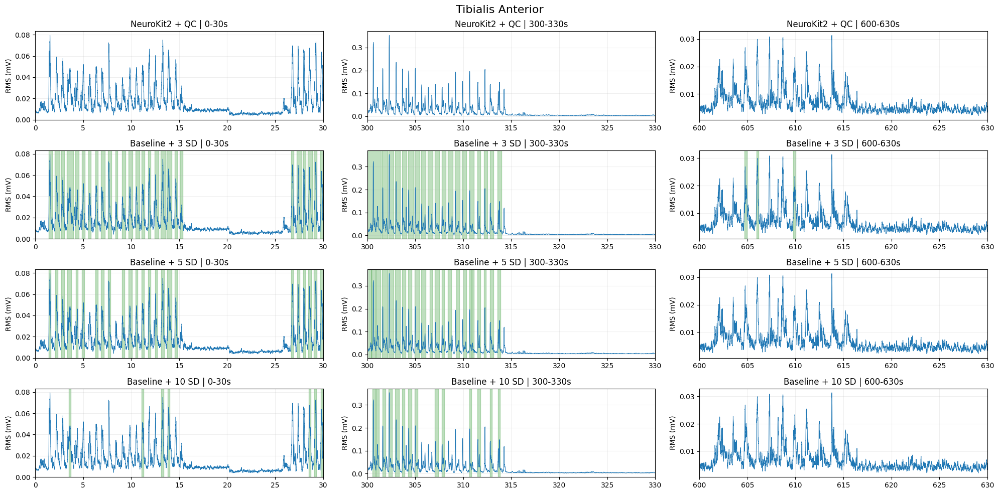

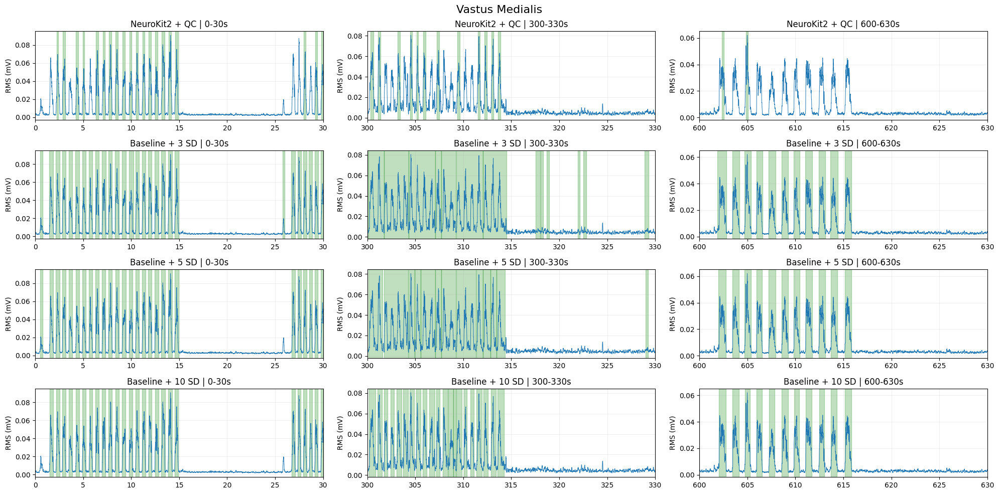

In [232]:
windows = [
    (0, 30),
    (300, 330),
    (600, 630)
]

for muscle in test_muscles:

    result = full_recording_results[muscle]

    t = result["time"]
    rms = result["rms"]

    methods = {
        "NeuroKit2 + QC": result["accepted_bursts"]
    }

    for k in [3, 5, 10]:

        methods[f"Baseline + {k} SD"] = (
            alternative_results[(muscle, k)]
            ["accepted_bursts"]
        )

    fig, axes = plt.subplots(
        4, 3,
        figsize=(20, 10)
    )

    for i, (method, bursts) in enumerate(
        methods.items()
    ):

        for j, (start, end) in enumerate(windows):

            ax = axes[i, j]

            mask = (t >= start) & (t < end)

            ax.plot(
                t[mask],
                rms[mask],
                linewidth=0.7
            )

            for onset, offset in bursts:

                if onset < end and offset > start:

                    ax.axvspan(
                        max(onset, start),
                        min(offset, end),
                        color="green",
                        alpha=0.25
                    )

            ax.set_xlim(start, end)
            ax.set_title(f"{method} | {start}-{end}s")
            ax.set_ylabel("RMS (mV)")
            ax.grid(alpha=0.2)

    fig.suptitle(muscle, fontsize=16)

    plt.tight_layout()
    plt.show()

In [233]:
print(rejection_summary_df.to_string())

print(rejected_duration_summary.round(2).to_string())

print(full_method_comparison_df.round(4).to_string(index=False))

Rejection_Reason      Artifact overlap  Insufficient duration
Muscle                                                       
Medial Gastrocnemius                 1                      0
Rectus Femoris                       0                     45
Soleus                               1                      0
Tibialis Anterior                    0                    284
Vastus Medialis                      0                    274
                      count     mean    std      min      25%      50%      75%      max
Muscle                                                                                  
Medial Gastrocnemius    1.0  1808.93    NaN  1808.93  1808.93  1808.93  1808.93  1808.93
Rectus Femoris         45.0    95.91  37.27    50.74    68.89    83.79   115.91   181.08
Soleus                  1.0  1025.50    NaN  1025.50  1025.50  1025.50  1025.50  1025.50
Tibialis Anterior     284.0   108.34  32.16    50.27    83.56   106.13   136.51   195.04
Vastus Medialis       274.0   13

In [234]:
muscle_detection_config["Tibialis Anterior"] = {
    "method": "baseline",
    "k": 5,
    "min_duration_ms": 200
}

muscle_detection_config["Vastus Medialis"] = {
    "method": "baseline",
    "k": 10,
    "min_duration_ms": 200
}

display(pd.DataFrame(muscle_detection_config).T)

,method,k,min_duration_ms
Soleus,baseline,10,200
Tibialis Anterior,baseline,5,200
Medial Gastrocnemius,baseline,5,200
Vastus Medialis,baseline,10,200
Rectus Femoris,neurokit,NaN,200


In [235]:
updated_muscles = [
    "Tibialis Anterior",
    "Vastus Medialis"
]

for muscle in updated_muscles:

    time_col, emg_col = muscle_columns[muscle]

    full_recording_results[muscle] = (
        process_full_emg_channel(
            raw=emg_data[emg_col].to_numpy(),
            time=emg_data[time_col].to_numpy(),
            muscle=muscle,
            config=full_config,
            detection_config=muscle_detection_config[muscle]
        )
    )

    print(
        muscle,
        "| Accepted bursts:",
        len(full_recording_results[muscle]["accepted_bursts"])
    )

    gc.collect()

Tibialis Anterior | Accepted bursts: 350
Vastus Medialis | Accepted bursts: 542


In [236]:
full_features_df = pd.concat(
    [
        result["features"]
        for result in full_recording_results.values()
    ],
    ignore_index=True
)

full_rejected_df = pd.concat(
    [
        result["rejected_bursts"]
        for result in full_recording_results.values()
    ],
    ignore_index=True
)

print("Final feature dataset:", full_features_df.shape)

print(
    full_features_df.groupby("Muscle")
    .size()
    .to_string()
)

Final feature dataset: (2037, 16)
Muscle
Medial Gastrocnemius    390
Rectus Femoris          546
Soleus                  209
Tibialis Anterior       350
Vastus Medialis         542


In [237]:
def identify_activity_blocks(
    features_df,
    max_gap_s=3.0
):

    intervals = (
        features_df[["Onset_s", "Offset_s"]]
        .sort_values("Onset_s")
        .to_numpy()
    )

    blocks = []

    if len(intervals) == 0:
        return pd.DataFrame(
            columns=[
                "Block_ID",
                "Start_s",
                "End_s",
                "Duration_s"
            ]
        )

    current_start, current_end = intervals[0]

    for onset, offset in intervals[1:]:

        if onset - current_end <= max_gap_s:

            current_end = max(current_end, offset)

        else:

            blocks.append(
                (current_start, current_end)
            )

            current_start = onset
            current_end = offset

    blocks.append((current_start, current_end))

    blocks_df = pd.DataFrame(
        blocks,
        columns=["Start_s", "End_s"]
    )

    blocks_df.insert(
        0,
        "Block_ID",
        np.arange(1, len(blocks_df) + 1)
    )

    blocks_df["Duration_s"] = (
        blocks_df["End_s"] -
        blocks_df["Start_s"]
    )

    return blocks_df


activity_blocks_df = identify_activity_blocks(
    full_features_df,
    max_gap_s=3.0
)

print("Activity blocks:", len(activity_blocks_df))

display(activity_blocks_df.head(20))

Activity blocks: 41


,Block_ID,Start_s,End_s,Duration_s
0,1,0.525347,15.027140,14.501793
1,2,25.815502,42.137468,16.321966
2,3,50.453002,65.171261,14.718259
3,4,75.573709,90.363657,14.789948
4,5,101.382450,115.051899,13.669448
5,6,125.703399,140.104174,14.400776
6,7,156.832537,172.006071,15.173534
7,8,186.393812,201.524519,15.130707
8,9,215.396933,230.452226,15.055293
9,10,243.227416,257.290692,14.063276


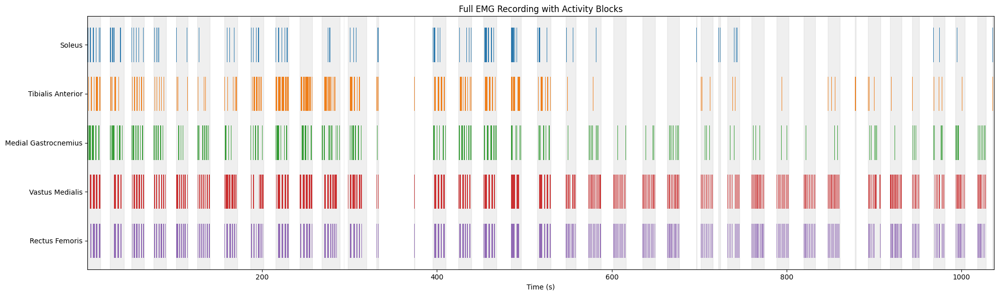

In [238]:
fig, ax = plt.subplots(figsize=(20, 6))

muscles = list(muscle_columns.keys())

for i, muscle in enumerate(muscles):

    bursts = full_features_df[
        full_features_df["Muscle"] == muscle
    ]

    intervals = [
        (row.Onset_s, row.Offset_s - row.Onset_s)
        for row in bursts.itertuples()
    ]

    ax.broken_barh(
        intervals,
        (i - 0.35, 0.7),
        facecolors=plt.cm.tab10.colors[i]
    )

for block in activity_blocks_df.itertuples():

    ax.axvspan(
        block.Start_s,
        block.End_s,
        color="gray",
        alpha=0.12
    )

ax.set_yticks(range(len(muscles)))
ax.set_yticklabels(muscles)
ax.invert_yaxis()

ax.set_xlabel("Time (s)")
ax.set_title("Full EMG Recording with Activity Blocks")

ax.set_xlim(full_time[0], full_time[-1])

plt.tight_layout()
plt.show()

In [239]:
segmented_features_df = full_features_df.copy()

segmented_features_df["Block_ID"] = pd.Series(
    pd.NA,
    index=segmented_features_df.index,
    dtype="Int64"
)

for block in activity_blocks_df.itertuples():

    mask = (
        (segmented_features_df["Onset_s"] >= block.Start_s) &
        (segmented_features_df["Offset_s"] <= block.End_s)
    )

    segmented_features_df.loc[
        mask, "Block_ID"
    ] = block.Block_ID

print(
    "Assigned bursts:",
    segmented_features_df["Block_ID"].notna().sum()
)

print(
    "Unassigned bursts:",
    segmented_features_df["Block_ID"].isna().sum()
)

display(segmented_features_df.head())

Assigned bursts: 2037
Unassigned bursts: 0


,Muscle,Burst_ID,Onset_s,Offset_s,Duration_ms,Peak_RMS_mV,Mean_RMS_mV,Burst_RMS_mV,iEMG_mV_s,Envelope_Area_mV_s,Time_to_Peak_ms,Inter_Burst_Interval_ms,Onset_Interval_ms,Detection_Method,Threshold_mV,Threshold_k,Block_ID
0,Soleus,1,0.525347,0.917778,392.4310,0.028502,0.013524,0.014814,0.004036,0.005311,100.0862,NaN,NaN,baseline,0.005511,10.0,1
1,Soleus,2,1.655623,1.907002,251.3793,0.024279,0.015964,0.016612,0.003117,0.004018,122.4310,737.8449,1130.2759,baseline,0.005511,10.0,1
2,Soleus,3,2.349243,2.587588,238.3449,0.027226,0.015223,0.016469,0.002881,0.003633,121.9656,442.2413,693.6206,baseline,0.005511,10.0,1
3,Soleus,4,3.018192,3.441347,423.1552,0.018718,0.011434,0.011934,0.003862,0.004841,154.5517,430.6034,668.9483,baseline,0.005511,10.0,1
4,Soleus,5,3.694123,3.916174,222.0517,0.014356,0.011461,0.011743,0.002042,0.002548,74.4827,252.7759,675.9311,baseline,0.005511,10.0,1


In [240]:
segmented_features_df = (
    segmented_features_df
    .sort_values(
        ["Muscle", "Block_ID", "Onset_s"]
    )
    .reset_index(drop=True)
)

groups = segmented_features_df.groupby(
    ["Muscle", "Block_ID"]
)

previous_offset = groups["Offset_s"].shift(1)
previous_onset = groups["Onset_s"].shift(1)

segmented_features_df[
    "Within_Block_IBI_ms"
] = (
    segmented_features_df["Onset_s"] -
    previous_offset
) * 1000

segmented_features_df[
    "Within_Block_Onset_Interval_ms"
] = (
    segmented_features_df["Onset_s"] -
    previous_onset
) * 1000

display(
    segmented_features_df[
        [
            "Muscle",
            "Block_ID",
            "Onset_s",
            "Inter_Burst_Interval_ms",
            "Within_Block_IBI_ms"
        ]
    ].head(20)
)

,Muscle,Block_ID,Onset_s,Inter_Burst_Interval_ms,Within_Block_IBI_ms
0,Medial Gastrocnemius,1,0.589123,NaN,NaN
1,Medial Gastrocnemius,1,0.994123,36.3104,36.3104
2,Medial Gastrocnemius,1,1.656088,349.6035,349.6035
3,Medial Gastrocnemius,1,2.374381,219.2586,219.2586
4,Medial Gastrocnemius,1,3.096864,325.3965,325.3965
5,Medial Gastrocnemius,1,3.702968,248.1207,248.1207
6,Medial Gastrocnemius,1,4.491088,459.9311,459.9311
7,Medial Gastrocnemius,1,5.244761,475.7586,475.7586
8,Medial Gastrocnemius,1,5.908123,427.3449,427.3449
9,Medial Gastrocnemius,1,6.592433,369.6207,369.6207


In [241]:
normalization_reference = (
    segmented_features_df
    .groupby("Muscle")["Peak_RMS_mV"]
    .quantile(0.95)
    .rename("Reference_RMS_mV")
    .reset_index()
)

display(normalization_reference)

,Muscle,Reference_RMS_mV
0,Medial Gastrocnemius,0.045120
1,Rectus Femoris,0.125039
2,Soleus,0.026843
3,Tibialis Anterior,0.993268
4,Vastus Medialis,0.083065


In [242]:
normalized_features_df = (
    segmented_features_df.merge(
        normalization_reference,
        on="Muscle",
        how="left"
    )
)

amplitude_columns = [
    "Peak_RMS_mV",
    "Mean_RMS_mV",
    "Burst_RMS_mV"
]

for column in amplitude_columns:

    normalized_column = column.replace(
        "_mV", "_Percent_Reference"
    )

    reference = normalized_features_df[
        "Reference_RMS_mV"
    ].replace(0, np.nan)

    normalized_features_df[normalized_column] = (
        100 *
        normalized_features_df[column] /
        reference
    )

display(normalized_features_df.head())

,Muscle,Burst_ID,Onset_s,Offset_s,Duration_ms,Peak_RMS_mV,Mean_RMS_mV,Burst_RMS_mV,iEMG_mV_s,Envelope_Area_mV_s,...,Detection_Method,Threshold_mV,Threshold_k,Block_ID,Within_Block_IBI_ms,Within_Block_Onset_Interval_ms,Reference_RMS_mV,Peak_RMS_Percent_Reference,Mean_RMS_Percent_Reference,Burst_RMS_Percent_Reference
0,Medial Gastrocnemius,1,0.589123,0.957812,368.6896,0.025884,0.010236,0.012042,0.002752,0.003777,...,baseline,0.004312,5.0,1,NaN,NaN,0.04512,57.366330,22.686397,26.687709
1,Medial Gastrocnemius,2,0.994123,1.306485,312.3620,0.033000,0.013078,0.015602,0.002837,0.004089,...,baseline,0.004312,5.0,1,36.3104,405.0000,0.04512,73.136746,28.983701,34.577635
2,Medial Gastrocnemius,3,1.656088,2.155123,499.0345,0.018859,0.010704,0.011433,0.004023,0.005345,...,baseline,0.004312,5.0,1,349.6035,661.9655,0.04512,41.796333,23.724270,25.339093
3,Medial Gastrocnemius,4,2.374381,2.771468,397.0862,0.031649,0.015193,0.016610,0.004671,0.006038,...,baseline,0.004312,5.0,1,219.2586,718.2931,0.04512,70.144115,33.673032,36.812142
4,Medial Gastrocnemius,5,3.096864,3.454847,357.9828,0.045567,0.018925,0.022070,0.004854,0.006781,...,baseline,0.004312,5.0,1,325.3965,722.4827,0.04512,100.989479,41.942449,48.913875


In [243]:
block_summary_df = (
    normalized_features_df
    .groupby(["Block_ID", "Muscle"])
    .agg(
        Burst_Count=("Burst_ID", "count"),

        Mean_Duration_ms=("Duration_ms", "mean"),

        Mean_Peak_RMS_mV=("Peak_RMS_mV", "mean"),

        Mean_Burst_RMS_mV=("Burst_RMS_mV", "mean"),

        Mean_Normalized_RMS=(
            "Burst_RMS_Percent_Reference", "mean"
        ),

        Total_iEMG_mV_s=("iEMG_mV_s", "sum"),

        Mean_IBI_ms=("Within_Block_IBI_ms", "mean"),

        Total_Active_Time_ms=("Duration_ms", "sum")
    )
    .reset_index()
)

block_summary_df = block_summary_df.merge(
    activity_blocks_df,
    on="Block_ID",
    how="left"
)

block_summary_df["Percent_Active"] = (
    100 *
    block_summary_df["Total_Active_Time_ms"] /
    (1000 * block_summary_df["Duration_s"])
)

display(block_summary_df.head(15))

,Block_ID,Muscle,Burst_Count,Mean_Duration_ms,Mean_Peak_RMS_mV,Mean_Burst_RMS_mV,Mean_Normalized_RMS,Total_iEMG_mV_s,Mean_IBI_ms,Total_Active_Time_ms,Start_s,End_s,Duration_s,Percent_Active
0,1,Medial Gastrocnemius,21,330.650243,0.024635,0.014007,31.044076,0.065649,374.718105,6943.6551,0.525347,15.027140,14.501793,47.881355
1,1,Rectus Femoris,20,357.424140,0.108930,0.063700,50.944336,0.325340,330.541742,7148.4828,0.525347,15.027140,14.501793,49.293786
2,1,Soleus,17,271.588235,0.020658,0.013471,50.183710,0.045075,615.588363,4617.0000,0.525347,15.027140,14.501793,31.837442
3,1,Tibialis Anterior,18,287.224133,0.057154,0.037988,3.824543,0.150255,484.001018,5170.0344,0.525347,15.027140,14.501793,35.651001
4,1,Vastus Medialis,20,361.962925,0.065950,0.040698,48.996113,0.218094,324.980042,7239.2585,0.525347,15.027140,14.501793,49.919748
5,2,Medial Gastrocnemius,22,371.948277,0.027786,0.015186,33.655657,0.087090,387.266010,8182.8621,25.815502,42.137468,16.321966,50.134049
6,2,Rectus Femoris,20,344.203450,0.108781,0.065200,52.143768,0.328984,322.358437,6884.0690,25.815502,42.137468,16.321966,42.176716
7,2,Soleus,16,300.113137,0.020271,0.013135,48.933545,0.045761,518.244833,4801.8102,25.815502,42.137468,16.321966,29.419314
8,2,Tibialis Anterior,19,284.798553,0.063299,0.041088,4.136668,0.166329,421.137928,5411.1725,25.815502,42.137468,16.321966,33.152701
9,2,Vastus Medialis,20,349.161195,0.064138,0.039899,48.033981,0.205111,316.184221,6983.2239,25.815502,42.137468,16.321966,42.784209


In [244]:
normalized_features_df.to_csv(
    f"{output_dir}/EMG_Normalized_Burst_Features.csv",
    index=False
)

activity_blocks_df.to_csv(
    f"{output_dir}/EMG_Activity_Blocks.csv",
    index=False
)

block_summary_df.to_csv(
    f"{output_dir}/EMG_Block_Summary.csv",
    index=False
)

normalization_reference.to_csv(
    f"{output_dir}/EMG_Normalization_References.csv",
    index=False
)

print("Step 36 exports complete.")

Step 36 exports complete.


In [245]:
print("Final burst dataset:", full_features_df.shape)

print("Number of activity blocks:", len(activity_blocks_df))

print(
    "Unassigned bursts:",
    segmented_features_df["Block_ID"].isna().sum()
)

print(
    "\nNormalization references:\n",
    normalization_reference.to_string(index=False)
)

print(
    "\nNormalized dataset:",
    normalized_features_df.shape
)

print(
    "Block summary dataset:",
    block_summary_df.shape
)

Final burst dataset: (2037, 16)
Number of activity blocks: 41
Unassigned bursts: 0

Normalization references:
               Muscle  Reference_RMS_mV
Medial Gastrocnemius          0.045120
      Rectus Femoris          0.125039
              Soleus          0.026843
   Tibialis Anterior          0.993268
     Vastus Medialis          0.083065

Normalized dataset: (2037, 23)
Block summary dataset: (176, 14)


In [246]:
def run_emg_pipeline(
    emg_data,
    muscle_columns,
    full_config,
    muscle_detection_config,
    max_gap_s=3.0,
    normalization_percentile=0.95
):

    results = {}

    # 1. Process all muscle channels
    for muscle, (time_col, emg_col) in muscle_columns.items():

        print(f"Processing {muscle}...")

        results[muscle] = process_full_emg_channel(
            raw=emg_data[emg_col].to_numpy(),
            time=emg_data[time_col].to_numpy(),
            muscle=muscle,
            config=full_config,
            detection_config=muscle_detection_config[muscle]
        )

    # 2. Combine accepted and rejected bursts
    features = pd.concat(
        [r["features"] for r in results.values()],
        ignore_index=True
    )

    rejected = pd.concat(
        [r["rejected_bursts"] for r in results.values()],
        ignore_index=True
    )

    if features.empty:
        raise ValueError("No accepted bursts were detected.")

    # 3. Identify activity blocks
    blocks = identify_activity_blocks(
        features,
        max_gap_s=max_gap_s
    )

    features["Block_ID"] = pd.Series(
        pd.NA,
        index=features.index,
        dtype="Int64"
    )

    for block in blocks.itertuples():

        mask = (
            (features["Onset_s"] >= block.Start_s) &
            (features["Offset_s"] <= block.End_s)
        )

        features.loc[mask, "Block_ID"] = block.Block_ID

    # 4. Calculate within-block intervals
    features = features.sort_values(
        ["Muscle", "Block_ID", "Onset_s"]
    ).reset_index(drop=True)

    groups = features.groupby(["Muscle", "Block_ID"])

    features["Within_Block_IBI_ms"] = (
        features["Onset_s"] -
        groups["Offset_s"].shift(1)
    ) * 1000

    features["Within_Block_Onset_Interval_ms"] = (
        features["Onset_s"] -
        groups["Onset_s"].shift(1)
    ) * 1000

    # 5. Calculate normalization references
    references = (
        features.groupby("Muscle")["Peak_RMS_mV"]
        .quantile(normalization_percentile)
        .rename("Reference_RMS_mV")
        .reset_index()
    )

    features = features.merge(
        references,
        on="Muscle",
        how="left"
    )

    for column in [
        "Peak_RMS_mV",
        "Mean_RMS_mV",
        "Burst_RMS_mV"
    ]:

        normalized_column = column.replace(
            "_mV", "_Percent_Reference"
        )

        features[normalized_column] = (
            100 * features[column] /
            features["Reference_RMS_mV"].replace(0, np.nan)
        )

    # 6. Generate muscle summary
    muscle_summary = []

    for muscle, result in results.items():

        f = result["features"]
        detected = result["detected_count"]
        accepted = len(f)

        duration = (
            result["time"][-1] -
            result["time"][0]
        )

        active_time = f["Duration_ms"].sum() / 1000

        muscle_summary.append({
            "Muscle": muscle,
            "Method": result["method"],
            "Detected_Bursts": detected,
            "Accepted_Bursts": accepted,
            "Rejected_Bursts": len(result["rejected_bursts"]),
            "Retention_Percent":
                100 * accepted / detected if detected else np.nan,
            "Mean_Duration_ms": f["Duration_ms"].mean(),
            "SD_Duration_ms": f["Duration_ms"].std(),
            "Total_Active_Time_s": active_time,
            "Percent_Active": 100 * active_time / duration,
            "Artifact_Percent":
                100 * result["artifact_mask"].mean(),
            "Excluded_Region_Percent":
                100 * result["expanded_artifact_mask"].mean()
        })

    muscle_summary = pd.DataFrame(muscle_summary)

    # 7. Generate block-level summary
    block_summary = (
        features.groupby(["Block_ID", "Muscle"])
        .agg(
            Burst_Count=("Burst_ID", "count"),
            Mean_Duration_ms=("Duration_ms", "mean"),
            Mean_Peak_RMS_mV=("Peak_RMS_mV", "mean"),
            Mean_Burst_RMS_mV=("Burst_RMS_mV", "mean"),
            Mean_Normalized_RMS=(
                "Burst_RMS_Percent_Reference", "mean"
            ),
            Total_iEMG_mV_s=("iEMG_mV_s", "sum"),
            Mean_IBI_ms=("Within_Block_IBI_ms", "mean"),
            Total_Active_Time_ms=("Duration_ms", "sum")
        )
        .reset_index()
        .merge(blocks, on="Block_ID", how="left")
    )

    block_summary["Percent_Active"] = (
        100 * block_summary["Total_Active_Time_ms"] /
        (1000 * block_summary["Duration_s"])
    )

    # 8. Generate artifact summary
    artifact_summary = pd.DataFrame([
        {
            "Muscle": muscle,
            "Total_Samples": len(r["time"]),
            "Flagged_Samples": r["artifact_mask"].sum(),
            "Flagged_Percent": 100 * r["artifact_mask"].mean(),
            "Excluded_Region_Percent":
                100 * r["expanded_artifact_mask"].mean()
        }
        for muscle, r in results.items()
    ])

    print("\nEMG pipeline complete.")

    return {
        "channel_results": results,
        "burst_features": features,
        "rejected_bursts": rejected,
        "muscle_summary": muscle_summary,
        "artifact_summary": artifact_summary,
        "activity_blocks": blocks,
        "block_summary": block_summary,
        "normalization_references": references
    }

In [247]:
import os

def export_pipeline_results(
    pipeline_results,
    output_dir="EMG_Pipeline_Results"
):

    os.makedirs(output_dir, exist_ok=True)

    for name, result in pipeline_results.items():

        if isinstance(result, pd.DataFrame):

            filepath = os.path.join(
                output_dir,
                f"{name}.csv"
            )

            result.to_csv(filepath, index=False)

            print(f"Saved: {filepath}")

In [248]:
import inspect
import os

package_dir = "EMG_Pipeline"

os.makedirs(package_dir, exist_ok=True)

pipeline_functions = [
    detect_bursts,
    extract_emg_features,
    handle_emg_artifacts,
    process_full_emg_channel,
    identify_activity_blocks,
    run_emg_pipeline,
    export_pipeline_results
]

module_imports = """
import os
import numpy as np
import pandas as pd
import neurokit2 as nk

from scipy.signal import butter, sosfiltfilt
from scipy.ndimage import uniform_filter1d, maximum_filter1d
from scipy.integrate import trapezoid
"""

module_path = os.path.join(
    package_dir,
    "emg_pipeline.py"
)

with open(module_path, "w") as f:

    f.write('"""Reusable multichannel EMG processing pipeline."""\n')

    f.write(module_imports)

    for function in pipeline_functions:

        f.write("\n\n")
        f.write(inspect.getsource(function))
        f.write("\n")

print(f"Created: {module_path}")

Created: EMG_Pipeline/emg_pipeline.py


In [249]:
import json

pipeline_config = {
    "muscle_columns": muscle_columns,
    "processing": full_config,
    "muscle_detection": muscle_detection_config,
    "segmentation": {
        "max_gap_s": 3.0
    },
    "normalization": {
        "method": "percentile",
        "percentile": 0.95
    }
}

with open(
    f"{package_dir}/config.json", "w"
) as f:

    json.dump(
        pipeline_config,
        f,
        indent=4
    )

print("Configuration file created.")

Configuration file created.


In [250]:
from importlib.metadata import version

packages = [
    "numpy",
    "pandas",
    "scipy",
    "neurokit2",
    "matplotlib"
]

with open(
    f"{package_dir}/requirements.txt", "w"
) as f:

    for package in packages:

        f.write(
            f"{package}=={version(package)}\n"
        )

print("Requirements file created.")

Requirements file created.


In [252]:
readme = """
# Multichannel EMG Processing Pipeline

## Overview

This pipeline provides a configurable workflow for
processing multichannel surface electromyography (EMG)
recordings and extracting muscle activation features.

## Processing Workflow

1. Raw EMG data loading
2. Artifact identification and masking
3. Butterworth bandpass filtering
4. RMS envelope generation
5. Muscle-specific burst detection
6. Burst quality control
7. Feature extraction
8. Activity block segmentation
9. Amplitude normalization
10. Automated data export

## Input Requirements

- A pandas DataFrame containing EMG and time columns
- Timestamps expressed in seconds
- EMG amplitudes expressed in millivolts
- Consistent sampling intervals
- Synchronized muscle channel timestamps
- A verified resting baseline interval

## Installation

pip install -r requirements.txt

## Usage

Import run_emg_pipeline and export_pipeline_results
from emg_pipeline.py.

Load the processing parameters from config.json.

Review the sampling rate, channel mapping, baseline
interval, and detection parameters for each recording.

Run the pipeline and export the resulting datasets.

## Detection Methods

The pipeline supports:

- NeuroKit2 automatic EMG activation detection
- Baseline-relative RMS threshold detection

Detection methods and thresholds can be configured
independently for each muscle.

## Output Datasets

- Burst-level features
- Rejected burst records
- Muscle-level summaries
- Artifact summaries
- Inferred activity blocks
- Block-level summaries
- Normalization references

## Normalization

EMG amplitude is normalized relative to the 95th
percentile of accepted peak RMS values for each muscle.

These values are recording-relative percentages,
not percentages of maximum voluntary contraction.

## Preliminary Evaluation

The initial rectus femoris pilot included 25 manually
annotated bursts over a 30-second recording segment.

NeuroKit2 with duration-based quality control achieved:

- Precision: 1.00
- Recall: 1.00
- F1 score: 1.00
- Onset MAE: 18.86 ms
- Offset MAE: 16.20 ms
- Duration MAE: 32.80 ms

These results were obtained on the pilot used for
method selection and do not constitute independent
validation.

## Full-Recording Demonstration

- Recording duration: approximately 17.3 minutes
- Muscle channels: 5
- Samples per muscle: 2,228,044
- Accepted bursts: 2,037
- Inferred activity blocks: 41
- Muscle-block observations: 176

## Limitations

- Detection parameters require independent validation.
- The 200 ms duration criterion may exclude genuine
  short muscle activations.
- Baseline noise may vary throughout a recording.
- Amplitude-based artifact screening does not detect
  all motion artifacts or signal contamination.
- Interpolated artifact regions are excluded from
  accepted burst features using an expanded mask.
- Activity blocks are inferred, not experimental trials.
- Recording-relative normalization is not MVC normalization.
- Tibialis anterior amplitudes require additional review.
- Detection methods differ between muscles, which may
  affect comparisons of activation timing and duration.
- Block summaries contain observed muscle-block pairs;
  missing pairs should not automatically be treated as zero.

## Future Development

- Independent multichannel manual validation
- Behavioral data synchronization
- Muscle coordination and coactivation analysis
- EEG-EMG integration
- Cross-participant evaluation
"""

with open(
    f"{package_dir}/README.md", "w"
) as f:

    f.write(readme)

print("README created.")

README created.


In [253]:
import sys
import importlib

sys.path.insert(
    0,
    os.path.abspath(package_dir)
)

import emg_pipeline

importlib.reload(emg_pipeline)

print("Module imported successfully.")

Module imported successfully.


In [254]:
with open(
    f"{package_dir}/config.json", "r"
) as f:

    config = json.load(f)

final_results = emg_pipeline.run_emg_pipeline(
    emg_data=emg_data,
    muscle_columns=config["muscle_columns"],
    full_config=config["processing"],
    muscle_detection_config=config["muscle_detection"],
    max_gap_s=config["segmentation"]["max_gap_s"],
    normalization_percentile=(
        config["normalization"]["percentile"]
    )
)

Processing Soleus...
Processing Tibialis Anterior...
Processing Medial Gastrocnemius...
Processing Vastus Medialis...
Processing Rectus Femoris...

EMG pipeline complete.


In [255]:
expected_counts = {
    "Soleus": 209,
    "Tibialis Anterior": 350,
    "Medial Gastrocnemius": 390,
    "Vastus Medialis": 542,
    "Rectus Femoris": 546
}

actual_counts = (
    final_results["burst_features"]
    .groupby("Muscle")
    .size()
    .to_dict()
)

assert actual_counts == expected_counts

assert len(final_results["activity_blocks"]) == 41

assert len(final_results["block_summary"]) == 176

assert final_results["burst_features"]["Block_ID"].isna().sum() == 0

pd.testing.assert_frame_equal(
    final_results["burst_features"]
    .sort_values(["Muscle", "Onset_s"])
    .reset_index(drop=True)
    .sort_index(axis=1),

    normalized_features_df
    .sort_values(["Muscle", "Onset_s"])
    .reset_index(drop=True)
    .sort_index(axis=1),

    check_dtype=False,
    rtol=1e-7,
    atol=1e-9
)

print("All reproducibility checks passed.")

All reproducibility checks passed.


In [256]:
emg_pipeline.export_pipeline_results(
    final_results,
    output_dir=f"{package_dir}/results"
)

Saved: EMG_Pipeline/results/burst_features.csv
Saved: EMG_Pipeline/results/rejected_bursts.csv
Saved: EMG_Pipeline/results/muscle_summary.csv
Saved: EMG_Pipeline/results/artifact_summary.csv
Saved: EMG_Pipeline/results/activity_blocks.csv
Saved: EMG_Pipeline/results/block_summary.csv
Saved: EMG_Pipeline/results/normalization_references.csv


In [257]:
import nbformat as nbf

nb = nbf.v4.new_notebook()

nb.cells = [

    nbf.v4.new_markdown_cell(
        "# EMG Processing Pipeline\n"
        "Demonstration of multichannel EMG processing."
    ),

    nbf.v4.new_code_cell(
        "import pandas as pd\n"
        "import numpy as np\n"
        "import json\n"
        "from emg_pipeline import "
        "run_emg_pipeline, export_pipeline_results"
    ),

    nbf.v4.new_markdown_cell(
        "## Load EMG data\n"
        "Replace the filename with your own EMG CSV file. "
        "Verify that time is in seconds and EMG is in mV."
    ),

    nbf.v4.new_code_cell(
        'emg_data = pd.read_csv("your_emg_data.csv")\n'
        "display(emg_data.head())"
    ),

    nbf.v4.new_markdown_cell(
        "## Load and review configuration\n"
        "Verify the channel names, resting baseline, "
        "artifact threshold, and detection parameters "
        "for the new recording."
    ),

    nbf.v4.new_code_cell(
        'with open("config.json", "r") as f:\n'
        '    config = json.load(f)\n\n'
        'time_col = next(iter(config["muscle_columns"].values()))[0]\n'
        'config["processing"]["sampling_rate"] = float(\n'
        '    1 / np.median(np.diff(emg_data[time_col]))\n'
        ')\n'
        'print(json.dumps(config, indent=2))'
    ),

    nbf.v4.new_markdown_cell(
        "## Run pipeline\n"
        "Only proceed after confirming that the baseline "
        "interval and processing parameters are appropriate."
    ),

    nbf.v4.new_code_cell(
        "results = run_emg_pipeline(\n"
        "    emg_data=emg_data,\n"
        '    muscle_columns=config["muscle_columns"],\n'
        '    full_config=config["processing"],\n'
        '    muscle_detection_config=config["muscle_detection"],\n'
        '    max_gap_s=config["segmentation"]["max_gap_s"],\n'
        '    normalization_percentile=config["normalization"]["percentile"]\n'
        ")"
    ),

    nbf.v4.new_code_cell(
        'display(results["muscle_summary"])\n'
        'display(results["burst_features"].head())\n'
        'display(results["activity_blocks"].head())'
    ),

    nbf.v4.new_markdown_cell(
        "## Export results"
    ),

    nbf.v4.new_code_cell(
        'export_pipeline_results(results, "results")'
    )
]

with open(
    f"{package_dir}/EMG_Demo.ipynb", "w"
) as f:

    nbf.write(nb, f)

print("Demonstration notebook created.")

Demonstration notebook created.


In [258]:
import shutil
from google.colab import files

shutil.make_archive(
    "EMG_Pipeline",
    "zip",
    root_dir=package_dir
)

files.download("EMG_Pipeline.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>